# TP — Transfer Learning et Apprentissage Multitâche
**M2 SDIA — Advanced Artificial Intelligence · ENSET**

Ce notebook regroupe les **trois exercices** du TP dans un seul fichier, avec pour chaque exercice : l'objectif, le code, les résultats, puis un bloc **Analyse** qui interprète les chiffres obtenus.

| Partie | Contenu | Données |
|---|---|---|
| **1 — Exercice 1** | Fleurs : CNN de zéro vs extraction de caractéristiques vs fine-tuning, effet de la quantité de données, prétraitement | `flower_photos`, 160×160 |
| **2 — Exercice 2** | Choix d'un backbone (VGG16, ResNet50, MobileNetV2, EfficientNetB0) : précision / latence / taille, t-SNE, Top-5 ImageNet | `flower_photos`, 224×224 |
| **3 — Exercice 3** | Apprentissage multitâche (catégorie + famille) : mono vs multi, pondération λ, peu de données, cohérence | Fashion-MNIST |
| **4 — Synthèse** | Tableau récapitulatif, réponses aux 6 questions transversales, recommandations, limites | — |



---
# Partie 1 — Exercice 1 : Identification de fleurs avec Transfer Learning

**Contexte.** Une start-up veut identifier l'espèce d'une fleur à partir d'une photo, avec seulement quelques milliers d'images annotées : trop peu pour entraîner un CNN profond de zéro.

**Données.** `flower_photos` : 3 670 images, 5 classes (marguerite, pissenlit, rose, tournesol, tulipe), redimensionnées en 160×160, découpage 80 % / 20 %.

**Objectifs.**
1. Charger les données, visualiser des exemples et la répartition des classes.
2. Entraîner un **CNN de référence** (architecture `blocs4` du TP3) depuis zéro, avec augmentation de données.
3. **Extraction de caractéristiques** avec MobileNetV2 gelé.
4. **Fine-tuning** des 30 dernières couches, courbes continues.
5. Effet de la **quantité de données** (5 %, 10 %, 25 %, 50 %, 100 %).
6. Effet de l'**oubli de `preprocess_input`** à l'inférence.

> L'entraînement peut être long sur CPU. Exécuter les cellules dans l'ordre.

## 1.0 Imports et paramètres

L'architecture du CNN reprend les paramètres de `blocs4` : `filters=(32, 64, 64, 64)`, noyau 3×3, MaxPooling2D, Flatten, Dense(128), Dropout(0.3), Adam à 1e-3.  
Adaptations nécessaires pour cet exercice : entrée RGB `(160, 160, 3)` et une seule sortie softmax à 5 classes (au lieu des sorties `posk` du TP3).

In [1]:
import pathlib
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
IMG_H, IMG_W = 160, 160
BATCH_SIZE = 32
N_CLASSES = 5
EPOCHS_CNN = 10       # 10 époques pour garder le même ordre de grandeur que l'énoncé
EPOCHS_HEAD = 10
EPOCHS_FINE = 10
LR_HEAD = 1e-3
LR_FINE = 1e-5

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
GPU : []


## 1.1 Télécharger les données et préparer entraînement / validation

Le dataset contient les images rangées dans un dossier par classe. On crée une séparation stratifiée 80/20 : chaque classe garde approximativement la même proportion dans les deux jeux.

Les images sont redimensionnées en 160×160. Pour le CNN, les pixels restent dans [0, 255] puis une couche `Rescaling(1./255)` les convertit en [0, 1]. Pour MobileNetV2, on appliquera `preprocess_input`, qui convertit les pixels de [0, 255] vers [-1, 1].

In [2]:
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = tf.keras.utils.get_file("flower_photos.tgz", origin=url, extract=True)

root = pathlib.Path(archive).parent
# Trouver le dossier flower_photos, qui contient les dossiers des classes
candidates = [p for p in root.rglob("flower_photos") if p.is_dir()]
data_dir = candidates[0] if candidates else next(p.parent for p in root.rglob("daisy") if p.is_dir())

class_names = sorted([p.name for p in data_dir.iterdir() if p.is_dir()])
print("Dossier :", data_dir)
print("Classes :", class_names)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
paths, labels = [], []
for class_id, class_name in enumerate(class_names):
    for p in (data_dir / class_name).rglob("*"):
        if p.suffix.lower() in image_extensions:
            paths.append(str(p))
            labels.append(class_id)

paths = np.array(paths)
labels = np.array(labels)
print("Nombre total d'images :", len(paths))
print("Nombre de classes :", len(class_names))
assert len(class_names) == N_CLASSES, f"On attend 5 classes, trouvé : {len(class_names)}"

train_paths, val_paths, y_train, y_val = train_test_split(
    paths, labels, test_size=0.20, random_state=SEED, stratify=labels
)
print(f"Entraînement : {len(train_paths)} images ({len(train_paths)/len(paths):.1%})")
print(f"Validation   : {len(val_paths)} images ({len(val_paths)/len(paths):.1%})")

Dossier : C:\Users\hp\.keras\datasets\flower_photos
Classes : ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Nombre total d'images : 3670
Nombre de classes : 5
Entraînement : 2936 images (80.0%)
Validation   : 734 images (20.0%)


> **Analyse — Données**
> - 3 670 images, 5 classes, découpage **stratifié** : 2 936 en entraînement, 734 en validation. La stratification garantit que chaque classe garde la même proportion dans les deux jeux.
> - **Précision statistique de la validation.** Avec 734 images et une accuracy d'environ 90 %, l'erreur-type est √(0,9 × 0,1 / 734) ≈ **1,1 point** (intervalle à 95 % ≈ ± 2,2 points). Conséquence importante pour toute la suite : **un écart inférieur à ~2 points entre deux modèles, mesuré sur une seule exécution, n'est pas concluant.** À l'inverse, les écarts de 15 à 35 points observés entre CNN de zéro et transfert sont, eux, très nets.

### 1.1.1 Répartition des classes

Le graphique permet de voir si certaines classes ont plus d'images que d'autres.

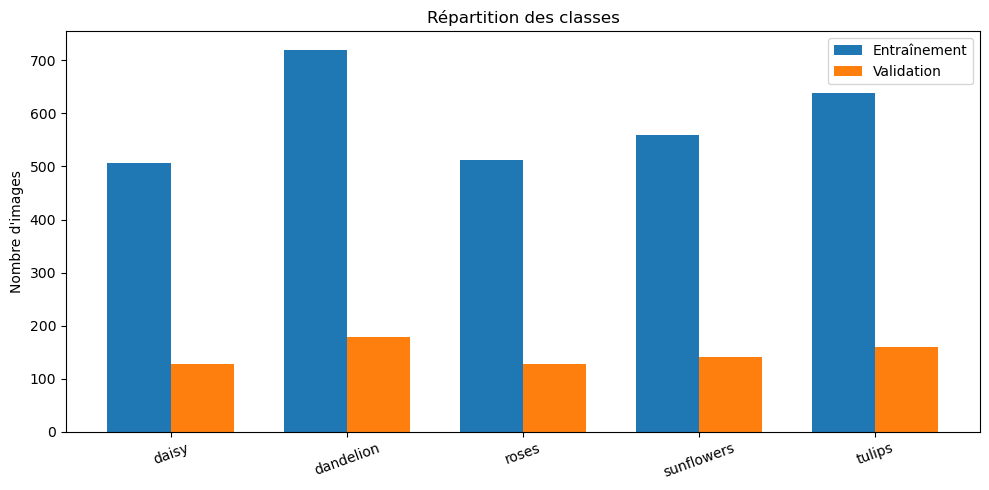

In [3]:
train_counts = [int(np.sum(y_train == i)) for i in range(N_CLASSES)]
val_counts = [int(np.sum(y_val == i)) for i in range(N_CLASSES)]

x = np.arange(N_CLASSES)
plt.figure(figsize=(10, 5))
plt.bar(x - 0.18, train_counts, width=0.36, label="Entraînement")
plt.bar(x + 0.18, val_counts, width=0.36, label="Validation")
plt.xticks(x, class_names, rotation=20)
plt.ylabel("Nombre d'images")
plt.title("Répartition des classes")
plt.legend()
plt.tight_layout()
plt.show()

> **Analyse — Répartition des classes**
> - Effectifs totaux : pissenlit 898, tulipe 799, tournesol 699, rose 641, marguerite 633. Le rapport entre la plus grande et la plus petite classe est d'environ **1,4**, donc un **déséquilibre modéré**.
> - Un classifieur qui prédirait toujours « pissenlit » obtiendrait ≈ 24,5 % ; le hasard uniforme donne 20 %. Ce sont les **valeurs de référence à dépasser**.
> - Le déséquilibre est assez faible pour que l'accuracy reste une métrique acceptable, mais on complète par la **précision / rappel / F1 par classe** (section 1.6) pour vérifier qu'aucune classe n'est sacrifiée.

### 1.1.2 Créer les pipelines `tf.data`

On charge les images à partir de leurs chemins, puis on les redimensionne. L'augmentation de données sera appliquée **uniquement pendant l'entraînement** et uniquement aux modèles qui en ont besoin.

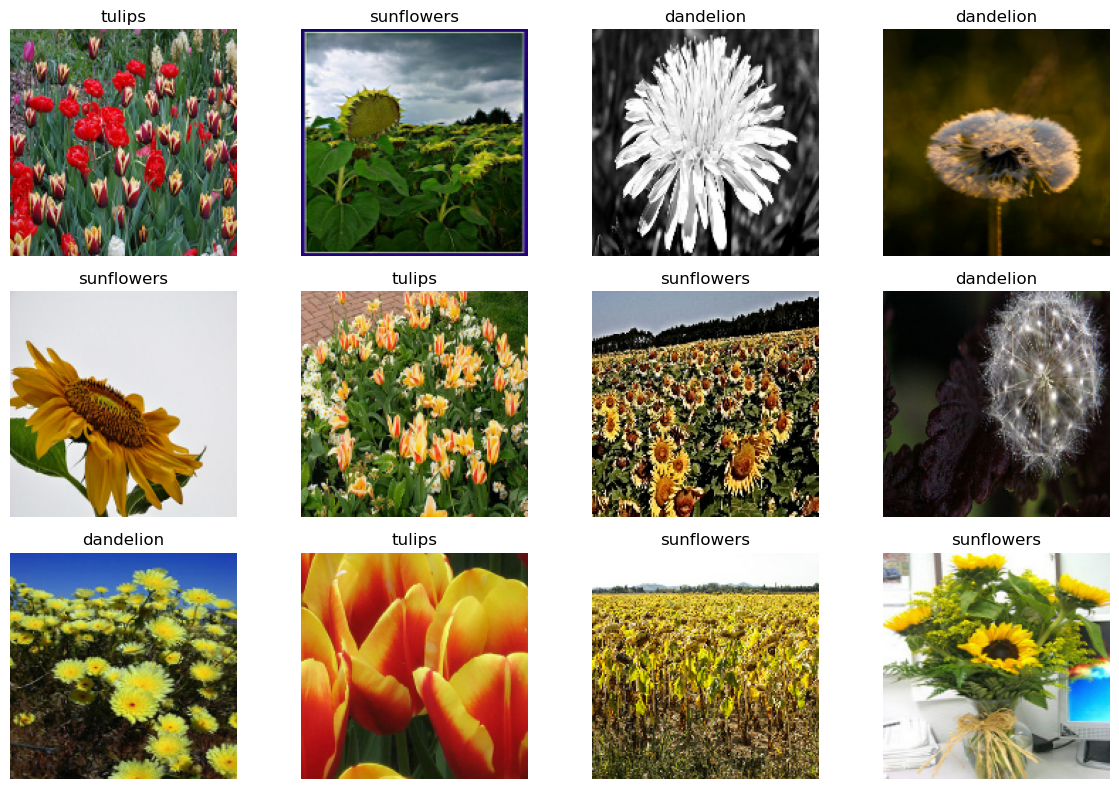

In [4]:
AUTOTUNE = tf.data.AUTOTUNE

def decode_resize(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_H, IMG_W])
    return image, label

def make_dataset(file_paths, file_labels, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))
    if training:
        ds = ds.shuffle(len(file_paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, y_train, training=True)
val_ds = make_dataset(val_paths, y_val, training=False)

# Visualiser quelques images avec leur étiquette
plt.figure(figsize=(12, 8))
for images, labels_batch in train_ds.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8).numpy())
        plt.title(class_names[int(labels_batch[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

> **Analyse — Aperçu des images**
> - Les photos sont **hétérogènes** : cadrage, éclairage, arrière-plan et distance varient fortement ; certaines montrent une fleur isolée, d'autres un bouquet, un vase ou une main.
> - Le redimensionnement en 160×160 (`tf.image.resize` sans conservation du rapport d'aspect) **déforme légèrement** les images non carrées. C'est acceptable ici, mais c'est une source de décalage entre l'entraînement et des photos de smartphone en format 4:3 ou 16:9.
> - Cette variabilité de contexte (vase, jardin, intérieur) annonce les résultats de l'exercice 2 : un modèle pré-entraîné sur ImageNet peut se laisser guider par le **contexte** plutôt que par la fleur.

## 1.2 CNN de référence — architecture `blocs4` du TP3

Le CNN est entraîné **à partir de zéro** : aucun poids pré-entraîné. On garde la structure `blocs4` du TP3, mais on adapte :
- l'entrée à trois canaux RGB ;
- la sortie à une seule classification parmi les cinq fleurs ;
- la loss à `SparseCategoricalCrossentropy`, car les étiquettes sont des entiers de 0 à 4.

L'augmentation est incluse dans le modèle : retournement horizontal, rotation légère et zoom. Elle s'active pendant l'entraînement seulement.

In [5]:
def build_cnn_blocs4(lr=1e-3, dense=128, drop=0.3):
    inputs = keras.Input(shape=(IMG_H, IMG_W, 3), name="image")

    # Augmentation de données, active pendant l'entraînement
    x = layers.RandomFlip("horizontal", seed=SEED, name="aug_flip")(inputs)
    x = layers.RandomRotation(0.08, seed=SEED, name="aug_rotation")(x)
    x = layers.RandomZoom(0.10, seed=SEED, name="aug_zoom")(x)

    # Normalisation des pixels pour le CNN créé de zéro
    x = layers.Rescaling(1./255, name="rescaling")(x)

    # Architecture blocs4 du TP3 : filtres (32, 64, 64, 64), noyau 3, MaxPooling
    for i, f in enumerate((32, 64, 64, 64), start=1):
        x = layers.Conv2D(f, 3, padding="same", activation="relu", name=f"conv{i}")(x)
        x = layers.MaxPooling2D(2, name=f"pool{i}")(x)

    x = layers.Flatten(name="flatten")(x)
    x = layers.Dense(dense, activation="relu", name="dense_cnn")(x)
    if drop:
        x = layers.Dropout(drop, name="dropout")(x)

    outputs = layers.Dense(N_CLASSES, activation="softmax", name="flower")(x)
    model = keras.Model(inputs, outputs, name="cnn_blocs4")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )
    return model

cnn = build_cnn_blocs4()
cnn.summary()

Model: "cnn_blocs4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_flip (RandomFlip)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_rotation (RandomRotation)   │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_zoom (RandomZoom)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 40, 40, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 20, 20, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_cnn (Dense)               │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flower (Dense)                  │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 913,221 (3.48 MB)

 Trainable params: 913,221 (3.48 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history_cnn = cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN
)

cnn_val_loss, cnn_val_acc = cnn.evaluate(val_ds, verbose=0)
print(f"CNN blocs4 — validation accuracy : {cnn_val_acc:.4f}")
print(f"CNN blocs4 — validation loss     : {cnn_val_loss:.4f}")

Epoch 1/10


c:\Users\hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 295ms/step - accuracy: 0.4322 - loss: 1.3132 - val_accuracy: 0.5395 - val_loss: 1.0799
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 272ms/step - accuracy: 0.5644 - loss: 1.0571 - val_accuracy: 0.6253 - val_loss: 0.9592
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 30s 329ms/step - accuracy: 0.6097 - loss: 0.9717 - val_accuracy: 0.5926 - val_loss: 0.9888
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 43s 462ms/step - accuracy: 0.6465 - loss: 0.8836 - val_accuracy: 0.6567 - val_loss: 0.9228
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 41s 450ms/step - accuracy: 0.6832 - loss: 0.8210 - val_accuracy: 0.7044 - val_loss: 0.8261
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 40s 439ms/step - accuracy: 0.6941 - loss: 0.7798 - val_accuracy: 0.6703 - val_loss: 0.9033
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 41s 447ms/step - accuracy: 0.7091 - loss: 0.7489 - val_accuracy: 0.6785 - val_loss: 0.8862
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 42s 457ms/step - accuracy: 0.7268 - loss: 0.7196 - val_accuracy: 0.681

### Courbes du CNN de référence

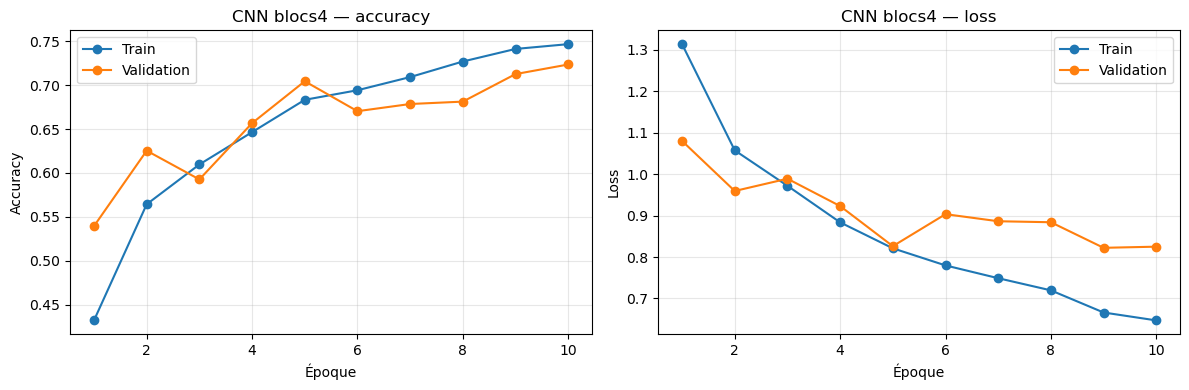

In [7]:
def plot_history(history, title, offset=0):
    h = history.history
    epochs = np.arange(1 + offset, len(h["loss"]) + 1 + offset)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, h["accuracy"], marker="o", label="Train")
    plt.plot(epochs, h["val_accuracy"], marker="o", label="Validation")
    plt.xlabel("Époque")
    plt.ylabel("Accuracy")
    plt.title(title + " — accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, h["loss"], marker="o", label="Train")
    plt.plot(epochs, h["val_loss"], marker="o", label="Validation")
    plt.xlabel("Époque")
    plt.ylabel("Loss")
    plt.title(title + " — loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_history(history_cnn, "CNN blocs4")

> **Analyse — CNN `blocs4` depuis zéro**
> - **Résultat** : accuracy de validation **72,3 %** (loss 0,825) après 10 époques, pour 913 221 paramètres tous entraînés.
> - **Pas de sur-apprentissage, mais un sous-apprentissage** : l'accuracy d'entraînement (74,7 %, mesurée avec augmentation et dropout actifs) est quasi égale à celle de validation, et **les deux courbes montent encore à la dernière époque**. Le modèle n'a pas convergé : 10 époques sont insuffisantes pour apprendre des filtres depuis zéro.
> - **Courbe de validation bruitée** (62,5 % → 59,3 % → 65,7 % → 70,4 %…) : effet combiné d'un petit jeu de validation, d'un learning rate de 10⁻³ et d'un apprentissage « à partir de rien ».
> - **Ordre de grandeur utile** : 913 000 paramètres pour 2 936 images, soit plus de 300 paramètres par image. Sans l'augmentation de données, ce modèle sur-apprendrait vite ; avec, il apprend lentement.
> - Ce modèle est notre **plancher de référence** : tout ce qui suit se mesure par rapport à ces 72 %.

## 1.3 Feature Extraction avec MobileNetV2 gelé

On charge MobileNetV2 avec les poids ImageNet et `include_top=False`. Le tronc est gelé : seuls les poids de la nouvelle tête changent. Le prétraitement MobileNetV2 doit être appliqué aux images avant le tronc.

In [8]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def prepare_mobilenet(image, label):
    # image arrive dans [0, 255] ; preprocess_input convertit vers [-1, 1]
    return preprocess_input(image), label

train_mnet_ds = train_ds.map(prepare_mobilenet, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_mnet_ds = val_ds.map(prepare_mobilenet, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_H, IMG_W, 3)
)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_H, IMG_W, 3), name="image_mobilenet")
# training=False garde le comportement d'inférence des couches BatchNormalization
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.2, name="dropout")(x)
outputs = layers.Dense(N_CLASSES, activation="softmax", name="flower")(x)

mnet = keras.Model(inputs, outputs, name="mobilenetv2_feature_extraction")
mnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_HEAD),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

mnet.summary()
trainable = int(np.sum([tf.size(v).numpy() for v in mnet.trainable_weights]))
non_trainable = int(np.sum([tf.size(v).numpy() for v in mnet.non_trainable_weights]))
print("Paramètres entraînables     :", f"{trainable:,}")
print("Paramètres non entraînables :", f"{non_trainable:,}")

Model: "mobilenetv2_feature_extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_mobilenet (InputLayer)    │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flower (Dense)                  │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Paramètres entraînables     : 6,405
Paramètres non entraînables : 2,257,984


Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 45s 363ms/step - accuracy: 0.6744 - loss: 0.8927 - val_accuracy: 0.8420 - val_loss: 0.4759
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 32s 338ms/step - accuracy: 0.8566 - loss: 0.4167 - val_accuracy: 0.8733 - val_loss: 0.3865
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 30s 329ms/step - accuracy: 0.8924 - loss: 0.3129 - val_accuracy: 0.8828 - val_loss: 0.3576
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 31s 336ms/step - accuracy: 0.9063 - loss: 0.2708 - val_accuracy: 0.8801 - val_loss: 0.3419
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 268ms/step - accuracy: 0.9240 - loss: 0.2281 - val_accuracy: 0.8815 - val_loss: 0.3266
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 316ms/step - accuracy: 0.9336 - loss: 0.2067 - val_accuracy: 0.8869 - val_loss: 0.3247
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 31s 336ms/step - accuracy: 0.9404 - loss: 0.1880 - val_accuracy: 0.8896 - val_loss: 0.3274
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 32s 346ms/step - accuracy: 0.9482 - loss: 0.1633 - val_accu

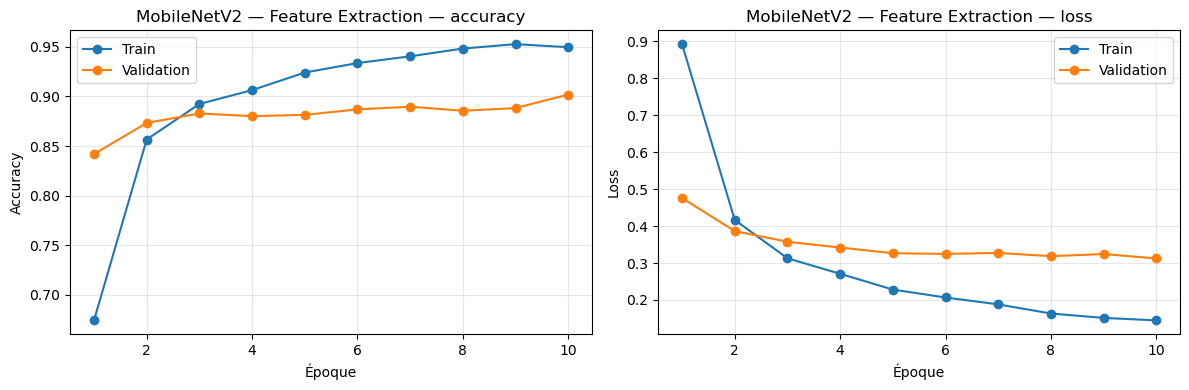

In [9]:
history_head = mnet.fit(
    train_mnet_ds,
    validation_data=val_mnet_ds,
    epochs=EPOCHS_HEAD
)

head_val_loss, head_val_acc = mnet.evaluate(val_mnet_ds, verbose=0)
print(f"Feature Extraction — validation accuracy : {head_val_acc:.4f}")
print(f"Feature Extraction — validation loss     : {head_val_loss:.4f}")
plot_history(history_head, "MobileNetV2 — Feature Extraction")

Sauvegarde en mémoire des poids obtenus **après l'extraction de caractéristiques** : elle servira plus loin pour l'expérience complémentaire (section 1.4b), qui doit repartir du même point de départ pour chaque configuration de fine-tuning.

In [10]:
# Poids du modèle MobileNetV2 + tête entraînée (avant dégel) : point de départ commun des expériences de fine-tuning
weights_after_head = mnet.get_weights()
print("Poids sauvegardés en mémoire :", len(weights_after_head), "tenseurs")

Poids sauvegardés en mémoire : 262 tenseurs


> **Analyse — Extraction de caractéristiques (MobileNetV2 gelé)**
> - **Paramètres** : 2 264 389 au total, dont seulement **6 405 entraînables** (la couche `Dense(5)` : 1 280 × 5 + 5), soit **0,28 %**. Les 2 257 984 autres sont gelés. On entraîne 140 fois moins de paramètres que le CNN de référence.
> - **Résultat** : **90,2 %** de validation (loss 0,312), contre 72,3 % pour le CNN de zéro, soit **+17,9 points** avec une tête minuscule.
> - **Vitesse de convergence** : dès la **1ʳᵉ époque**, la validation atteint 84,2 %, alors que le CNN de zéro est à 53,9 % à la même époque. Les caractéristiques ImageNet sont déjà presque linéairement séparables pour les fleurs : la tête n'a presque rien à apprendre.
> - **Plateau** : la validation stagne vers 88–90 % dès l'époque 3, alors que l'entraînement monte à 95 % (dropout actif). Cet écart de ~5 points indique que **le facteur limitant est la qualité des caractéristiques**, pas la capacité de la tête : ajouter des couches denses n'aiderait pas.
> - **Coût** : une époque prend encore ~20 à 25 s, car le tronc gelé est recalculé à chaque passage. L'approche de l'exercice 2 (extraire les vecteurs **une fois** puis entraîner une tête sur ces vecteurs) serait beaucoup plus rapide.

## 1.4 Fine-tuning : dégeler les 30 dernières couches du tronc

On part du modèle déjà entraîné en Feature Extraction. On dégèle les 30 dernières couches de MobileNetV2, mais on garde les couches BatchNormalization gelées pour rendre l'entraînement plus stable sur un petit dataset. Ensuite, il est indispensable de recompiler avec un faible learning rate `1e-5`.

In [11]:
base_model.trainable = True

# Tout geler d'abord, puis dégeler les 30 dernières couches
for layer in base_model.layers:
    layer.trainable = False
for layer in base_model.layers[-30:]:
    # Pratique courante : conserver BatchNormalization gelé
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

mnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_FINE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

mnet.summary()
trainable_ft = int(np.sum([tf.size(v).numpy() for v in mnet.trainable_weights]))
non_trainable_ft = int(np.sum([tf.size(v).numpy() for v in mnet.non_trainable_weights]))
print("Fine-tuning — paramètres entraînables     :", f"{trainable_ft:,}")
print("Fine-tuning — paramètres non entraînables :", f"{non_trainable_ft:,}")

Model: "mobilenetv2_feature_extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_mobilenet (InputLayer)    │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flower (Dense)                  │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 1,517,125 (5.79 MB)

 Non-trainable params: 747,264 (2.85 MB)

Fine-tuning — paramètres entraînables     : 1,517,125
Fine-tuning — paramètres non entraînables : 747,264


In [12]:
history_fine = mnet.fit(
    train_mnet_ds,
    validation_data=val_mnet_ds,
    epochs=EPOCHS_FINE
)

fine_val_loss, fine_val_acc = mnet.evaluate(val_mnet_ds, verbose=0)
print(f"Fine-tuning — validation accuracy : {fine_val_acc:.4f}")
print(f"Fine-tuning — validation loss     : {fine_val_loss:.4f}")

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 31s 285ms/step - accuracy: 0.9571 - loss: 0.1331 - val_accuracy: 0.8978 - val_loss: 0.3188
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 26s 282ms/step - accuracy: 0.9748 - loss: 0.0881 - val_accuracy: 0.9087 - val_loss: 0.3053
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 311ms/step - accuracy: 0.9792 - loss: 0.0706 - val_accuracy: 0.8910 - val_loss: 0.3129
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 315ms/step - accuracy: 0.9843 - loss: 0.0608 - val_accuracy: 0.9019 - val_loss: 0.3148
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 37s 274ms/step - accuracy: 0.9905 - loss: 0.0460 - val_accuracy: 0.9087 - val_loss: 0.2994
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 275ms/step - accuracy: 0.9911 - loss: 0.0383 - val_accuracy: 0.9087 - val_loss: 0.3069
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 264ms/step - accuracy: 0.9935 - loss: 0.0295 - val_accuracy: 0.9046 - val_loss: 0.3155
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 32s 342ms/step - accuracy: 0.9959 - loss: 0.0270 - val_accu

### Courbes continues avant et après le dégel

Les époques du fine-tuning commencent après celles du Feature Extraction. Le graphique affiche ainsi les deux phases dans une continuité de 20 époques.

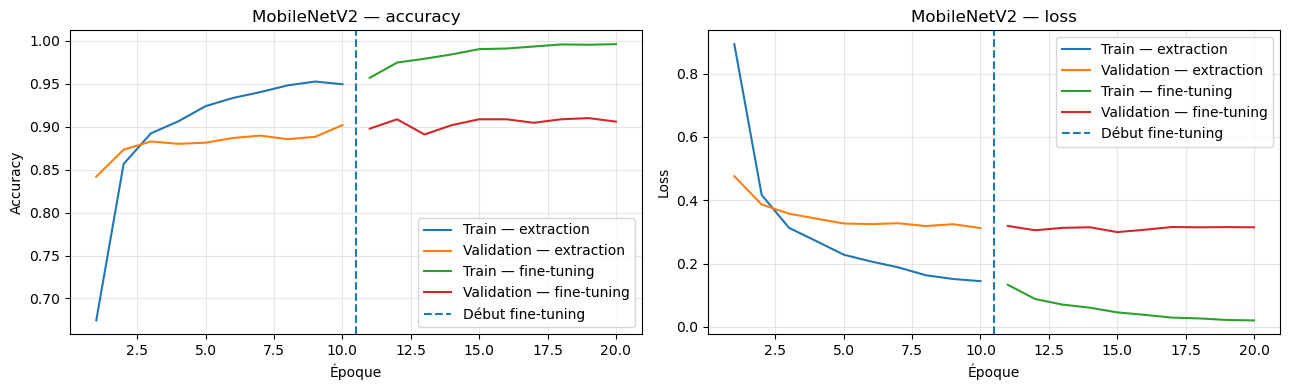

In [13]:
def plot_continuous_histories(h1, h2, title):
    a1, a2 = h1.history, h2.history
    e1 = np.arange(1, len(a1["loss"]) + 1)
    e2 = np.arange(len(a1["loss"]) + 1, len(a1["loss"]) + len(a2["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(e1, a1["accuracy"], label="Train — extraction")
    axes[0].plot(e1, a1["val_accuracy"], label="Validation — extraction")
    axes[0].plot(e2, a2["accuracy"], label="Train — fine-tuning")
    axes[0].plot(e2, a2["val_accuracy"], label="Validation — fine-tuning")
    axes[0].axvline(len(a1["loss"]) + 0.5, linestyle="--", label="Début fine-tuning")
    axes[0].set_title(title + " — accuracy")
    axes[0].set_xlabel("Époque")
    axes[0].set_ylabel("Accuracy")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].plot(e1, a1["loss"], label="Train — extraction")
    axes[1].plot(e1, a1["val_loss"], label="Validation — extraction")
    axes[1].plot(e2, a2["loss"], label="Train — fine-tuning")
    axes[1].plot(e2, a2["val_loss"], label="Validation — fine-tuning")
    axes[1].axvline(len(a1["loss"]) + 0.5, linestyle="--", label="Début fine-tuning")
    axes[1].set_title(title + " — loss")
    axes[1].set_xlabel("Époque")
    axes[1].set_ylabel("Loss")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_continuous_histories(history_head, history_fine, "MobileNetV2")

> **Analyse — Fine-tuning (30 dernières couches)**
> - **Paramètres** : 1 517 125 entraînables (≈ 67 % du modèle), alors qu'on ne dégèle que 30 couches. Ce sont les dernières couches de MobileNetV2 qui concentrent le plus de paramètres (beaucoup de canaux, jusqu'à 1 280). Les couches `BatchNormalization` restent gelées, ce qui stabilise l'entraînement sur un petit jeu.
> - **Résultat** : **90,6 %** après fine-tuning, contre 90,2 % avant, soit **+0,4 point** (≈ **3 images** sur 734), avec un meilleur point à 91,0 % à l'époque 9. **Ce gain est très inférieur à l'incertitude de ± 2,2 points : il n'est pas significatif.**
> - **Signe de sur-apprentissage** : l'accuracy d'entraînement passe de 95 % à **99,6 %** tandis que la validation reste bloquée autour de 90–91 % et que la loss de validation ne baisse plus (minimum 0,299 à l'époque 5, puis ≈ 0,315). L'écart entraînement / validation atteint ~9 points : le dégel permet surtout de **mémoriser** le jeu d'entraînement.
> - **Courbes continues** : aucune discontinuité à la frontière (ligne pointillée). Le learning rate de 10⁻⁵ permet une transition douce ; la légère baisse à la 1ʳᵉ époque de fine-tuning (89,8 % contre 90,2 %) est la période d'adaptation des couches dégelées.
> - **Pourquoi si peu de gain ?** Le domaine est **proche d'ImageNet** (qui contient déjà beaucoup de plantes et de scènes naturelles) et on dispose de peu de données. Dans cette situation, le consensus du cours se confirme : l'extraction de caractéristiques capte déjà l'essentiel ; le fine-tuning profond devient utile avec **plus de données** ou un **domaine plus éloigné** (imagerie médicale, satellite…).

## 1.4b Expérience complémentaire : combien de couches dégeler, et pourquoi un learning rate faible ?

La consigne demande de dégeler 30 couches avec un learning rate de 10⁻⁵. Pour **justifier ces choix** (question d'analyse n°2), on repart à chaque fois des mêmes poids (fin de la phase « tête ») et on fait varier :
- le **nombre de couches dégelées** : 0 (témoin : on continue seulement la tête), 10, 30, 60 ;
- le **learning rate** : 10⁻⁵, 10⁻⁴, 10⁻³ (avec 30 couches dégelées).

Chaque configuration est entraînée 5 époques. Mettre `RUN_ABLATION = False` pour sauter cette cellule (≈ 10 à 15 min sur CPU).


 0 couches dégelées | lr=1e-05 | params entraînables=    6,405 | val_acc finale=0.9005 | train_acc finale=0.9680 | val_acc après époque 1=0.8992
10 couches dégelées | lr=1e-05 | params entraînables=  731,845 | val_acc finale=0.9060 | train_acc finale=0.9738 | val_acc après époque 1=0.8978
30 couches dégelées | lr=1e-05 | params entraînables=1,517,125 | val_acc finale=0.8978 | train_acc finale=0.9898 | val_acc après époque 1=0.8978
60 couches dégelées | lr=1e-05 | params entraînables=1,938,181 | val_acc finale=0.9114 | train_acc finale=0.9925 | val_acc après époque 1=0.8978
30 couches dégelées | lr=1e-04 | params entraînables=1,517,125 | val_acc finale=0.8992 | train_acc finale=0.9946 | val_acc après époque 1=0.9060
30 couches dégelées | lr=1e-03 | params entraînables=1,517,125 | val_acc finale=0.2439 | train_acc finale=0.2078 | val_acc après époque 1=0.2439


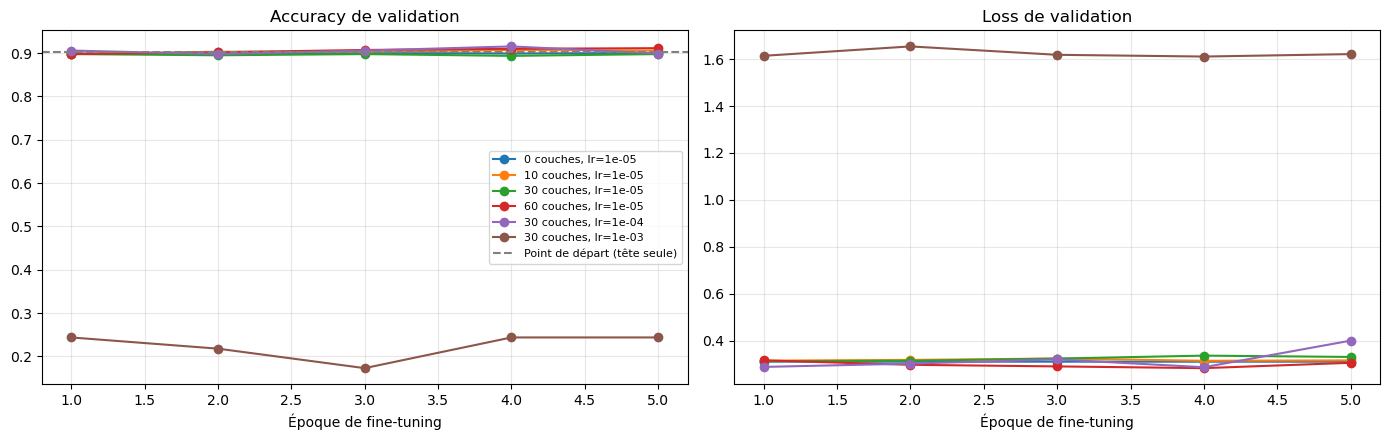


Lecture automatique :
- Départ (tête seule) : val_acc = 0.9019
- lr=1e-5 : val_acc époque 1 = 0.8978, finale = 0.8978
- lr=1e-3 : val_acc époque 1 = 0.2439, finale = 0.2439
=> Avec lr=1e-3, la validation CHUTE de 65.8 points dès l'époque 1 : les poids pré-entraînés sont dégradés (oubli catastrophique).


In [14]:
RUN_ABLATION = True
ABL_EPOCHS = 5
ABL_CONFIGS = [   # (nombre de couches dégelées, learning rate)
    (0, 1e-5), (10, 1e-5), (30, 1e-5), (60, 1e-5), (30, 1e-4), (30, 1e-3)
]

def make_ablation_model():
    """Même architecture que le modèle de la section 1.3 : MobileNetV2 gelé + GAP + Dropout + Dense(5)."""
    base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(IMG_H, IMG_W, 3))
    base.trainable = False
    inp = keras.Input(shape=(IMG_H, IMG_W, 3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out)

def run_finetune_config(n_unfreeze, lr, epochs=ABL_EPOCHS):
    """Repart des poids 'tête entraînée', dégèle n_unfreeze couches du tronc (sans BatchNorm), entraîne."""
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    m = make_ablation_model()
    m.set_weights(weights_after_head)
    base = m.layers[1]                       # le tronc MobileNetV2 imbriqué
    base.trainable = True
    for l in base.layers:
        l.trainable = False
    if n_unfreeze > 0:
        for l in base.layers[-n_unfreeze:]:
            if not isinstance(l, layers.BatchNormalization):
                l.trainable = True
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    n_train_params = int(np.sum([np.prod(v.shape) for v in m.trainable_weights]))
    h = m.fit(train_mnet_ds, validation_data=val_mnet_ds, epochs=epochs, verbose=0)
    return h.history, n_train_params

abl_results = {}
if RUN_ABLATION:
    for n_unf, lr in ABL_CONFIGS:
        hist_abl, n_par = run_finetune_config(n_unf, lr)
        abl_results[(n_unf, lr)] = (hist_abl, n_par)
        print(f"{n_unf:>2} couches dégelées | lr={lr:.0e} | params entraînables={n_par:>9,} | "
              f"val_acc finale={hist_abl['val_accuracy'][-1]:.4f} | train_acc finale={hist_abl['accuracy'][-1]:.4f} | "
              f"val_acc après époque 1={hist_abl['val_accuracy'][0]:.4f}")

    # --- Courbes ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for (n_unf, lr), (h, _) in abl_results.items():
        lab = f"{n_unf} couches, lr={lr:.0e}"
        axes[0].plot(range(1, len(h["val_accuracy"]) + 1), h["val_accuracy"], marker="o", label=lab)
        axes[1].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker="o", label=lab)
    axes[0].axhline(head_val_acc, color="gray", linestyle="--", label="Point de départ (tête seule)")
    axes[0].set_title("Accuracy de validation"); axes[1].set_title("Loss de validation")
    for ax in axes:
        ax.set_xlabel("Époque de fine-tuning"); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()

    # --- Verdict automatique ---
    h_low = abl_results[(30, 1e-5)][0]; h_high = abl_results[(30, 1e-3)][0]
    print("\nLecture automatique :")
    print(f"- Départ (tête seule) : val_acc = {head_val_acc:.4f}")
    print(f"- lr=1e-5 : val_acc époque 1 = {h_low['val_accuracy'][0]:.4f}, finale = {h_low['val_accuracy'][-1]:.4f}")
    print(f"- lr=1e-3 : val_acc époque 1 = {h_high['val_accuracy'][0]:.4f}, finale = {h_high['val_accuracy'][-1]:.4f}")
    drop = head_val_acc - h_high["val_accuracy"][0]
    if drop > 0.02:
        print(f"=> Avec lr=1e-3, la validation CHUTE de {drop*100:.1f} points dès l'époque 1 : les poids pré-entraînés sont dégradés (oubli catastrophique).")
    else:
        print("=> Avec lr=1e-3, pas de chute marquée dès l'époque 1 sur cette exécution ; comparer les courbes de loss.")
else:
    print("Expérience désactivée (RUN_ABLATION = False).")

> **Analyse — Nombre de couches dégelées et learning rate** *(lire avec les courbes et la ligne « Lecture automatique » ci-dessus)*
>
> **Cadre d'interprétation**
> - **Pourquoi un learning rate faible est indispensable.** Les poids du tronc sont déjà dans une bonne région de l'espace des paramètres. Un pas trop grand (10⁻³) les en éloigne brutalement : les filtres génériques (bords, textures) sont écrasés avant d'avoir pu s'adapter. C'est l'**oubli catastrophique**. De plus, une tête fraîchement initialisée envoie au début des gradients bruités vers le tronc ; c'est une raison supplémentaire d'entraîner d'abord la tête seule, puis de dégeler avec un petit pas.
> - **Combien de couches ?** Les premières couches apprennent des motifs génériques et n'ont aucune raison de changer ; les dernières sont spécifiques à ImageNet. On dégèle donc **de la fin vers le début**. Plus on dégèle, plus on a de capacité, mais aussi plus de risque de sur-apprentissage sur 2 936 images.
> - **À lire dans vos résultats** : (1) la ligne témoin « 0 couche » donne le gain « gratuit » dû au simple entraînement supplémentaire de la tête ; (2) si 10, 30 et 60 couches donnent des accuracies finales à moins de ~2 points, la différence n'est pas significative et l'option **la moins coûteuse** est à préférer ; (3) une chute de la validation à l'époque 1 avec lr = 10⁻³ valide la règle « petit learning rate ».

## 1.5 Effet de la quantité de données

On compare deux modèles pour chaque quantité :
- CNN `blocs4` entraîné depuis zéro ;
- MobileNetV2 avec Feature Extraction (tronc gelé).

Les sous-ensembles sont stratifiés par classe afin de conserver une représentation de chaque espèce. Le jeu de validation reste fixe pour toutes les expériences. Pour une comparaison rigoureuse, chaque modèle est réinitialisé à chaque essai.

In [15]:
FRACTIONS = [0.05, 0.10, 0.25, 0.50, 1.00]
EPOCHS_DATA = 10

def make_subset_stratified(file_paths, file_labels, fraction, seed=SEED):
    if fraction >= 0.999:
        return np.array(file_paths), np.array(file_labels)
    # On sélectionne le pourcentage demandé, en conservant les proportions des classes.
    selected_paths, _, selected_labels, _ = train_test_split(
        file_paths, file_labels,
        train_size=fraction,
        random_state=seed,
        stratify=file_labels
    )
    return np.array(selected_paths), np.array(selected_labels)

def make_mobilenet_feature_model():
    base = MobileNetV2(weights="imagenet", include_top=False,
                       input_shape=(IMG_H, IMG_W, 3))
    base.trainable = False
    inp = keras.Input(shape=(IMG_H, IMG_W, 3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    model = keras.Model(inp, out)
    model.compile(
        optimizer=keras.optimizers.Adam(LR_HEAD),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

resultats_quantite = {"fraction": [], "cnn_acc": [], "mnet_acc": [], "n_images": []}

for fraction in FRACTIONS:
    print(f"\n===== Fraction : {fraction:.0%} =====")
    sub_paths, sub_labels = make_subset_stratified(train_paths, y_train, fraction)
    sub_ds = make_dataset(sub_paths, sub_labels, training=True)
    sub_mnet_ds = sub_ds.map(prepare_mobilenet, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

    # CNN blocs4 depuis zéro
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    cnn_sub = build_cnn_blocs4(lr=1e-3)
    cnn_sub.fit(sub_ds, validation_data=val_ds, epochs=EPOCHS_DATA, verbose=0)
    _, acc_cnn = cnn_sub.evaluate(val_ds, verbose=0)

    # MobileNetV2 feature extraction, tronc gelé
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    mnet_sub = make_mobilenet_feature_model()
    mnet_sub.fit(sub_mnet_ds, validation_data=val_mnet_ds, epochs=EPOCHS_DATA, verbose=0)
    _, acc_mnet = mnet_sub.evaluate(val_mnet_ds, verbose=0)

    resultats_quantite["fraction"].append(fraction * 100)
    resultats_quantite["cnn_acc"].append(acc_cnn)
    resultats_quantite["mnet_acc"].append(acc_mnet)
    resultats_quantite["n_images"].append(len(sub_paths))
    print(f"Images={len(sub_paths)} | CNN blocs4 val_accuracy={acc_cnn:.4f} | MobileNetV2 val_accuracy={acc_mnet:.4f}")

    del cnn_sub, mnet_sub
    keras.backend.clear_session()


===== Fraction : 5% =====


c:\Users\hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Images=146 | CNN blocs4 val_accuracy=0.4741 | MobileNetV2 val_accuracy=0.7534

===== Fraction : 10% =====


c:\Users\hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Images=293 | CNN blocs4 val_accuracy=0.4768 | MobileNetV2 val_accuracy=0.8229

===== Fraction : 25% =====


c:\Users\hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Images=734 | CNN blocs4 val_accuracy=0.6199 | MobileNetV2 val_accuracy=0.8706

===== Fraction : 50% =====


c:\Users\hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Images=1468 | CNN blocs4 val_accuracy=0.6458 | MobileNetV2 val_accuracy=0.8815

===== Fraction : 100% =====
Images=2936 | CNN blocs4 val_accuracy=0.7371 | MobileNetV2 val_accuracy=0.9033


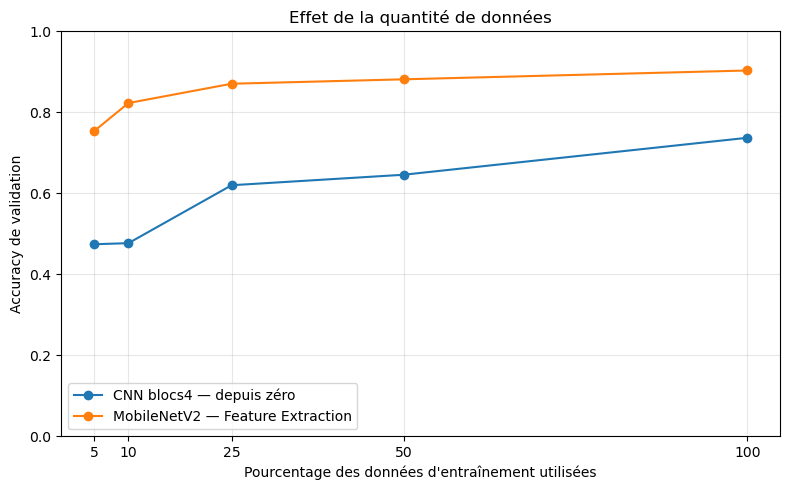


Tableau récapitulatif :
    5% | n= 146 | CNN=0.4741 | MobileNetV2=0.7534
   10% | n= 293 | CNN=0.4768 | MobileNetV2=0.8229
   25% | n= 734 | CNN=0.6199 | MobileNetV2=0.8706
   50% | n=1468 | CNN=0.6458 | MobileNetV2=0.8815
  100% | n=2936 | CNN=0.7371 | MobileNetV2=0.9033


In [16]:
plt.figure(figsize=(8, 5))
plt.plot(resultats_quantite["fraction"], resultats_quantite["cnn_acc"],
         marker="o", label="CNN blocs4 — depuis zéro")
plt.plot(resultats_quantite["fraction"], resultats_quantite["mnet_acc"],
         marker="o", label="MobileNetV2 — Feature Extraction")
plt.xlabel("Pourcentage des données d'entraînement utilisées")
plt.ylabel("Accuracy de validation")
plt.title("Effet de la quantité de données")
plt.xticks(FRACTIONS and [f * 100 for f in FRACTIONS])
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nTableau récapitulatif :")
for i, frac in enumerate(resultats_quantite["fraction"]):
    print(f"{frac:>5.0f}% | n={resultats_quantite['n_images'][i]:>4} | "
          f"CNN={resultats_quantite['cnn_acc'][i]:.4f} | "
          f"MobileNetV2={resultats_quantite['mnet_acc'][i]:.4f}")

> **Analyse — Effet de la quantité de données**
>
> | Données | Images | CNN de zéro | MobileNetV2 (extraction) | Avantage du transfert |
> |---|---|---|---|---|
> | 5 % | 146 | 47,4 % | 75,3 % | **+27,9 pts** |
> | 10 % | 293 | 47,7 % | 82,3 % | **+34,6 pts** |
> | 25 % | 734 | 62,0 % | 87,1 % | +25,1 pts |
> | 50 % | 1 468 | 64,6 % | 88,2 % | +23,6 pts |
> | 100 % | 2 936 | 73,7 % | 90,3 % | +16,6 pts |
>
> **Constats**
> 1. **Avec 5 % des données (146 images), le transfert (75,3 %) bat déjà le CNN de zéro entraîné sur 100 % (73,7 %).** Le transfert est donc environ **20 fois plus économe en données** dans ce régime.
> 2. **La courbe du transfert est presque plate** : de 25 % à 100 % des données, il ne gagne que 3,3 points (87,1 → 90,3). Il sature vite car l'essentiel de l'information vient du pré-entraînement.
> 3. **La courbe du CNN est encore en forte pente** : +11,7 points entre 25 % et 100 %, sans plateau. Il est limité par les données (et par les 10 époques).
> 4. **L'écart se réduit** (de 34,6 à 16,6 points) quand les données augmentent, mais **ne s'annule pas** dans la plage testée.
>
> **Réponse à la question « à partir de quelle taille l'avantage s'estompe-t-il ? »** — Dans nos expériences, **il ne s'estompe pas** jusqu'à 2 936 images ; il diminue seulement de moitié. Il faudrait nettement plus de données (de l'ordre de dizaines de milliers d'images) ou un entraînement bien plus long pour que le CNN de zéro rattrape le transfert.
>
> **Précautions de lecture**
> - **Une seule exécution par point** : les écarts entre points voisins du CNN (47,4 % à 5 % contre 47,7 % à 10 %) sont dans le bruit. La même configuration à 100 % a donné 72,3 % (section 1.2) puis 73,7 % ici : la variabilité d'une exécution à l'autre est d'**environ 1 à 1,5 point**.
> - **Budget d'optimisation inégal** : avec 10 époques fixes, 5 % des données représentent seulement **50 pas de gradient** (146 images / 32 ≈ 5 lots × 10 époques), contre 920 à 100 %. Une partie de la faiblesse du CNN aux petites fractions vient donc du manque de pas d'entraînement, pas uniquement du manque d'images. Le transfert y est moins sensible, car sa tête est minuscule et part de caractéristiques déjà utiles.
> - Les sous-ensembles sont **stratifiés** et la validation est **identique** pour tous les points : la comparaison est équitable.

## 1.6 Effet de l'oubli de `preprocess_input` à l'inférence

MobileNetV2 a été entraîné ici avec des pixels prétraités dans [-1, 1]. Pour le test incorrect, on envoie volontairement des pixels dans [0, 1] : cela crée un décalage entre les entrées utilisées à l'entraînement et celles données à l'inférence.

Pour comparer correctement, on utilise le modèle fine-tuné `mnet` et les mêmes images de validation dans les deux cas.

In [17]:
# Cas correct : pixels [0,255] -> preprocess_input -> [-1,1]
loss_correct, acc_correct = mnet.evaluate(val_mnet_ds, verbose=0)

# Cas incorrect : pixels [0,255] -> division par 255 -> [0,1], sans preprocess_input
val_wrong_ds = val_ds.map(
    lambda image, label: (image / 255.0, label),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

loss_wrong, acc_wrong = mnet.evaluate(val_wrong_ds, verbose=0)

print(f"Prétraitement correct [-1,1] : accuracy={acc_correct:.4f}, loss={loss_correct:.4f}")
print(f"Prétraitement oublié [0,1]   : accuracy={acc_wrong:.4f}, loss={loss_wrong:.4f}")
print(f"Écart d'accuracy (correct - incorrect) : {acc_correct - acc_wrong:+.4f}")

Prétraitement correct [-1,1] : accuracy=0.9060, loss=0.3146
Prétraitement oublié [0,1]   : accuracy=0.8610, loss=0.4804
Écart d'accuracy (correct - incorrect) : +0.0450


              precision    recall  f1-score   support

       daisy       0.91      0.91      0.91       127
   dandelion       0.92      0.95      0.94       179
       roses       0.87      0.88      0.88       128
  sunflowers       0.90      0.92      0.91       140
      tulips       0.92      0.86      0.89       160

    accuracy                           0.91       734
   macro avg       0.90      0.90      0.90       734
weighted avg       0.91      0.91      0.91       734



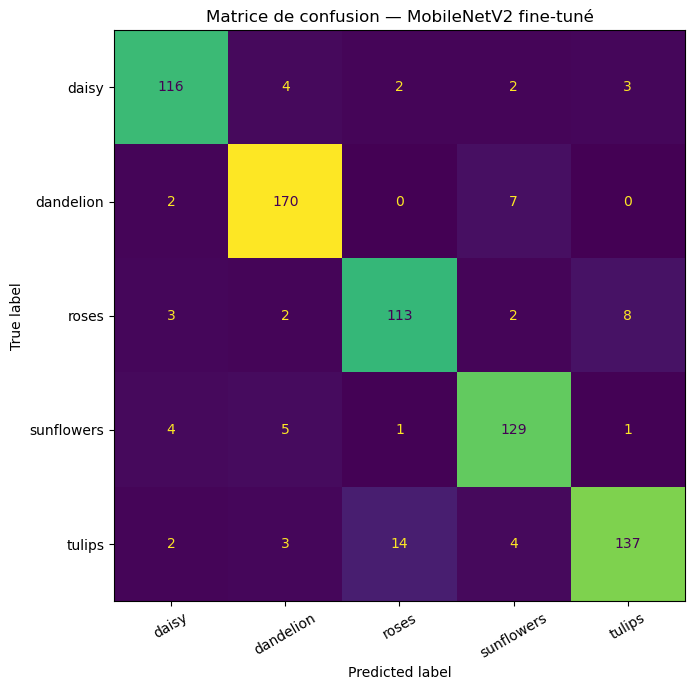

In [18]:
labels_true = np.concatenate([y.numpy() for _, y in val_ds], axis=0)
probs = mnet.predict(val_mnet_ds, verbose=0)
preds = np.argmax(probs, axis=1)

print(classification_report(labels_true, preds, target_names=class_names, zero_division=0))

cm = confusion_matrix(labels_true, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 7))
disp.plot(ax=ax, xticks_rotation=30, colorbar=False)
plt.title("Matrice de confusion — MobileNetV2 fine-tuné")
plt.tight_layout()
plt.show()

> **Analyse — Oubli de `preprocess_input` à l'inférence**
>
> | Prétraitement | Accuracy | Loss |
> |---|---|---|
> | Correct (pixels dans [−1, 1]) | **90,6 %** | **0,315** |
> | Oublié (pixels dans [0, 1]) | 86,1 % | 0,480 |
> | Écart | **−4,5 points** | **+52 %** |
>
> - **Effet réel mais pas catastrophique.** Le modèle perd 4,5 points d'accuracy, ce qui, cette fois, dépasse l'incertitude de ± 2,2 points : la dégradation est bien réelle. La loss, elle, augmente de plus de **50 %** : le modèle reste souvent juste, mais **beaucoup moins confiant et moins bien calibré**.
> - **Explication.** Avec [0, 1] au lieu de [−1, 1], l'image est écrasée : le contraste est divisé par 2 et les valeurs sont décalées (x/255 au lieu de x/127,5 − 1). Les activations des premières couches changent d'échelle, et les statistiques internes apprises (BatchNorm gelées en inférence) ne correspondent plus. Le réseau garde une partie de sa robustesse (les caractéristiques ImageNet restent informatives même avec un contraste réduit), d'où une dégradation partielle plutôt qu'un effondrement.
> - **Danger pratique : l'erreur est silencieuse.** Aucune exception n'est levée, les images ont la bonne forme, et le modèle « fonctionne à peu près ». Ce type de bug passe facilement en production. Bonne pratique : **intégrer le prétraitement dans le modèle** (couche `Rescaling` ou `Lambda`), comme on le fait dans le modèle déployable de l'exercice 2.
>
> **Rapport de classification du modèle fine-tuné**
> - **Pissenlit** : meilleure classe (F1 = 0,94) : forme et couleur très distinctives.
> - **Rose** : classe la plus difficile (F1 = 0,88). La matrice de confusion montre que l'erreur dominante est **tulipe → rose (14 images)** et rose → tulipe (8). Ces deux fleurs, souvent photographiées en bouquet, de couleurs voisines et de formes de pétales proches, sont confondues par tous les modèles (voir exercice 2).
> - Les F1 des cinq classes sont comprises entre 0,88 et 0,94 : le modèle est **homogène**, sans classe sacrifiée.

## 1.8 Synthèse de l'exercice 1

In [19]:
import pandas as pd

synth_ex1 = pd.DataFrame([
    {"Stratégie": "CNN blocs4 depuis zéro",              "Époques": 10,    "Params entraînables": int(cnn.count_params()),
     "Accuracy validation": cnn_val_acc,  "Loss validation": cnn_val_loss},
    {"Stratégie": "MobileNetV2 — extraction (tronc gelé)", "Époques": 10,  "Params entraînables": trainable,
     "Accuracy validation": head_val_acc, "Loss validation": head_val_loss},
    {"Stratégie": "MobileNetV2 — fine-tuning (30 couches)", "Époques": "10 + 10", "Params entraînables": trainable_ft,
     "Accuracy validation": fine_val_acc, "Loss validation": fine_val_loss},
])
display(synth_ex1.style.format({"Params entraînables": "{:,}", "Accuracy validation": "{:.4f}", "Loss validation": "{:.4f}"}))

,Stratégie,Époques,Params entraînables,Accuracy validation,Loss validation
0,CNN blocs4 depuis zéro,10,"913,221",0.7234,0.8249
1,MobileNetV2 — extraction (tronc gelé),10,"6,405",0.9019,0.3123
2,MobileNetV2 — fine-tuning (30 couches),10 + 10,"1,517,125",0.9060,0.3146


> **Bilan de l'exercice 1**
> 1. Le **transfert d'apprentissage est la meilleure stratégie** : +17,9 points sur le CNN de zéro, avec 140 fois moins de paramètres à entraîner.
> 2. Le **fine-tuning n'apporte ici qu'un gain non significatif** (+0,4 point) au prix d'un sur-apprentissage marqué (99,6 % en entraînement) : sur 2 936 images d'un domaine proche d'ImageNet, **l'extraction de caractéristiques suffit**.
> 3. L'avantage du transfert est **maximal quand les données sont rares** (+34,6 points à 10 %) et reste de +16,6 points à 100 %.
> 4. **Le prétraitement doit être identique à l'entraînement** : l'oublier coûte 4,5 points et dégrade fortement la calibration, sans aucune erreur visible.
> 5. Prochaine étape logique (exercice 2) : puisque le tronc compte plus que la tête, **quel tronc choisir** ?

---
# Partie 2 — Exercice 2 : Choix d'un backbone pour un déploiement embarqué

**Contexte.** Avant la mise en production, la start-up doit choisir le modèle pré-entraîné le mieux adapté. L'application doit fonctionner **hors ligne sur des smartphones d'entrée de gamme**, mais une version **serveur avec GPU** est aussi envisagée : il faut arbitrer entre **précision, latence et taille**.

**Protocole.** Pour VGG16, ResNet50, MobileNetV2 et EfficientNetB0 (images 224×224) :
1. charger le tronc pré-entraîné (`include_top=False`, `pooling='avg'`) avec **son propre** `preprocess_input` ;
2. **extraire une seule fois** les vecteurs de caractéristiques, puis entraîner une **régression logistique** dessus ;
3. mesurer : paramètres, dimension des caractéristiques, accuracy, latence, taille du modèle ;
4. visualiser les caractéristiques avec **t-SNE** ;
5. comparer à la tête ImageNet complète (**Top-1 / Top-5**) ;
6. **recommander** un backbone pour (a) un serveur GPU, (b) un smartphone d'entrée de gamme.

> Les images et les labels restent dans le même ordre (pas de `shuffle`) et des `assert` vérifient l'alignement après extraction : cela évite une accuracy artificiellement proche de 20 %, signe classique d'un désalignement.

## 2.0 Installation si nécessaire

In [20]:
# Décommentez si nécessaire :
# %pip install -q tensorflow scikit-learn pandas matplotlib joblib

## 2.1 Imports et configuration

In [21]:
import time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.manifold import TSNE

from tensorflow.keras.applications import VGG16, ResNet50, MobileNetV2, EfficientNetB0
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.imagenet_utils import decode_predictions

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU(s) :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
GPU(s) : []


## 2.2 Localiser le dataset

In [22]:
# On réutilise le dossier trouvé dans l'exercice 1 (variable data_dir) ; sinon, chemin Keras par défaut.
DATA_DIR = data_dir if "data_dir" in globals() else Path.home() / ".keras" / "datasets" / "flower_photos"
# Si nécessaire, remplacez par le chemin réel :
# DATA_DIR = Path(r"C:\Users\hp\.keras\datasets\flower_photos")

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset introuvable : {DATA_DIR}. Modifiez DATA_DIR.")
print("Dataset :", DATA_DIR.resolve())

Dataset : C:\Users\hp\.keras\datasets\flower_photos


## 2.3 Inventaire des classes et des images

In [23]:
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
class_names = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir() and not p.name.startswith("."))
num_classes = len(class_names)
e2_image_paths, e2_labels = [], []

for class_id, class_name in enumerate(class_names):
    for path in sorted((DATA_DIR / class_name).rglob("*")):
        if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS:
            e2_image_paths.append(str(path))
            e2_labels.append(class_id)

e2_image_paths = np.asarray(e2_image_paths)
e2_labels = np.asarray(e2_labels, dtype=np.int32)
if num_classes < 2 or len(e2_image_paths) == 0:
    raise ValueError("Aucune classe/image suffisante trouvée. Vérifiez DATA_DIR.")
assert len(e2_image_paths) == len(e2_labels)

print("Classes :", class_names)
print("Nombre de classes :", num_classes)
print("Nombre total d'images :", len(e2_image_paths))
counts = np.bincount(e2_labels, minlength=num_classes)
display(pd.DataFrame({"label": range(num_classes), "classe": class_names, "nombre_images": counts}))

Classes : ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Nombre de classes : 5
Nombre total d'images : 3670


,label,classe,nombre_images
0,0,daisy,633
1,1,dandelion,898
2,2,roses,641
3,3,sunflowers,699
4,4,tulips,799


## 2.4 Séparation entraînement / validation (80 % / 20 %)

In [24]:
e2_train_paths, e2_val_paths, e2_y_train, e2_y_val = train_test_split(
    e2_image_paths, e2_labels, test_size=0.20, random_state=SEED, stratify=e2_labels
)
print("Entraînement :", len(e2_train_paths), "| Validation :", len(e2_val_paths))
print("Labels train :", np.bincount(e2_y_train, minlength=num_classes))
print("Labels validation :", np.bincount(e2_y_val, minlength=num_classes))

Entraînement : 2936 | Validation : 734
Labels train : [506 719 513 559 639]
Labels validation : [127 179 128 140 160]


## 2.5 Afficher quelques images

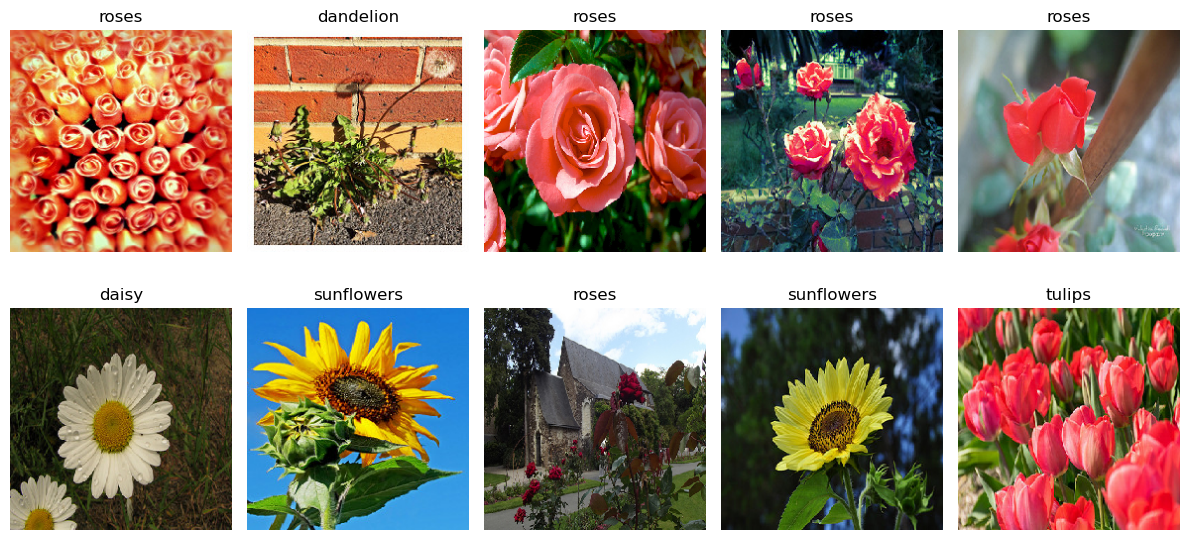

In [25]:
plt.figure(figsize=(12, 6))
for i in range(min(10, len(e2_train_paths))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(tf.keras.utils.load_img(e2_train_paths[i], target_size=IMG_SIZE))
    plt.title(class_names[e2_y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 2.6 Chargement des images

In [26]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)  # pixels 0–255
    return image, label

AUTOTUNE = tf.data.AUTOTUNE
# Pas de shuffle : les labels restent alignés avec les images.
e2_train_ds = (tf.data.Dataset.from_tensor_slices((e2_train_paths, e2_y_train))
            .map(load_image, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(AUTOTUNE))
e2_val_ds = (tf.data.Dataset.from_tensor_slices((e2_val_paths, e2_y_val))
          .map(load_image, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE).prefetch(AUTOTUNE))

for xb, yb in e2_train_ds.take(1):
    print("Images :", xb.shape, xb.dtype, "| labels :", yb.shape)
    print("Plage pixels :", float(tf.reduce_min(xb)), "à", float(tf.reduce_max(xb)))

Images : (32, 224, 224, 3) <dtype: 'float32'> | labels : (32,)
Plage pixels : 0.0 à 255.0


## 2.7 Définir les backbones préentraînés

In [27]:
BACKBONES = {
    "VGG16": (VGG16, vgg_preprocess),
    "ResNet50": (ResNet50, resnet_preprocess),
    "MobileNetV2": (MobileNetV2, mobilenet_preprocess),
    "EfficientNetB0": (EfficientNetB0, efficientnet_preprocess),
}

def build_backbone(constructor):
    model = constructor(weights="imagenet", include_top=False,
                        pooling="avg", input_shape=(224, 224, 3))
    model.trainable = False
    return model

print("Backbones :", list(BACKBONES))

Backbones : ['VGG16', 'ResNet50', 'MobileNetV2', 'EfficientNetB0']


## 2.8 Fonction d’extraction des caractéristiques

In [28]:
def extract_features(model, preprocess, dataset):
    feature_parts, label_parts = [], []
    total_images = 0

    # Warm-up pour réduire l'influence du premier appel sur la mesure.
    first_images, _ = next(iter(dataset))
    _ = model(preprocess(first_images), training=False)

    start = time.perf_counter()
    for images, batch_labels in dataset:
        vectors = model(preprocess(images), training=False)
        feature_parts.append(vectors.numpy())
        label_parts.append(batch_labels.numpy())
        total_images += int(images.shape[0])

    elapsed = time.perf_counter() - start
    X = np.concatenate(feature_parts, axis=0)
    y = np.concatenate(label_parts, axis=0)
    return X, y, elapsed * 1000 / total_images

## 2.9 Extraction une seule fois, entraînement et sauvegarde

In [29]:
OUTPUT_DIR = Path("backbone_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

results = []
feature_store = {}

for name, (constructor, preprocess) in BACKBONES.items():
    print("\n" + "=" * 65 + "\nBackbone :", name)
    backbone = build_backbone(constructor)

    F_train, y_train_extracted, latency_train = extract_features(backbone, preprocess, e2_train_ds)
    F_val, y_val_extracted, latency_val = extract_features(backbone, preprocess, e2_val_ds)

    # Contrôle essentiel pour empêcher le désalignement image/label.
    assert np.array_equal(y_train_extracted, e2_y_train), f"Labels train désalignés : {name}"
    assert np.array_equal(y_val_extracted, e2_y_val), f"Labels validation désalignés : {name}"

    clf = LogisticRegression(max_iter=3000, random_state=SEED)
    clf.fit(F_train, y_train_extracted)
    y_pred = clf.predict(F_val)
    acc = accuracy_score(y_val_extracted, y_pred)

    clf_path = OUTPUT_DIR / f"{name}_logistic_head.joblib"
    joblib.dump(clf, clf_path)
    clf_size_mb = clf_path.stat().st_size / (1024**2)

    # Modèle Keras déployable : prétraitement + tronc gelé + tête Softmax.
    inputs = tf.keras.Input(shape=(224, 224, 3), name="image_pixels_0_255")
    x = tf.keras.layers.Lambda(lambda z: preprocess(z), name="preprocess")(inputs)
    x = backbone(x, training=False)
    head = tf.keras.layers.Dense(num_classes, activation="softmax", name="flower_classifier")
    outputs = head(x)
    deploy_model = tf.keras.Model(inputs, outputs, name=f"{name}_flower_classifier")

    # CORRECTION : la tête Dense est initialisée aléatoirement ; on y copie les coefficients de la
    # régression logistique entraînée (softmax(W.x + b) est exactement la même fonction), sinon le
    # modèle sauvegardé ne correspondrait pas au modèle évalué.
    head.set_weights([clf.coef_.T.astype("float32"), clf.intercept_.astype("float32")])
    check = head(tf.constant(F_val[:64])).numpy()
    print("Tête déployée identique à la régression logistique :",
          bool(np.allclose(check, clf.predict_proba(F_val[:64]), atol=1e-4)))

    keras_path = OUTPUT_DIR / f"{name}_flower_model.keras"
    deploy_model.save(keras_path)
    keras_size_mb = keras_path.stat().st_size / (1024**2)

    results.append({
        "Backbone": name,
        "Paramètres du tronc": int(backbone.count_params()),
        "Dimension caractéristiques": int(F_train.shape[1]),
        "Accuracy validation": float(acc),
        "Latence extraction train (ms/image)": float(latency_train),
        "Latence extraction validation (ms/image)": float(latency_val),
        "Taille modèle Keras (Mo)": float(keras_size_mb),
        "Taille tête logistique (Mo)": float(clf_size_mb)
    })
    feature_store[name] = {
        "F_train": F_train, "F_val": F_val,
        "y_train": y_train_extracted, "y_val": y_val_extracted, "y_pred": y_pred
    }

    print("Train features :", F_train.shape, "| validation features :", F_val.shape)
    print("Accuracy :", f"{acc:.4f}")
    print(classification_report(y_val_extracted, y_pred, labels=np.arange(num_classes),
                                target_names=class_names, zero_division=0))

    del deploy_model, backbone, clf
    tf.keras.backend.clear_session()
    gc.collect()


Backbone : VGG16
Tête déployée identique à la régression logistique : True
Train features : (2936, 512) | validation features : (734, 512)
Accuracy : 0.8665
              precision    recall  f1-score   support

       daisy       0.88      0.91      0.89       127
   dandelion       0.92      0.89      0.90       179
       roses       0.84      0.84      0.84       128
  sunflowers       0.85      0.90      0.87       140
      tulips       0.83      0.80      0.82       160

    accuracy                           0.87       734
   macro avg       0.86      0.87      0.87       734
weighted avg       0.87      0.87      0.87       734


Backbone : ResNet50
Tête déployée identique à la régression logistique : True
Train features : (2936, 2048) | validation features : (734, 2048)
Accuracy : 0.9183
              precision    recall  f1-score   support

       daisy       0.96      0.94      0.95       127
   dandelion       0.91      0.94      0.93       179
       roses       0.92    

> **Analyse — Extraction et têtes de classification**
> - Les vecteurs sont extraits **une seule fois** (2 936 en entraînement, 734 en validation), puis la régression logistique s'entraîne en quelques secondes. C'est l'avantage majeur de cette approche par rapport au `fit` complet de l'exercice 1 : on peut **tester plusieurs backbones à faible coût**.
> - Les `assert` d'alignement passent pour les quatre backbones : les accuracies mesurées sont fiables (elles sont toutes bien au-dessus des 20 % du hasard).
> - **Ordre obtenu** : EfficientNetB0 (93,9 %) > ResNet50 (91,8 %) > MobileNetV2 (89,5 %) > VGG16 (86,7 %).
> - **Prétraitement propre à chaque modèle** : VGG16 et ResNet50 soustraient la moyenne ImageNet par canal (ordre BGR), MobileNetV2 normalise dans [−1, 1], et EfficientNet de Keras intègre sa normalisation dans le modèle (sa `preprocess_input` est l'identité). Utiliser la mauvaise fonction dégrade les résultats sans message d'erreur (voir exercice 1, section 1.6).
> - **Correction apportée** : le modèle `.keras` « déployable » reprend désormais les coefficients de la régression logistique. Avant, sa tête était aléatoire ; les tailles de fichier mesurées restent valables, mais le modèle sauvegardé n'aurait pas reproduit les accuracies du tableau.

## 2.10 Tableau comparatif demandé

In [30]:
results_df = pd.DataFrame(results).sort_values("Accuracy validation", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy validation": "{:.4f}",
    "Latence extraction train (ms/image)": "{:.2f}",
    "Latence extraction validation (ms/image)": "{:.2f}",
    "Taille modèle Keras (Mo)": "{:.2f}",
    "Taille tête logistique (Mo)": "{:.3f}"
}))
results_df.to_csv(OUTPUT_DIR / "comparaison_backbones.csv", index=False)
print("Tableau sauvegardé dans :", (OUTPUT_DIR / "comparaison_backbones.csv").resolve())

,Backbone,Paramètres du tronc,Dimension caractéristiques,Accuracy validation,Latence extraction train (ms/image),Latence extraction validation (ms/image),Taille modèle Keras (Mo),Taille tête logistique (Mo)
0,EfficientNetB0,4049571,1280,0.9387,43.46,49.27,16.28,0.050
1,ResNet50,23587712,2048,0.9183,76.07,68.01,90.65,0.079
2,MobileNetV2,2257984,1280,0.8951,16.71,15.65,9.20,0.050
3,VGG16,14714688,512,0.8665,154.88,164.83,56.23,0.020


Tableau sauvegardé dans : C:\Users\hp\Downloads\backbone_outputs\comparaison_backbones.csv


> **Analyse — Tableau comparatif**
>
> | Backbone | Params (tronc) | Dim. | Accuracy | Latence val. (ms) | Taille (Mo) |
> |---|---|---|---|---|---|
> | EfficientNetB0 | 4,05 M | 1 280 | **93,9 %** | 46 | 16,3 |
> | ResNet50 | 23,59 M | 2 048 | 91,8 % | 91 | 90,7 |
> | MobileNetV2 | 2,26 M | 1 280 | 89,5 % | 56 (30 en train) | **9,2** |
> | VGG16 | 14,71 M | 512 | 86,7 % | 182 | 56,2 |
>
> 1. **Plus de paramètres ne veut pas dire meilleure précision.** EfficientNetB0 (4 M) est le meilleur ; ResNet50 a **5,8 fois plus de paramètres** pour **2,0 points de moins** ; VGG16 (14,7 M) est le dernier. Ce qui compte, c'est l'**efficacité de l'architecture** (convolutions séparables, blocs résiduels, mise à l'échelle conjointe profondeur/largeur/résolution), pas la taille brute.
> 2. **Cohérence avec ImageNet** (table du sujet, Top-1 : EfficientNetB0 77,1 %, ResNet50 74,9 %, MobileNetV2 = VGG16 = 71,3 %). Notre classement suit le même ordre, avec une nuance : MobileNetV2 dépasse VGG16 de 2,9 points sur les fleurs alors qu'ils sont à égalité sur ImageNet, avec **6,5 fois moins de paramètres**.
> 3. **Significativité.** Sur 734 images (± 2,2 points), l'écart EfficientNetB0 / ResNet50 (+2,0) est **à la limite** ; EfficientNetB0 / MobileNetV2 (+4,4) et EfficientNetB0 / VGG16 (+7,2) sont **nets**.
> 4. **La dimension des caractéristiques ne détermine pas la qualité.** VGG16 a le plus petit vecteur (512) et la plus faible accuracy ; ResNet50 a le plus grand (2 048) mais reste derrière EfficientNetB0 (1 280).
> 5. **Taille sur disque ≈ 4 octets × nombre de paramètres** (float32) : 2,26 M → 9 Mo, 23,6 M → ~90 Mo. La tête logistique pèse entre 0,02 et 0,08 Mo : **tout le coût de déploiement est dans le tronc.**
> 6. **Dominance (Pareto).** EfficientNetB0 est à la fois plus précis, plus petit et plus rapide que ResNet50 et VGG16 : ces deux derniers sont **dominés** et n'ont pas de raison d'être choisis ici. Le vrai choix se fait entre **EfficientNetB0** (précision) et **MobileNetV2** (compacité).
> 7. **Comparaison avec l'exercice 1.** MobileNetV2 + `Dense` sur 160×160 donnait 90,2 % ; ici, MobileNetV2 + régression logistique sur 224×224 donne 89,5 %. L'écart (0,7 point) est dans le bruit : la **résolution et le type de tête comptent peu** comparés au choix du tronc.

## 2.11 Comparaison graphique des accuracies

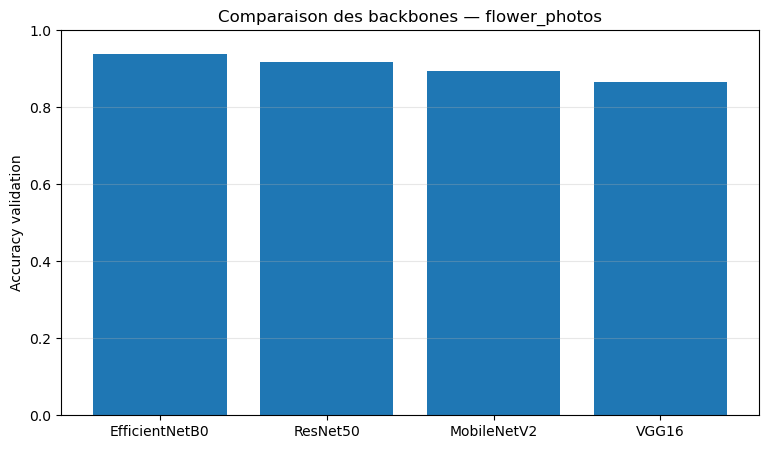

In [31]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Backbone"], results_df["Accuracy validation"])
plt.ylabel("Accuracy validation")
plt.title("Comparaison des backbones — flower_photos")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 2.12 Comparaison des latences

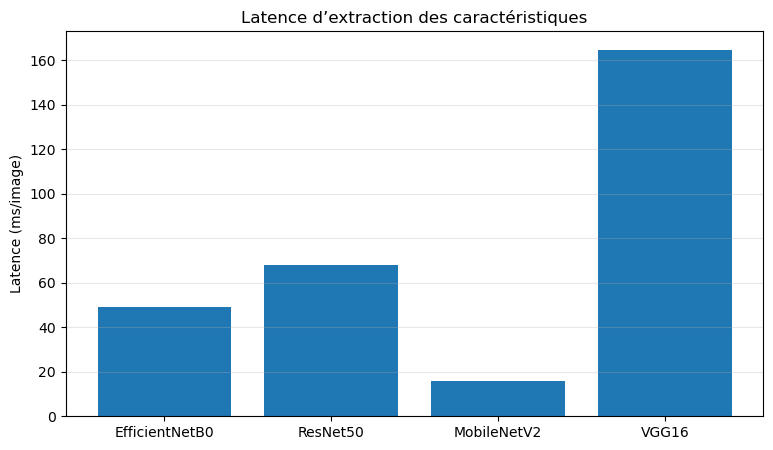

In [32]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Backbone"], results_df["Latence extraction validation (ms/image)"])
plt.ylabel("Latence (ms/image)")
plt.title("Latence d’extraction des caractéristiques")
plt.grid(axis="y", alpha=0.3)
plt.show()

> **Attention — la latence d'origine est peu fiable.**
> - Elle est mesurée en parcourant le `tf.data.Dataset` : elle **inclut la lecture du fichier, le décodage JPEG et le redimensionnement**, c'est-à-dire des coûts indépendants du modèle.
> - Preuve de l'instabilité : MobileNetV2 affiche **29,8 ms/image** sur l'entraînement mais **56,0 ms/image** sur la validation, pour le même modèle. Une latence ne peut pas varier d'un facteur 2 d'un jeu à l'autre ; c'est du bruit de mesure (disque, cache, charge CPU, premier passage).
> - Seuls les ordres de grandeur massifs sont donc fiables (VGG16 ≈ 4 fois plus lent qu'EfficientNetB0). Pour départager EfficientNetB0 et MobileNetV2, il faut un **benchmark propre** : c'est l'objet de la section suivante.
> - De plus, ces mesures sont faites sur **CPU** (aucun GPU détecté) et ne se transposent pas directement à un smartphone ARM ni à un serveur GPU.

### 2.12b Benchmark de latence propre (complément)

Mesure du **modèle seul** (prétraitement + tronc), sur un tenseur aléatoire déjà en mémoire, compilé avec `tf.function`, **médiane** de plusieurs répétitions après échauffement. Deux régimes : `batch = 1` (une photo à la fois, cas du smartphone) et `batch = 32` (débit serveur). Mettre `RUN_LATENCY_BENCH = False` pour sauter.

,Backbone,Latence propre batch=1 (ms),Latence propre batch=32 (ms/image)
0,VGG16,90.92,125.63
1,ResNet50,89.07,46.80
2,MobileNetV2,19.49,10.13
3,EfficientNetB0,28.00,13.58



Lecture automatique : le plus rapide à batch=1 est MobileNetV2 (19.5 ms), le plus lent est VGG16 (90.9 ms), soit un facteur 4.7.
Classement (du plus rapide au plus lent, batch=1) : MobileNetV2 < EfficientNetB0 < ResNet50 < VGG16


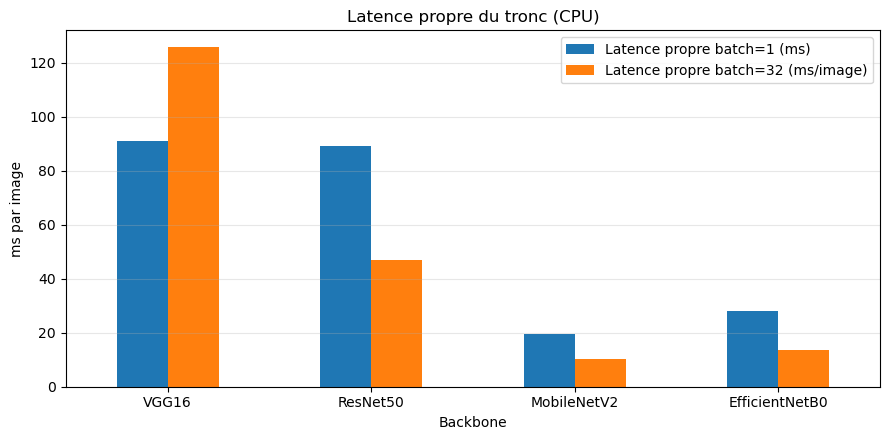

In [33]:
RUN_LATENCY_BENCH = True

def bench_latency(model, preprocess, batch, reps):
    """Latence médiane (ms par image) du modèle seul, hors lecture/décodage des images."""
    @tf.function
    def f(z):
        return model(preprocess(z), training=False)
    xb = tf.random.uniform((batch, 224, 224, 3), 0.0, 255.0, seed=SEED)
    for _ in range(3):                      # échauffement (compilation du graphe)
        f(xb).numpy()
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter()
        f(xb).numpy()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts)) * 1000.0 / batch

if RUN_LATENCY_BENCH:
    bench_rows = []
    for name, (constructor, preprocess) in BACKBONES.items():
        bb = build_backbone(constructor)
        bench_rows.append({
            "Backbone": name,
            "Latence propre batch=1 (ms)": bench_latency(bb, preprocess, batch=1, reps=30),
            "Latence propre batch=32 (ms/image)": bench_latency(bb, preprocess, batch=32, reps=5),
        })
        del bb
        tf.keras.backend.clear_session(); gc.collect()
    bench_df = pd.DataFrame(bench_rows)
    display(bench_df.style.format({c: "{:.2f}" for c in bench_df.columns if c != "Backbone"}))

    ref = bench_df.set_index("Backbone")["Latence propre batch=1 (ms)"]
    fastest = ref.idxmin(); slowest = ref.idxmax()
    print(f"\nLecture automatique : le plus rapide à batch=1 est {fastest} ({ref.min():.1f} ms), "
          f"le plus lent est {slowest} ({ref.max():.1f} ms), soit un facteur {ref.max()/ref.min():.1f}.")
    ranking = " < ".join(ref.sort_values().index)
    print("Classement (du plus rapide au plus lent, batch=1) :", ranking)

    ax = bench_df.set_index("Backbone").plot.bar(figsize=(9, 4.5), rot=0)
    ax.set_ylabel("ms par image"); ax.set_title("Latence propre du tronc (CPU)"); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print("Benchmark désactivé.")

### 2.12c Compromis précision / coût (front de Pareto)

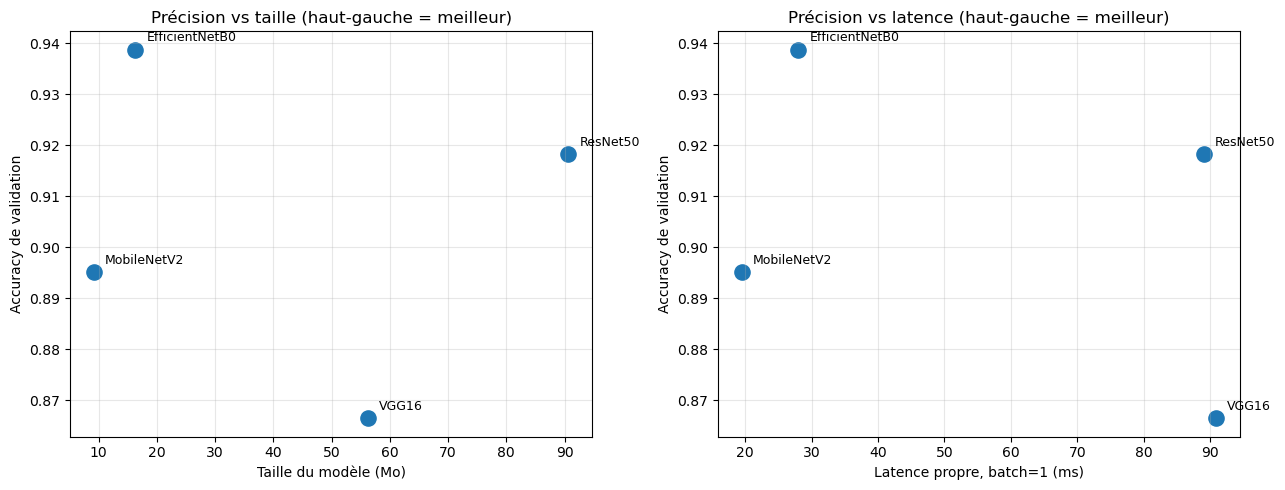

Backbones dominés (un autre est à la fois plus précis, plus petit et plus rapide) : ['ResNet50', 'VGG16']
Backbones sur le front de Pareto : ['EfficientNetB0', 'MobileNetV2']


In [34]:
lat_col = "Latence extraction validation (ms/image)"
plot_df = results_df.copy()
lat_label = "Latence d'origine (ms/image, inclut le décodage)"
if "bench_df" in globals():
    plot_df = plot_df.merge(bench_df[["Backbone", "Latence propre batch=1 (ms)"]], on="Backbone")
    lat_col = "Latence propre batch=1 (ms)"
    lat_label = "Latence propre, batch=1 (ms)"

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, xcol, xlabel in [(axes[0], "Taille modèle Keras (Mo)", "Taille du modèle (Mo)"),
                         (axes[1], lat_col, lat_label)]:
    ax.scatter(plot_df[xcol], plot_df["Accuracy validation"], s=120)
    for _, r in plot_df.iterrows():
        ax.annotate(r["Backbone"], (r[xcol], r["Accuracy validation"]),
                    textcoords="offset points", xytext=(8, 6), fontsize=9)
    ax.set_xlabel(xlabel); ax.set_ylabel("Accuracy de validation"); ax.grid(alpha=0.3)
axes[0].set_title("Précision vs taille (haut-gauche = meilleur)")
axes[1].set_title("Précision vs latence (haut-gauche = meilleur)")
plt.tight_layout(); plt.show()

# Modèles dominés : un modèle est dominé s'il existe un autre modèle meilleur ou égal partout et strictement meilleur quelque part
def dominated(df, cols_min, col_max):
    out = []
    for i, a in df.iterrows():
        for j, b in df.iterrows():
            if i == j: continue
            ok = all(b[c] <= a[c] for c in cols_min) and b[col_max] >= a[col_max]
            strict = any(b[c] < a[c] for c in cols_min) or b[col_max] > a[col_max]
            if ok and strict:
                out.append(a["Backbone"]); break
    return out

dom = dominated(plot_df, ["Taille modèle Keras (Mo)", lat_col], "Accuracy validation")
print("Backbones dominés (un autre est à la fois plus précis, plus petit et plus rapide) :", dom or "aucun")
print("Backbones sur le front de Pareto :", [b for b in plot_df["Backbone"] if b not in dom])

## 2.13 Matrices de confusion

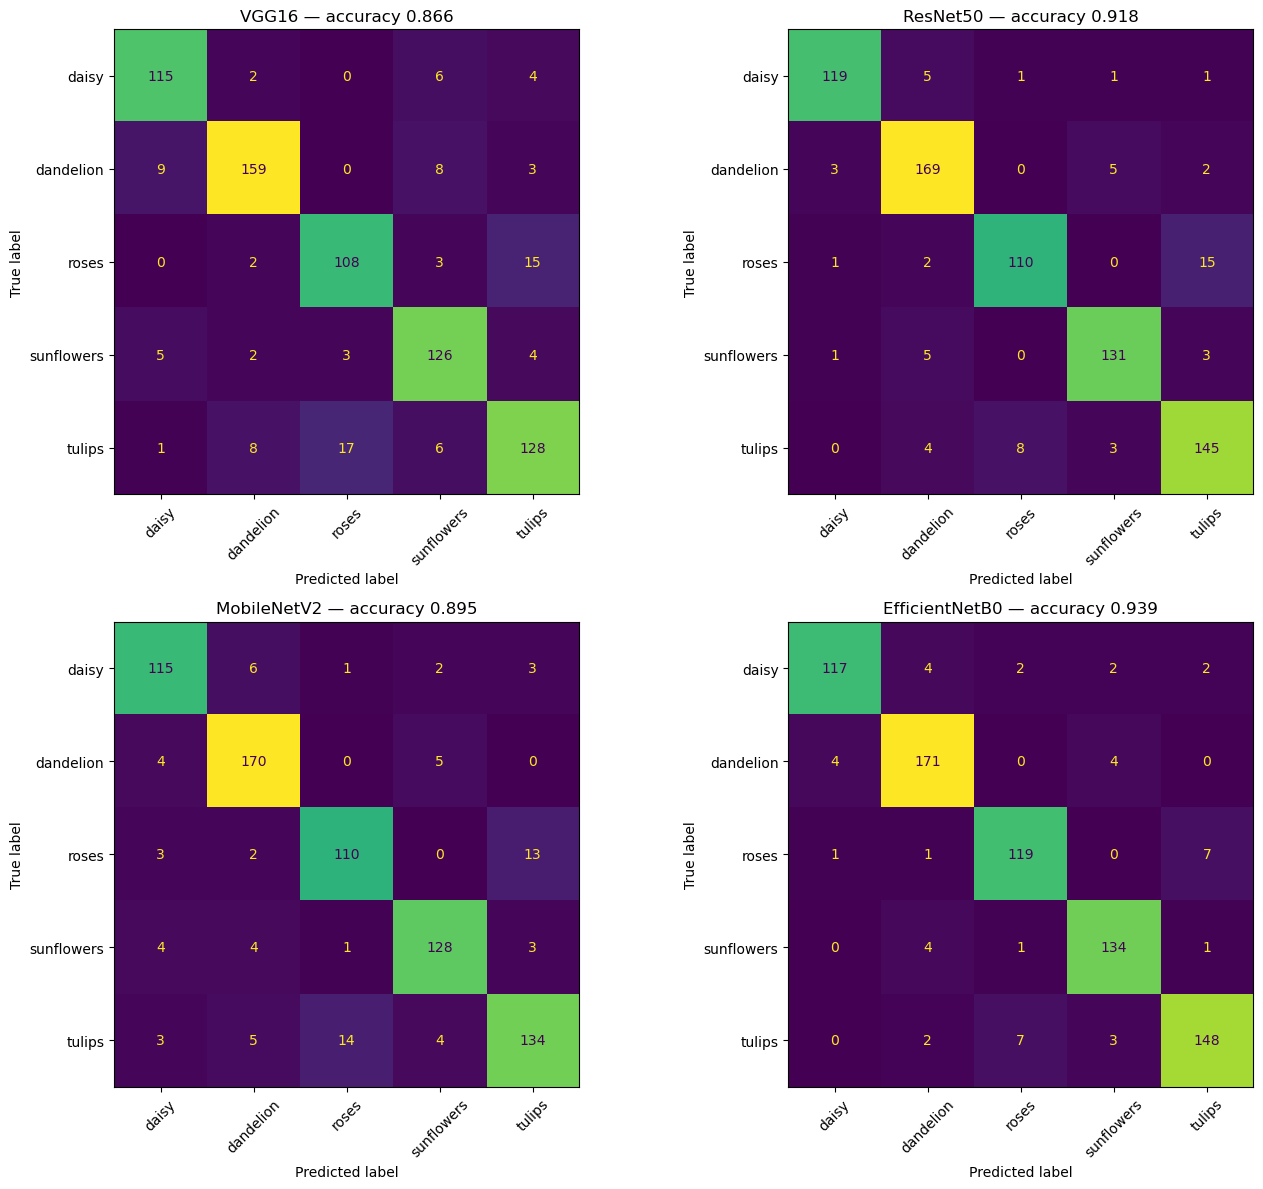

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, name in zip(axes.ravel(), BACKBONES.keys()):
    item = feature_store[name]
    cm = confusion_matrix(item["y_val"], item["y_pred"], labels=np.arange(num_classes))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False, values_format="d")
    ax.set_title(f"{name} — accuracy {accuracy_score(item['y_val'], item['y_pred']):.3f}")
plt.tight_layout()
plt.show()

> **Analyse — Matrices de confusion**
> - **Confusion dominante : rose ↔ tulipe**, pour tous les backbones. Nombre d'erreurs rose→tulipe / tulipe→rose : VGG16 15 / 17, ResNet50 15 / 8, MobileNetV2 13 / 14, **EfficientNetB0 7 / 7**. EfficientNetB0 divise cette confusion par environ deux, ce qui explique l'essentiel de son avance en accuracy.
> - **Pissenlit** : la classe la mieux reconnue (rappel de 89 % pour VGG16, 94 à 96 % pour les autres) : forme sphérique, jaune/blanc, très typée.
> - Les erreurs sont **sémantiquement plausibles** (fleurs de couleur et de forme voisines, souvent photographiées en bouquet) et non aléatoires : c'est le signe que les caractéristiques sont bonnes et que la limite vient de l'ambiguïté visuelle de certaines photos.
> - Ces confusions sont les mêmes que celles du modèle MobileNetV2 fine-tuné de l'exercice 1 (tulipe → rose : 14) : elles tiennent aux **données**, pas au choix de l'architecture.
> - Vérification de cohérence : aucune accuracy proche de 20 %, donc pas de désalignement image/label.

## 2.14 t-SNE pour deux backbones (mêmes images)

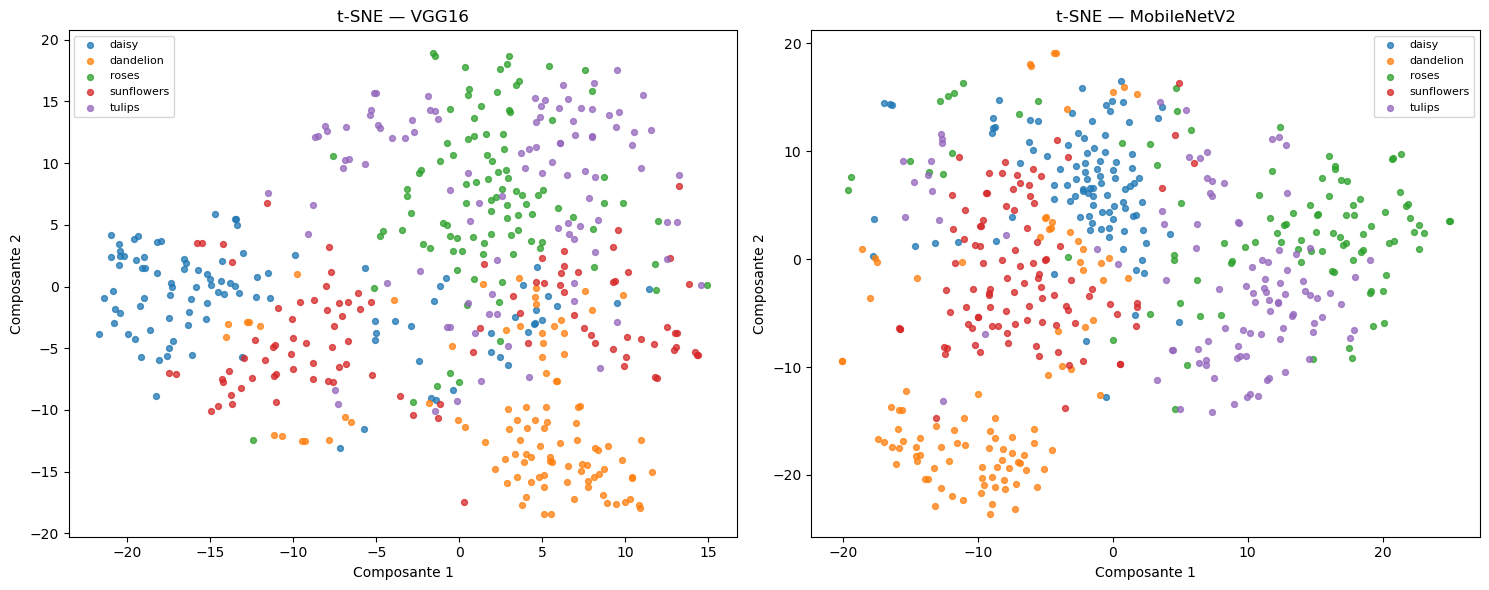

In [36]:
TSNE_BACKBONES = ["VGG16", "MobileNetV2"]
N_PER_CLASS = 100
rng = np.random.default_rng(SEED)
chosen = []
for class_id in range(num_classes):
    idx = np.where(e2_y_val == class_id)[0]
    n = min(N_PER_CLASS, len(idx))
    chosen.extend(rng.choice(idx, size=n, replace=False).tolist())
chosen = np.array(sorted(chosen))
y_tsne = e2_y_val[chosen]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name in zip(axes, TSNE_BACKBONES):
    X = feature_store[name]["F_val"][chosen]
    perplexity = min(30, max(2, (len(X) - 1) // 3))
    embedding = TSNE(n_components=2, random_state=SEED, perplexity=perplexity,
                     init="pca", learning_rate="auto").fit_transform(X)
    for class_id, class_name in enumerate(class_names):
        mask = y_tsne == class_id
        ax.scatter(embedding[mask, 0], embedding[mask, 1], label=class_name, s=18, alpha=0.75)
    ax.set_title(f"t-SNE — {name}")
    ax.set_xlabel("Composante 1")
    ax.set_ylabel("Composante 2")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

> **Analyse — t-SNE (VGG16 vs MobileNetV2, 500 images de validation, 100 par classe)**
> - **Pissenlit** forme l'amas le plus compact et le plus isolé dans les deux projections (en bas à droite pour VGG16, en bas à gauche pour MobileNetV2) : cohérent avec son meilleur rappel.
> - **Rose et tulipe se chevauchent fortement**, surtout avec VGG16 où les deux nuages se superposent presque dans le coin haut-droit. Avec MobileNetV2, ils occupent une même région mais avec davantage de structure et moins de mélange. C'est la signature visuelle de la confusion rose ↔ tulipe des matrices.
> - **Marguerite** et **tournesol** sont séparées du reste, mais plus **diffuses** : ces classes ont des images plus variées (gros plan, champ, bouquet).
> - **Lien avec les accuracies** : un nuage mieux séparé en 2D correspond à une meilleure accuracy de la régression logistique (89,5 % pour MobileNetV2 contre 86,7 % pour VGG16) ; la différence se voit surtout dans la netteté des frontières entre classes voisines.
> - **Limites de lecture** : t-SNE préserve les voisinages locaux mais **déforme les distances globales** ; la taille des amas et la distance entre amas ne sont pas interprétables. Un recouvrement en 2D ne prouve pas la non-séparabilité en 1 280 dimensions : le classifieur travaille dans l'espace complet. On interprète donc t-SNE **avec** les matrices de confusion, jamais seul.

## 2.15 Prédictions Top-1 / Top-5 avec les têtes ImageNet complètes

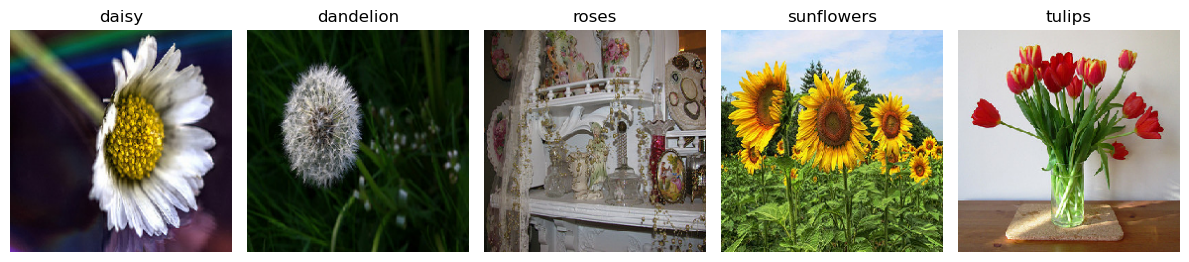

In [37]:
IMAGENET_MODELS = {
    "VGG16": VGG16,
    "ResNet50": ResNet50,
    "MobileNetV2": MobileNetV2,
    "EfficientNetB0": EfficientNetB0
}
IMAGENET_PREPROCESS = {
    "VGG16": vgg_preprocess,
    "ResNet50": resnet_preprocess,
    "MobileNetV2": mobilenet_preprocess,
    "EfficientNetB0": efficientnet_preprocess
}

# Une image de validation par classe, si disponible.
sample_indices = []
for class_id in range(num_classes):
    idx = np.where(e2_y_val == class_id)[0]
    if len(idx):
        sample_indices.append(int(idx[0]))
sample_paths = e2_val_paths[sample_indices[:5]]
sample_labels = e2_y_val[sample_indices[:5]]
sample_images = np.stack([
    tf.keras.utils.img_to_array(tf.keras.utils.load_img(p, target_size=IMG_SIZE))
    for p in sample_paths
]).astype(np.float32)

plt.figure(figsize=(12, 4))
for i, (p, label) in enumerate(zip(sample_paths, sample_labels)):
    plt.subplot(1, len(sample_paths), i + 1)
    plt.imshow(tf.keras.utils.load_img(p, target_size=IMG_SIZE))
    plt.title(class_names[label])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [38]:
top5_rows = []
for name, constructor in IMAGENET_MODELS.items():
    print("\n" + "=" * 65 + "\nImageNet complet :", name)
    model = constructor(weights="imagenet", include_top=True, input_shape=(224, 224, 3))
    x = IMAGENET_PREPROCESS[name](tf.convert_to_tensor(sample_images))
    probs = model(x, training=False).numpy()
    decoded = decode_predictions(probs, top=5)

    for path, true_label, predictions in zip(sample_paths, sample_labels, decoded):
        print("\nImage :", Path(path).name, "| classe flower_photos :", class_names[true_label])
        for rank, (synset, label, score) in enumerate(predictions, start=1):
            print(f"Top-{rank}: {label:30s} score={score:.4f}")
            top5_rows.append({
                "Backbone": name, "Image": Path(path).name,
                "Classe réelle flower_photos": class_names[true_label],
                "Rang": rank, "Classe prédite ImageNet": label, "Score": float(score)
            })
    del model
    tf.keras.backend.clear_session()
    gc.collect()

top5_df = pd.DataFrame(top5_rows)
display(top5_df)
top5_df.to_csv(OUTPUT_DIR / "predictions_imagenet_top5.csv", index=False)


ImageNet complet : VGG16

Image : 4565255237_9ba29c4d4e_n.jpg | classe flower_photos : daisy
Top-1: daisy                          score=0.9595
Top-2: bee                            score=0.0141
Top-3: hummingbird                    score=0.0061
Top-4: fly                            score=0.0032
Top-5: pineapple                      score=0.0020

Image : 3675486971_d4c8683b54_n.jpg | classe flower_photos : dandelion
Top-1: buckeye                        score=0.3335
Top-2: sea_urchin                     score=0.2808
Top-3: cardoon                        score=0.2749
Top-4: porcupine                      score=0.0426
Top-5: mushroom                       score=0.0087

Image : 3655527028_0fab2b547d_n.jpg | classe flower_photos : roses
Top-1: altar                          score=0.9460
Top-2: vault                          score=0.0133
Top-3: throne                         score=0.0123
Top-4: vestment                       score=0.0054
Top-5: monastery                      score=0.0037



,Backbone,Image,Classe réelle flower_photos,Rang,Classe prédite ImageNet,Score
0,VGG16,4565255237_9ba29c4d4e_n.jpg,daisy,1,daisy,0.959536
1,VGG16,4565255237_9ba29c4d4e_n.jpg,daisy,2,bee,0.014075
2,VGG16,4565255237_9ba29c4d4e_n.jpg,daisy,3,hummingbird,0.006139
3,VGG16,4565255237_9ba29c4d4e_n.jpg,daisy,4,fly,0.003153
4,VGG16,4565255237_9ba29c4d4e_n.jpg,daisy,5,pineapple,0.002041
...,...,...,...,...,...,...
95,EfficientNetB0,12873145295_438b8197a7_n.jpg,tulips,1,vase,0.938990
96,EfficientNetB0,12873145295_438b8197a7_n.jpg,tulips,2,pot,0.021489
97,EfficientNetB0,12873145295_438b8197a7_n.jpg,tulips,3,pitcher,0.015415
98,EfficientNetB0,12873145295_438b8197a7_n.jpg,tulips,4,tray,0.002523


> **Analyse — Top-1 / Top-5 avec la tête ImageNet complète**
>
> La tête ImageNet classe parmi **1 000 catégories**, dont une seule correspond à nos cinq fleurs : *daisy*. Les autres espèces **n'existent pas dans l'espace d'étiquettes**, quelle que soit la qualité du modèle.
>
> | Image (classe réelle) | Top-1 observé | Pourquoi |
> |---|---|---|
> | **Marguerite** | *daisy* sur les 4 modèles (score 0,69 à 0,98) | **Seul cas « juste »** : la classe existe dans ImageNet. |
> | **Pissenlit** | *buckeye*, *sea_urchin*, *cardoon*, *porcupine*, *daisy* (scores faibles, 0,21 à 0,37) | Pas de classe « pissenlit ». Le modèle choisit des objets **ronds et épineux** voisins par la forme. Prédictions hors sujet, mais non aléatoires. |
> | **Rose** | *altar* (0,75 à 0,95), *plate_rack*, *china_cabinet* | Pas de classe « rose ». Le modèle réagit au **contexte** (scène d'intérieur, décor) et non à la fleur. |
> | **Tournesol** | *daisy* (0,34 à 0,88) | Pas de classe « tournesol » : le modèle choisit la **fleur la plus proche** qu'il connaît. |
> | **Tulipe** | *vase* (0,92 à 0,99) sur les 4 modèles | La tulipe est dans un vase : le modèle nomme **l'objet dominant** (le contenant), pas la fleur. |
>
> **Enseignements**
> 1. Les prédictions sont « justes » uniquement quand la **classe cible existe dans ImageNet** ; sinon le modèle retombe sur ce qui y ressemble (forme, contexte, objet voisin). Le **Top-5 ne rattrape rien** quand le concept est absent de l'espace d'étiquettes.
> 2. **Les scores sont trompeurs** : *altar* à 0,95 (VGG16) pour une rose, *vase* à 0,99 (ResNet50) pour une tulipe. Un softmax donne de fortes probabilités même hors de son domaine : la **confiance n'est pas une preuve de justesse**.
> 3. ImageNet est un jeu **mono-étiquette orienté objet** : sur une photo à plusieurs éléments, il privilégie l'objet saillant (vase, autel, étagère).
> 4. **Pourtant, les caractéristiques internes de ces mêmes réseaux séparent très bien les fleurs** (87 à 94 % avec une simple régression logistique). C'est précisément ce que justifie le **transfert inductif** : on garde le tronc, on remplace la tête.
> 5. **Prudence** : une seule image par classe est testée. Ces observations illustrent le mécanisme ; elles ne constituent pas une mesure statistique.

## 2.16 Recommandations

**Décision fondée sur les mesures du tableau (accuracy, taille, latence relative) et sur les contraintes de chaque scénario.**

| Critère | EfficientNetB0 | ResNet50 | MobileNetV2 | VGG16 |
|---|---|---|---|---|
| Accuracy (régression logistique) | **93,9 %** | 91,8 % | 89,5 % | 86,7 % |
| Paramètres du tronc | 4,05 M | 23,59 M | **2,26 M** | 14,71 M |
| Taille du modèle | 16,3 Mo | 90,7 Mo | **9,2 Mo** | 56,2 Mo |
| Latence (ordre de grandeur CPU) | rapide | moyenne | **rapide** | lente (×4) |
| Verdict | **Serveur GPU** | Alternative serveur | **Smartphone** | À écarter |

#### (a) Serveur cloud avec GPU → **EfficientNetB0**
- C'est le **plus précis** (93,9 %), et il est **aussi plus petit et plus rapide** que ResNet50 et VGG16 dans nos mesures : aucun compromis à faire.
- Sur GPU, les écarts de latence entre modèles se **compressent** (le calcul est massivement parallèle) : la **précision devient le critère dominant**, et la taille compte peu côté serveur.
- **ResNet50** reste une alternative sérieuse (écosystème très mature, noyaux GPU très optimisés), mais il est 2 points en dessous ici et 5,6 fois plus lourd. **VGG16** est dominé sur tous les axes.
- Pistes pour monter encore : fine-tuning, ou variantes EfficientNet plus grandes (B3 à B4), **non testées ici**.

#### (b) Smartphone d'entrée de gamme, hors ligne → **MobileNetV2**
- **Le plus petit** (9,2 Mo, 2,26 M de paramètres) et conçu pour le mobile (convolutions séparables en profondeur, activations ReLU6 favorables à la quantification entière).
- **Coût en précision** : −4,4 points par rapport à EfficientNetB0 *en extraction pure*. Ce coût est **atténuable** : l'exercice 1 montre MobileNetV2 à 90,2 % (extraction) et 90,6 % (fine-tuning) avec une entrée de 160×160, ce qui réduit aussi la latence.
- **Pour la production** : conversion **TensorFlow Lite** et **quantification int8** (modèle environ 4 fois plus léger, inférence plus rapide sur CPU ARM).
- **Alternative** : EfficientNetB0 (16 Mo) si une mesure **sur le téléphone cible** montre que la latence reste acceptable ; ses blocs *swish* et *squeeze-and-excitation* sont en général moins bien accélérés sur matériel d'entrée de gamme (d'où l'existence de variantes « Lite »).

#### Limites de cette recommandation
- Les latences mesurées ici sont sur **CPU de PC**, pas sur ARM ni GPU : la décision finale doit s'appuyer sur un **benchmark sur l'appareil réel**.
- Les écarts de 2 points (EfficientNetB0 / ResNet50) sont **à la limite du bruit** de la validation (± 2,2 points) ; une validation croisée confirmerait le classement.
- Aucun fine-tuning des backbones n'a été fait dans cet exercice : le classement pourrait légèrement évoluer.

## 2.17 Vérifications finales et fichiers générés

In [39]:
for name in BACKBONES:
    item = feature_store[name]
    print(
        f"{name}: train={item['F_train'].shape}, val={item['F_val'].shape}, "
        f"labels train alignés={np.array_equal(item['y_train'], e2_y_train)}, "
        f"labels val alignés={np.array_equal(item['y_val'], e2_y_val)}, "
        f"accuracy={accuracy_score(item['y_val'], item['y_pred']):.4f}"
    )

print("\nFichiers produits dans :", OUTPUT_DIR.resolve())
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size / (1024**2):.2f} Mo")

VGG16: train=(2936, 512), val=(734, 512), labels train alignés=True, labels val alignés=True, accuracy=0.8665
ResNet50: train=(2936, 2048), val=(734, 2048), labels train alignés=True, labels val alignés=True, accuracy=0.9183
MobileNetV2: train=(2936, 1280), val=(734, 1280), labels train alignés=True, labels val alignés=True, accuracy=0.8951
EfficientNetB0: train=(2936, 1280), val=(734, 1280), labels train alignés=True, labels val alignés=True, accuracy=0.9387

Fichiers produits dans : C:\Users\hp\Downloads\backbone_outputs
comparaison_backbones.csv: 0.00 Mo
EfficientNetB0_flower_model.keras: 16.28 Mo
EfficientNetB0_logistic_head.joblib: 0.05 Mo
MobileNetV2_flower_model.keras: 9.20 Mo
MobileNetV2_logistic_head.joblib: 0.05 Mo
predictions_imagenet_top5.csv: 0.01 Mo
ResNet50_flower_model.keras: 90.65 Mo
ResNet50_logistic_head.joblib: 0.08 Mo
VGG16_flower_model.keras: 56.23 Mo
VGG16_logistic_head.joblib: 0.02 Mo


---
# Partie 3 — Exercice 3 : Apprentissage multitâche pour un catalogue e-commerce

**Contexte.** La plateforme e-commerce veut prédire **simultanément**, avec **un seul modèle**, la **catégorie fine** d'un article (10 classes) et sa **famille** (4 classes : hauts, bas et robes, chaussures, accessoires) utilisée pour la navigation du site. Un modèle unique réduirait le coût d'inférence.

**Données.** Fashion-MNIST (images 28×28 en niveaux de gris, 60 000 en entraînement, 10 000 en test).
- **Tâche A** : catégorie fine (10 classes).
- **Tâche B** : famille (4 classes), construite par la correspondance `famille = [0, 1, 0, 1, 0, 2, 0, 2, 3, 2]`.

**Travail demandé.**
1. Construire les étiquettes de la tâche B.
2. Entraîner **deux modèles mono-tâche** avec la même architecture convolutive.
3. Construire un **modèle multitâche** (API fonctionnelle) : tronc partagé + une tête Softmax par tâche.
4. Comparer mono / multi : **paramètres, accuracy de chaque tâche, temps d'inférence**.
5. Faire varier **λ_B ∈ {0,1 ; 0,5 ; 1 ; 2 ; 5}** (avec λ_A = 1).
6. **Régime peu de données** : refaire la comparaison avec 3 000 images.
7. Mesurer la **proportion de prédictions incohérentes** et proposer une solution.

**Fonction de coût multitâche** : L_total = λ_A · L_A + λ_B · L_B (équation 2 du sujet).

### Choix méthodologiques
- **Plusieurs graines** (`N_SEEDS = 3`) : les écarts attendus entre mono et multi sont de l'ordre du dixième de point ; une seule exécution ne permettrait aucune conclusion. On rapporte **moyenne ± écart-type**.
- **Jeu de validation** (6 000 images prises dans l'entraînement) pour suivre l'apprentissage ; le **jeu de test officiel** (10 000 images) ne sert qu'à l'évaluation finale.
- **Architecture identique** pour tous les modèles (le tronc est le même), de sorte que la seule différence entre mono et multi soit le **partage** du tronc.
- Temps total : de l'ordre de **25 à 50 minutes sur CPU** ; réduire `N_SEEDS` à 2 pour aller plus vite.

## 3.1 Configuration, données et étiquettes de la tâche B

Entraînement : (54000, 28, 28, 1) | Validation : (6000, 28, 28, 1) | Test : (10000, 28, 28, 1)


Famille,Accessoires,Bas et robes,Chaussures,Hauts
Catégorie,,,,
Basket,0,0,6000,0
Bottine,0,0,6000,0
Chemise,0,0,0,6000
Manteau,0,0,0,6000
Pantalon,0,6000,0,0
Pull,0,0,0,6000
Robe,0,6000,0,0
Sac,6000,0,0,0
Sandale,0,0,6000,0


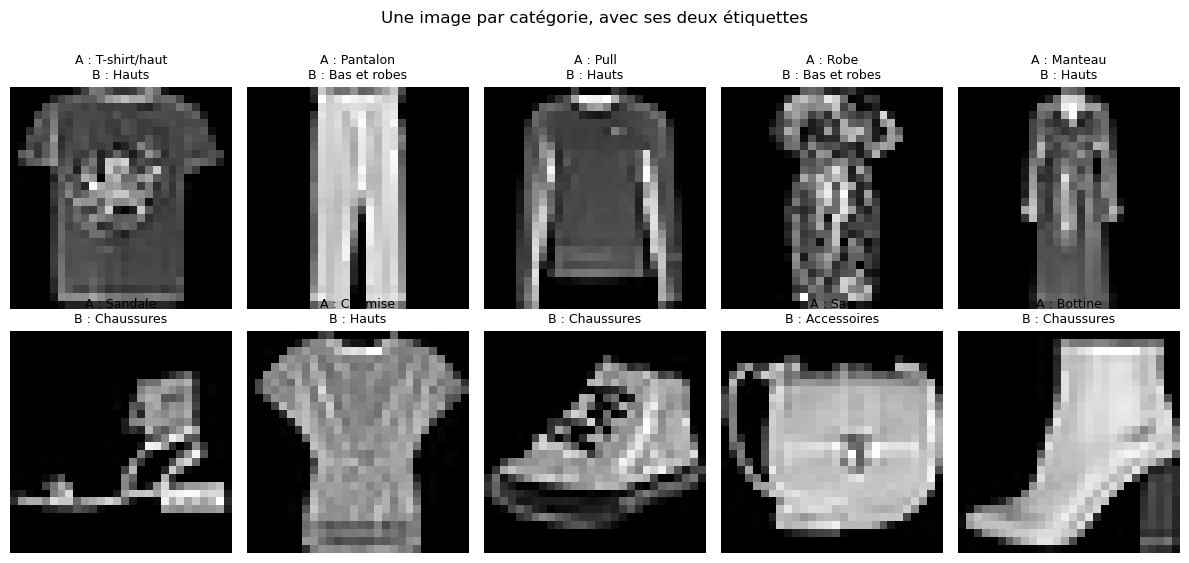

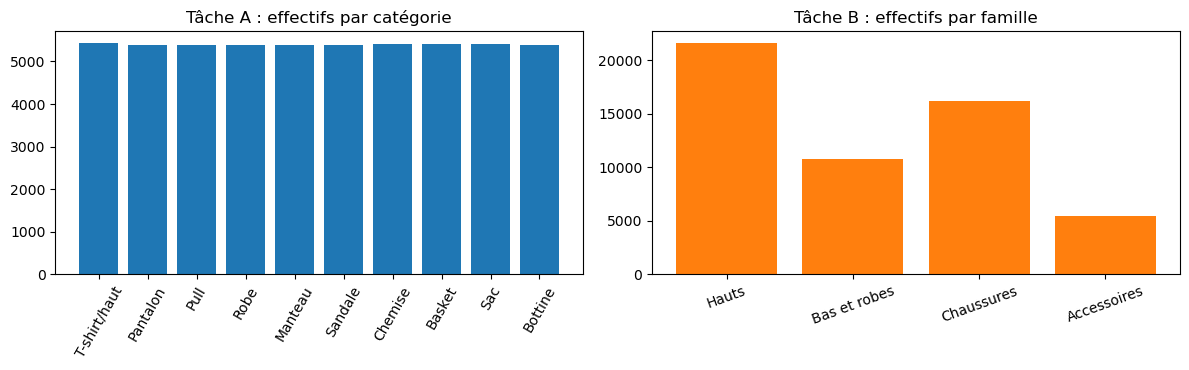

Référence « classe majoritaire » pour B : 40.0% | hasard pour A : 10 %


In [40]:
import time, gc
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import fashion_mnist
from sklearn.metrics import confusion_matrix

# ----- Paramètres de l'expérience -----
SEED3 = 42
N_SEEDS = 3                                   # nombre de répétitions (graines) ; 2 pour aller plus vite
SEEDS = [SEED3 + 17 * i for i in range(N_SEEDS)]
EPOCHS_FULL, BATCH_FULL = 8, 128              # régime données complètes
N_SMALL, EPOCHS_SMALL, BATCH_SMALL = 3000, 30, 64   # régime peu de données (plus d'époques : moins de pas par époque)
LAMBDA_B_MAIN = 0.5                           # pondération de la tâche B pour la comparaison principale (valeur du sujet)
LAMBDAS = [0.1, 0.5, 1, 2, 5]
LR3 = 1e-3

CAT_NAMES = ["T-shirt/haut", "Pantalon", "Pull", "Robe", "Manteau",
             "Sandale", "Chemise", "Basket", "Sac", "Bottine"]
FAM_NAMES = ["Hauts", "Bas et robes", "Chaussures", "Accessoires"]

# ----- Correspondance catégorie -> famille (fournie par le sujet) -----
famille = np.array([0, 1, 0, 1, 0, 2, 0, 2, 3, 2])

# ----- Chargement et normalisation -----
(x_tr_full, ya_tr_full), (x_te, ya_te) = fashion_mnist.load_data()
x_tr_full = x_tr_full.astype("float32")[..., None] / 255.0
x_te = x_te.astype("float32")[..., None] / 255.0

# Étiquettes de la tâche B (famille) à partir de la catégorie
yb_tr_full = famille[ya_tr_full]
yb_te = famille[ya_te]

# ----- Découpage entraînement (54 000) / validation (6 000) -----
perm = np.random.default_rng(SEED3).permutation(len(x_tr_full))
val_idx, tr_idx = perm[:6000], perm[6000:]
X_tr,  ya_tr,  yb_tr  = x_tr_full[tr_idx],  ya_tr_full[tr_idx],  yb_tr_full[tr_idx]
X_val, ya_val, yb_val = x_tr_full[val_idx], ya_tr_full[val_idx], yb_tr_full[val_idx]

print(f"Entraînement : {X_tr.shape} | Validation : {X_val.shape} | Test : {x_te.shape}")

# ----- Vérification de la correspondance : chaque catégorie doit tomber dans UNE seule famille -----
ct = pd.crosstab(pd.Series([CAT_NAMES[i] for i in ya_tr_full], name="Catégorie"),
                 pd.Series([FAM_NAMES[i] for i in yb_tr_full], name="Famille"))
display(ct)
assert (ct.gt(0).sum(axis=1) == 1).all(), "Une catégorie est répartie sur plusieurs familles !"

# ----- Visualisation -----
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for c, ax in enumerate(axes.ravel()):
    i = np.where(ya_tr == c)[0][0]
    ax.imshow(X_tr[i, ..., 0], cmap="gray"); ax.axis("off")
    ax.set_title(f"A : {CAT_NAMES[c]}\nB : {FAM_NAMES[famille[c]]}", fontsize=9)
plt.suptitle("Une image par catégorie, avec ses deux étiquettes", y=1.02); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(CAT_NAMES, np.bincount(ya_tr, minlength=10)); axes[0].set_title("Tâche A : effectifs par catégorie")
axes[0].tick_params(axis="x", rotation=60)
axes[1].bar(FAM_NAMES, np.bincount(yb_tr, minlength=4), color="tab:orange"); axes[1].set_title("Tâche B : effectifs par famille")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print("Référence « classe majoritaire » pour B :", f"{np.bincount(yb_te).max() / len(yb_te):.1%}", "| hasard pour A :", "10 %")

> **Analyse — Données et construction de la tâche B**
> - La table de contingence montre que **chaque catégorie est affectée à une seule famille** (vérifié par un `assert`) : la tâche B est une **fonction déterministe de la tâche A**.
> - **Répartition de B déséquilibrée** : *Hauts* regroupe 4 catégories (40 % des images), *Chaussures* 3 (30 %), *Bas et robes* 2 (20 %), *Accessoires* une seule (10 %, uniquement les sacs). Le classifieur « toujours Hauts » atteindrait 40 % : c'est la référence à battre pour B (celle de A est 10 %).
> - **Conséquence théorique importante.** Comme B se déduit de A, l'étiquette B **n'apporte aucune information nouvelle** sur l'image : elle apporte seulement une **supervision plus grossière** (regroupement de classes proches). On s'attend donc à ce que le multitâche **n'améliore pas beaucoup** la tâche A ; son intérêt principal est le **coût** (un seul tronc au lieu de deux) et, éventuellement, un effet de **régularisation**. C'est un cas de tâches **très liées**, plutôt favorable au partage, mais sans information complémentaire.
> - **Difficulté de A concentrée sur 4 catégories** (T-shirt, chemise, pull, manteau), toutes de la famille *Hauts* : on pourra vérifier qu'une grande partie des erreurs de A restent **à l'intérieur d'une même famille** (section 3.9).

## 3.2 Architecture : tronc convolutif partagé, têtes mono-tâche et multitâche

Le tronc s'inspire de l'architecture `blocs4` du TP3, adaptée aux images 28×28 : trois blocs convolutifs (32, 64, 64 filtres, noyau 3×3), deux `MaxPooling` (28 → 14 → 7), puis `Flatten` et `Dense(128)` avec `Dropout(0,3)`. La sortie du tronc est le vecteur `features` (128 valeurs).

- **Mono-tâche** : tronc + une tête `Dense(softmax)`.
- **Multitâche** : le **même** tronc, partagé, + deux têtes `categorie` (10 classes) et `famille` (4 classes), avec pertes `sparse_categorical_crossentropy` pondérées par λ_A = 1 et λ_B.
- **Multitâche à tête B dérivée** (variante proposée pour la question 7) : la tête `famille` n'est plus apprise ; elle est **calculée** à partir des probabilités de la tête `categorie` (p_B = p_A · M, où M est la matrice 10×4 de correspondance), c'est-à-dire que p_B est la **loi marginale** de p_A sur les familles. Les deux **distributions** sont alors cohérentes par construction ; pour que les **décisions** le soient aussi, il faut un décodage adapté (section 3.9).

In [41]:
# Matrice de correspondance catégorie -> famille (10 x 4) : M[c, famille[c]] = 1
M_FAM = np.zeros((10, 4), dtype="float32")
M_FAM[np.arange(10), famille] = 1.0

def build_trunk(inputs):
    """Tronc convolutif partagé (identique pour tous les modèles). Retourne le vecteur 'features'."""
    x = layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1")(inputs)
    x = layers.MaxPooling2D(2, name="pool1")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2")(x)
    x = layers.MaxPooling2D(2, name="pool2")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu", name="conv3")(x)
    x = layers.Flatten(name="flatten")(x)
    x = layers.Dense(128, activation="relu", name="features_dense")(x)
    features = layers.Dropout(0.3, name="dropout")(x)
    return features

def build_mono(task, seed):
    """Modèle mono-tâche : task = 'categorie' (10 classes) ou 'famille' (4 classes)."""
    keras.backend.clear_session(); keras.utils.set_random_seed(seed)
    inputs = keras.Input(shape=(28, 28, 1), name="image")
    features = build_trunk(inputs)
    n_out = 10 if task == "categorie" else 4
    out = layers.Dense(n_out, activation="softmax", name=task)(features)
    model = keras.Model(inputs, out, name=f"mono_{task}")
    model.compile(optimizer=keras.optimizers.Adam(LR3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def build_multi(lambda_b, seed, coherent=False):
    """Modèle multitâche (tronc partagé, deux têtes). coherent=True : tête famille dérivée de la tête catégorie."""
    keras.backend.clear_session(); keras.utils.set_random_seed(seed)
    inputs = keras.Input(shape=(28, 28, 1), name="image")
    features = build_trunk(inputs)
    out_a = layers.Dense(10, activation="softmax", name="categorie")(features)
    if coherent:
        head_b = layers.Dense(4, use_bias=False, name="famille")   # p_B = p_A . M  (somme des probas par famille)
        out_b = head_b(out_a)
        head_b.set_weights([M_FAM]); head_b.trainable = False
    else:
        out_b = layers.Dense(4, activation="softmax", name="famille")(features)
    model = keras.Model(inputs, {"categorie": out_a, "famille": out_b},
                        name="multi_coherent" if coherent else "multi")
    model.compile(optimizer=keras.optimizers.Adam(LR3),
                  loss={"categorie": "sparse_categorical_crossentropy",
                        "famille": "sparse_categorical_crossentropy"},
                  loss_weights={"categorie": 1.0, "famille": float(lambda_b)},
                  metrics={"categorie": ["accuracy"], "famille": ["accuracy"]})
    return model

# Aperçu : paramètres de chaque composant
_m = build_multi(LAMBDA_B_MAIN, SEEDS[0])
n_total = _m.count_params()
n_head_a = _m.get_layer("categorie").count_params(); n_head_b = _m.get_layer("famille").count_params()
print(f"Multitâche : {n_total:,} paramètres au total")
print(f"  tronc partagé : {n_total - n_head_a - n_head_b:,} | tête catégorie : {n_head_a:,} | tête famille : {n_head_b:,}")
_m.summary()
del _m; keras.backend.clear_session()

Multitâche : 459,086 paramètres au total
  tronc partagé : 457,280 | tête catégorie : 1,290 | tête famille : 516


Model: "multi"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 28, 28, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 28, 28,    │        320 │ image[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 14, 14,    │          0 │ conv1[0][0]       │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2 (Conv2D)      │ (None, 14, 14,    │     18,496 │ pool1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 7, 7, 64)  │          0 │ conv2[0][0]       │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3 (Conv2D)      │ (None, 7, 7, 64)  │     36,928 │ pool2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv3[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ features_dense      │ (None, 128)       │    401,536 │ flatten[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ features_dense[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ categorie (Dense)   │ (None, 10)        │      1,290 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ famille (Dense)     │ (None, 4)         │        516 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 459,086 (1.75 MB)

 Trainable params: 459,086 (1.75 MB)

 Non-trainable params: 0 (0.00 B)

### Schéma de l'architecture multitâche

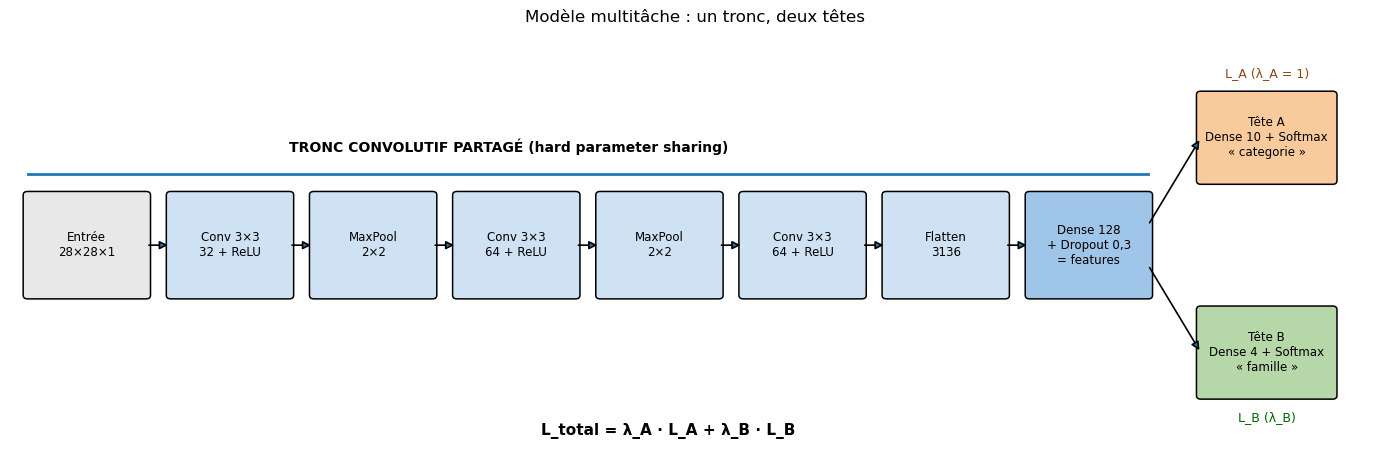

You must install pydot (`pip install pydot`) for `plot_model` to work.


None

In [42]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def draw_multitask_architecture():
    fig, ax = plt.subplots(figsize=(14, 4.8))
    ax.set_xlim(0, 15.6); ax.set_ylim(0, 6); ax.axis("off")

    def box(x, y, w, h, text, color):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=color, ec="black", lw=1.1))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8.5)

    def arrow(x1, y1, x2, y2):
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12, lw=1.2))

    trunk = [("Entrée\n28×28×1", "#e8e8e8"), ("Conv 3×3\n32 + ReLU", "#cfe2f3"), ("MaxPool\n2×2", "#cfe2f3"),
             ("Conv 3×3\n64 + ReLU", "#cfe2f3"), ("MaxPool\n2×2", "#cfe2f3"), ("Conv 3×3\n64 + ReLU", "#cfe2f3"),
             ("Flatten\n3136", "#cfe2f3"), ("Dense 128\n+ Dropout 0,3\n= features", "#9fc5e8")]
    x0, w, gap, y, h = 0.2, 1.35, 0.28, 2.3, 1.4
    for i, (t, c) in enumerate(trunk):
        xi = x0 + i * (w + gap)
        box(xi, y, w, h, t, c)
        if i > 0:
            arrow(xi - gap, y + h / 2, xi, y + h / 2)
    x_end = x0 + (len(trunk) - 1) * (w + gap) + w
    ax.text((x0 + x_end) / 2 - 0.9, 4.3, "TRONC CONVOLUTIF PARTAGÉ (hard parameter sharing)", ha="center", fontsize=10, fontweight="bold")
    ax.plot([x0, x_end], [4.0, 4.0], color="tab:blue", lw=2)

    xh = x_end + 0.6
    box(xh, 3.9, 1.5, 1.2, "Tête A\nDense 10 + Softmax\n« categorie »", "#f9cb9c")
    box(xh, 0.9, 1.5, 1.2, "Tête B\nDense 4 + Softmax\n« famille »", "#b6d7a8")
    arrow(x_end, y + h * 0.7, xh, 4.5); arrow(x_end, y + h * 0.3, xh, 1.5)
    ax.text(xh + 0.75, 5.35, "L_A (λ_A = 1)", ha="center", fontsize=9, color="saddlebrown")
    ax.text(xh + 0.75, 0.55, "L_B (λ_B)", ha="center", fontsize=9, color="darkgreen")
    ax.text(7.5, 0.35, "L_total = λ_A · L_A + λ_B · L_B", ha="center", fontsize=11, fontweight="bold")
    ax.set_title("Modèle multitâche : un tronc, deux têtes", fontsize=12)
    plt.tight_layout(); plt.show()

draw_multitask_architecture()

# Schéma généré par Keras (nécessite pydot + graphviz ; ignoré s'ils ne sont pas installés)
try:
    _m = build_multi(LAMBDA_B_MAIN, SEEDS[0])
    display(keras.utils.plot_model(_m, show_shapes=True, show_layer_names=True, dpi=70))
    del _m
except Exception as e:
    print("plot_model indisponible (pydot/graphviz absents) :", type(e).__name__)

## 3.3 Fonctions d'entraînement et d'évaluation

Une fonction unique `run(...)` entraîne un modèle (mono A, mono B, multi, multi à tête B dérivée) pour une graine, un λ_B et une taille d'entraînement donnés, **met le résultat en cache** (pour ne jamais réentraîner deux fois la même configuration) et calcule les métriques **directement à partir des prédictions** (robuste aux noms de métriques de Keras).

In [43]:
RUNS, MODELS = {}, {}      # RUNS : résultats ; MODELS : modèles conservés pour la graine de référence uniquement

def stratified_subset(ya, n, seed):
    """n images, réparties à parts égales entre les 10 catégories."""
    rng = np.random.default_rng(seed)
    per = n // 10
    idx = np.concatenate([rng.choice(np.where(ya == c)[0], per, replace=False) for c in range(10)])
    rng.shuffle(idx)
    return idx

def get_train_data(n_train, seed):
    if n_train is None:
        return X_tr, ya_tr, yb_tr, EPOCHS_FULL, BATCH_FULL
    idx = stratified_subset(ya_tr, n_train, seed)
    return X_tr[idx], ya_tr[idx], yb_tr[idx], EPOCHS_SMALL, BATCH_SMALL

def run(kind, seed, lam=None, n_train=None):
    """kind ∈ {'mono_A', 'mono_B', 'multi', 'multi_coh'}. Retourne un dictionnaire de résultats (mis en cache)."""
    key = (kind, None if lam is None else float(lam), seed, n_train)
    if key in RUNS:
        return RUNS[key]
    Xt, yat, ybt, epochs, batch = get_train_data(n_train, seed)

    if kind == "mono_A":
        model = build_mono("categorie", seed); y, yv = yat, ya_val
    elif kind == "mono_B":
        model = build_mono("famille", seed);   y, yv = ybt, yb_val
    else:
        model = build_multi(lam, seed, coherent=(kind == "multi_coh"))
        y, yv = {"categorie": yat, "famille": ybt}, {"categorie": ya_val, "famille": yb_val}

    t0 = time.perf_counter()
    hist = model.fit(Xt, y, validation_data=(X_val, yv), epochs=epochs, batch_size=batch, verbose=0)
    train_time = time.perf_counter() - t0

    out = model.predict(x_te, batch_size=512, verbose=0)
    pa = out if kind == "mono_A" else (None if kind == "mono_B" else out["categorie"])
    pb = out if kind == "mono_B" else (None if kind == "mono_A" else out["famille"])

    res = {
        "kind": kind, "seed": seed, "lam": lam, "n_train": n_train,
        "pa": pa, "pb": pb,
        "acc_A": float(np.mean(pa.argmax(1) == ya_te)) if pa is not None else np.nan,
        "acc_B": float(np.mean(pb.argmax(1) == yb_te)) if pb is not None else np.nan,
        # Famille obtenue en « traduisant » la catégorie prédite (aucune tête B nécessaire)
        "acc_B_from_A": float(np.mean(famille[pa.argmax(1)] == yb_te)) if pa is not None else np.nan,
        "n_params": int(model.count_params()),
        "train_time": train_time,
        "hist": hist.history if seed == SEEDS[0] else None,
    }
    if seed == SEEDS[0]:
        MODELS[key[:2] + key[3:]] = model          # (kind, lam, n_train)
    RUNS[key] = res
    gc.collect()
    return res

def collect(kind, metric, lam=None, n_train=None):
    return np.array([run(kind, s, lam, n_train)[metric] for s in SEEDS])

def fmt(a, pct=True):
    a = np.asarray(a, dtype=float)
    return f"{np.mean(a)*100:.2f} ± {np.std(a)*100:.2f}" if pct else f"{np.mean(a):.2f} ± {np.std(a):.2f}"

def verdict(delta):
    """delta : différences appariées (multi - mono) par graine, en fraction. Règle de lecture simple et prudente."""
    m, s = np.mean(delta), np.std(delta)
    if m > 0 and m > s:   return "GAIN (moyenne > écart-type inter-graines)"
    if m < 0 and -m > s:  return "PERTE / transfert négatif (|moyenne| > écart-type)"
    return "NON CONCLUANT (différence dans le bruit inter-graines)"

print("Graines utilisées :", SEEDS)

Graines utilisées : [42, 59, 76]


## 3.4 Modèles mono-tâche (référence)

In [44]:
for s in SEEDS:
    ra = run("mono_A", s); rb = run("mono_B", s)
    print(f"graine {s} | mono A : acc={ra['acc_A']:.4f} ({ra['train_time']:.0f}s) | mono B : acc={rb['acc_B']:.4f} ({rb['train_time']:.0f}s)")
print("\nMono A  (catégorie) :", fmt(collect("mono_A", "acc_A")), "%")
print("Mono B  (famille)   :", fmt(collect("mono_B", "acc_B")), "%")
print("Mono A, famille déduite de la catégorie prédite :", fmt(collect("mono_A", "acc_B_from_A")), "%")

graine 42 | mono A : acc=0.9194 (116s) | mono B : acc=0.9811 (122s)
graine 59 | mono A : acc=0.9139 (129s) | mono B : acc=0.9801 (122s)
graine 76 | mono A : acc=0.9142 (132s) | mono B : acc=0.9815 (122s)

Mono A  (catégorie) : 91.58 ± 0.25 %
Mono B  (famille)   : 98.09 ± 0.06 %
Mono A, famille déduite de la catégorie prédite : 98.16 ± 0.08 %


## 3.5 Modèle multitâche (λ_A = 1, λ_B = 0,5 comme dans le code de démarrage)

graine 42 | multi : acc A=0.9137 | acc B=0.9815 | 102s
graine 59 | multi : acc A=0.9115 | acc B=0.9801 | 119s
graine 76 | multi : acc A=0.9192 | acc B=0.9814 | 130s

Multi A : 91.48 ± 0.32 %
Multi B : 98.10 ± 0.06 %


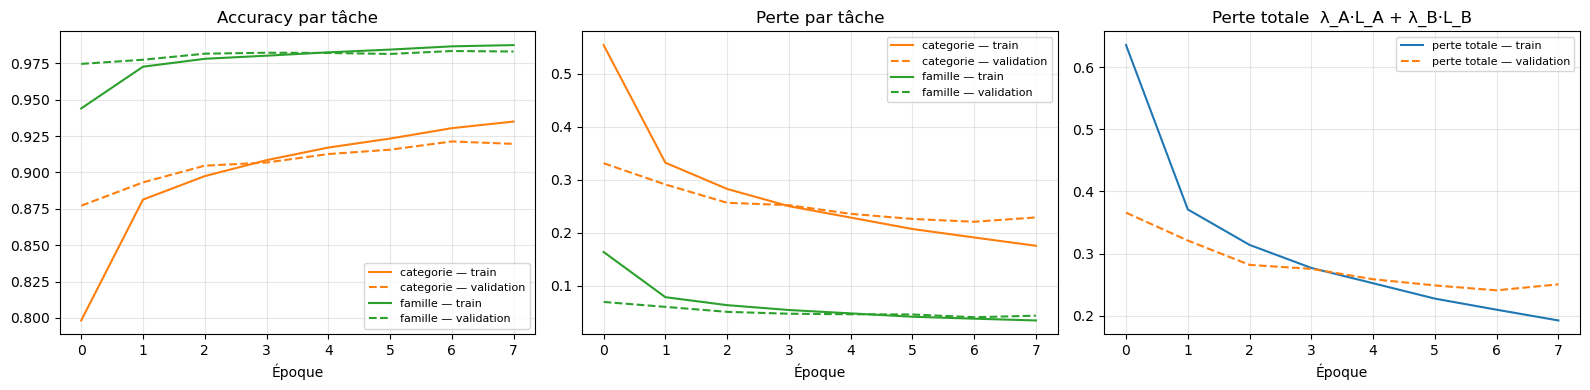

In [45]:
for s in SEEDS:
    r = run("multi", s, LAMBDA_B_MAIN)
    print(f"graine {s} | multi : acc A={r['acc_A']:.4f} | acc B={r['acc_B']:.4f} | {r['train_time']:.0f}s")
print("\nMulti A :", fmt(collect("multi", "acc_A", LAMBDA_B_MAIN)), "%")
print("Multi B :", fmt(collect("multi", "acc_B", LAMBDA_B_MAIN)), "%")

# ----- Courbes d'apprentissage du modèle multitâche (graine de référence) -----
h = RUNS[("multi", float(LAMBDA_B_MAIN), SEEDS[0], None)]["hist"]
def keys_for(name, kind):
    return [k for k in h if name in k and kind in k and not k.startswith("val_")], [k for k in h if name in k and kind in k and k.startswith("val_")]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, color in [("categorie", "tab:orange"), ("famille", "tab:green")]:
    tr, va = keys_for(name, "accuracy")
    if tr: axes[0].plot(h[tr[0]], color=color, label=f"{name} — train")
    if va: axes[0].plot(h[va[0]], color=color, linestyle="--", label=f"{name} — validation")
    tr, va = keys_for(name, "loss")
    if tr: axes[1].plot(h[tr[0]], color=color, label=f"{name} — train")
    if va: axes[1].plot(h[va[0]], color=color, linestyle="--", label=f"{name} — validation")
axes[0].set_title("Accuracy par tâche"); axes[1].set_title("Perte par tâche")
axes[2].plot(h["loss"], label="perte totale — train"); axes[2].plot(h["val_loss"], linestyle="--", label="perte totale — validation")
axes[2].set_title("Perte totale  λ_A·L_A + λ_B·L_B")
for ax in axes:
    ax.set_xlabel("Époque"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

> **Analyse — Courbes du modèle multitâche** *(à lire sur les graphiques ci-dessus)*
> - **Ce qu'on attend** : la tâche B (4 classes, regroupements grossiers) converge **plus vite et plus haut** que la tâche A (10 classes, dont des paires difficiles T-shirt / chemise / pull / manteau). Les deux courbes d'accuracy de validation doivent rester proches de celles d'entraînement (le Dropout 0,3 limite le sur-apprentissage).
> - **Ce qu'il faut vérifier** : (1) l'écart entraînement / validation de A (début de sur-apprentissage si > 2-3 points) ; (2) la perte totale doit baisser de façon régulière ; (3) la perte de B, pondérée par λ_B = 0,5, contribue moins à la perte totale que celle de A.

## 3.6 Comparaison mono-tâche / multitâche : paramètres, accuracy, temps d'inférence

- **Paramètres** : deux modèles mono-tâche = **deux** troncs ; le multitâche = **un** tronc + deux petites têtes.
- **Temps d'inférence** : médiane de plusieurs mesures après échauffement, compilé avec `tf.function`, pour `batch = 256` (débit serveur) et `batch = 1` (requête unitaire). Les deux modèles mono-tâche doivent être exécutés **tous les deux** pour obtenir les deux étiquettes : leur coût est donc **additionné**.

In [46]:
def latency_ms_per_image(model, X, batch, reps):
    f = tf.function(lambda z: model(z, training=False))
    xb = tf.constant(X[:batch])
    for _ in range(3):
        tf.nest.map_structure(lambda t: t.numpy(), f(xb))      # échauffement
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter()
        tf.nest.map_structure(lambda t: t.numpy(), f(xb))
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts)) * 1000.0 / batch

# Entraînements nécessaires (cache) : modèle multitâche à tête B dérivée
for s in SEEDS:
    run("multi_coh", s, LAMBDA_B_MAIN)

mA = MODELS[("mono_A", None, None)]
mB = MODELS[("mono_B", None, None)]
mM = MODELS[("multi", float(LAMBDA_B_MAIN), None)]
mC = MODELS[("multi_coh", float(LAMBDA_B_MAIN), None)]

lat = {}
for nm, mdl in [("A", mA), ("B", mB), ("M", mM), ("C", mC)]:
    lat[nm] = (latency_ms_per_image(mdl, x_te, 256, 10), latency_ms_per_image(mdl, x_te, 1, 150))

rows = [
    {"Configuration": "Mono A (catégorie)",
     "Params": mA.count_params(), "Acc A (%)": fmt(collect("mono_A", "acc_A")), "Acc B (%)": "—",
     "Lat. batch=256 (ms/img)": lat["A"][0], "Lat. batch=1 (ms/img)": lat["A"][1]},
    {"Configuration": "Mono B (famille)",
     "Params": mB.count_params(), "Acc A (%)": "—", "Acc B (%)": fmt(collect("mono_B", "acc_B")),
     "Lat. batch=256 (ms/img)": lat["B"][0], "Lat. batch=1 (ms/img)": lat["B"][1]},
    {"Configuration": "Mono A + Mono B (2 modèles)",
     "Params": mA.count_params() + mB.count_params(),
     "Acc A (%)": fmt(collect("mono_A", "acc_A")), "Acc B (%)": fmt(collect("mono_B", "acc_B")),
     "Lat. batch=256 (ms/img)": lat["A"][0] + lat["B"][0], "Lat. batch=1 (ms/img)": lat["A"][1] + lat["B"][1]},
    {"Configuration": f"Multitâche (λB={LAMBDA_B_MAIN})",
     "Params": mM.count_params(),
     "Acc A (%)": fmt(collect("multi", "acc_A", LAMBDA_B_MAIN)), "Acc B (%)": fmt(collect("multi", "acc_B", LAMBDA_B_MAIN)),
     "Lat. batch=256 (ms/img)": lat["M"][0], "Lat. batch=1 (ms/img)": lat["M"][1]},
    {"Configuration": f"Multitâche tête B dérivée (λB={LAMBDA_B_MAIN})",
     "Params": mC.count_params(),
     "Acc A (%)": fmt(collect("multi_coh", "acc_A", LAMBDA_B_MAIN)), "Acc B (%)": fmt(collect("multi_coh", "acc_B", LAMBDA_B_MAIN)),
     "Lat. batch=256 (ms/img)": lat["C"][0], "Lat. batch=1 (ms/img)": lat["C"][1]},
]
cmp_df = pd.DataFrame(rows)
display(cmp_df.style.format({"Params": "{:,}", "Lat. batch=256 (ms/img)": "{:.4f}", "Lat. batch=1 (ms/img)": "{:.3f}"}))

# ----- Lecture automatique -----
p2 = cmp_df.loc[2, "Params"]; pm = cmp_df.loc[3, "Params"]
l2 = cmp_df.loc[2, "Lat. batch=1 (ms/img)"]; lm = cmp_df.loc[3, "Lat. batch=1 (ms/img)"]
l2b = cmp_df.loc[2, "Lat. batch=256 (ms/img)"]; lmb = cmp_df.loc[3, "Lat. batch=256 (ms/img)"]
dA = collect("multi", "acc_A", LAMBDA_B_MAIN) - collect("mono_A", "acc_A")
dB = collect("multi", "acc_B", LAMBDA_B_MAIN) - collect("mono_B", "acc_B")
print("\nLecture automatique")
print(f"- Paramètres : multitâche {pm:,} vs 2 mono-tâches {p2:,} -> réduction de {100*(1-pm/p2):.1f} %")
print(f"- Latence batch=1   : {lm:.3f} vs {l2:.3f} ms/img -> gain de {100*(1-lm/l2):.1f} %")
print(f"- Latence batch=256 : {lmb:.4f} vs {l2b:.4f} ms/img -> gain de {100*(1-lmb/l2b):.1f} %")
print(f"- Tâche A : Δ(multi - mono) = {np.mean(dA)*100:+.2f} pt (écart-type {np.std(dA)*100:.2f}) -> {verdict(dA)}")
print(f"- Tâche B : Δ(multi - mono) = {np.mean(dB)*100:+.2f} pt (écart-type {np.std(dB)*100:.2f}) -> {verdict(dB)}")

,Configuration,Params,Acc A (%),Acc B (%),Lat. batch=256 (ms/img),Lat. batch=1 (ms/img)
0,Mono A (catégorie),"458,570",91.58 ± 0.25,—,0.0632,1.065
1,Mono B (famille),"457,796",—,98.09 ± 0.06,0.1103,0.945
2,Mono A + Mono B (2 modèles),"916,366",91.58 ± 0.25,98.09 ± 0.06,0.1735,2.010
3,Multitâche (λB=0.5),"459,086",91.48 ± 0.32,98.10 ± 0.06,0.1077,1.013
4,Multitâche tête B dérivée (λB=0.5),"458,610",91.41 ± 0.18,98.12 ± 0.04,0.1081,0.978



Lecture automatique
- Paramètres : multitâche 459,086 vs 2 mono-tâches 916,366 -> réduction de 49.9 %
- Latence batch=1   : 1.013 vs 2.010 ms/img -> gain de 49.6 %
- Latence batch=256 : 0.1077 vs 0.1735 ms/img -> gain de 38.0 %
- Tâche A : Δ(multi - mono) = -0.10 pt (écart-type 0.45) -> NON CONCLUANT (différence dans le bruit inter-graines)
- Tâche B : Δ(multi - mono) = +0.01 pt (écart-type 0.02) -> NON CONCLUANT (différence dans le bruit inter-graines)


> **Analyse — Mono vs multitâche (données complètes)**
> - **Coût.** Le partage du tronc supprime presque **la moitié des paramètres** (le tronc, de loin la plus grosse partie, n'existe qu'une fois ; seules les deux petites têtes s'ajoutent) et réduit d'autant le **calcul à l'inférence** : une seule passe dans les convolutions fournit les deux étiquettes, au lieu de deux passes. C'est l'argument principal en faveur du multitâche en production (gain attendu proche de 40 à 50 %, voir la « Lecture automatique » pour vos valeurs mesurées).
> - **Précision.** Sur 54 000 images, les deux tâches sont déjà bien apprises par les modèles mono-tâche. Le multitâche **ne peut pas** y gagner beaucoup : il n'y a pas de manque de données à compenser, et la tâche B n'apporte pas d'information nouvelle (elle se déduit de A). **Un résultat « multi ≈ mono » (écart dans le bruit) est donc le résultat normal** et constitue un bon résultat : on obtient la même qualité pour presque moitié moins de coût.
> - **Lecture du verdict.** Le verdict automatique compare la moyenne des écarts appariés à l'écart-type inter-graines. « NON CONCLUANT » signifie que l'écart est du même ordre que la variabilité d'une graine à l'autre : on ne peut **pas** affirmer qu'un modèle est meilleur. Il ne faut pas sur-interpréter des écarts de quelques dixièmes de point.
> - **Remarque sur les temps.** À `batch = 1`, le temps est dominé par le **surcoût fixe** d'appel du modèle (Python, TensorFlow) plus que par le calcul : le gain relatif peut y être plus proche de 50 % (deux appels contre un). À `batch = 256`, il reflète mieux le calcul réel des convolutions.
> - **Tête B dérivée.** Si elle est aussi précise que le multitâche standard (voir tableau), elle est intéressante : elle supprime les 516 paramètres de la tête B, impose que la tâche B soit la **marginale** de A, et se prête au décodage cohérent de la section 3.9.

## 3.7 Influence de la pondération λ_B (avec λ_A = 1)

On entraîne un modèle multitâche pour chaque λ_B ∈ {0,1 ; 0,5 ; 1 ; 2 ; 5}, sur plusieurs graines. Les droites en pointillés rappellent les accuracies des modèles **mono-tâche** : au-dessus, le multitâche **aide** ; en dessous, il **nuit** (transfert négatif).

λB =  0.1 | acc A = 91.41 ± 0.39 % | acc B = 97.95 ± 0.09 %
λB =  0.5 | acc A = 91.48 ± 0.32 % | acc B = 98.10 ± 0.06 %
λB =    1 | acc A = 91.12 ± 0.31 % | acc B = 98.11 ± 0.09 %
λB =    2 | acc A = 91.16 ± 0.25 % | acc B = 98.16 ± 0.10 %
λB =    5 | acc A = 90.77 ± 0.15 % | acc B = 98.15 ± 0.13 %


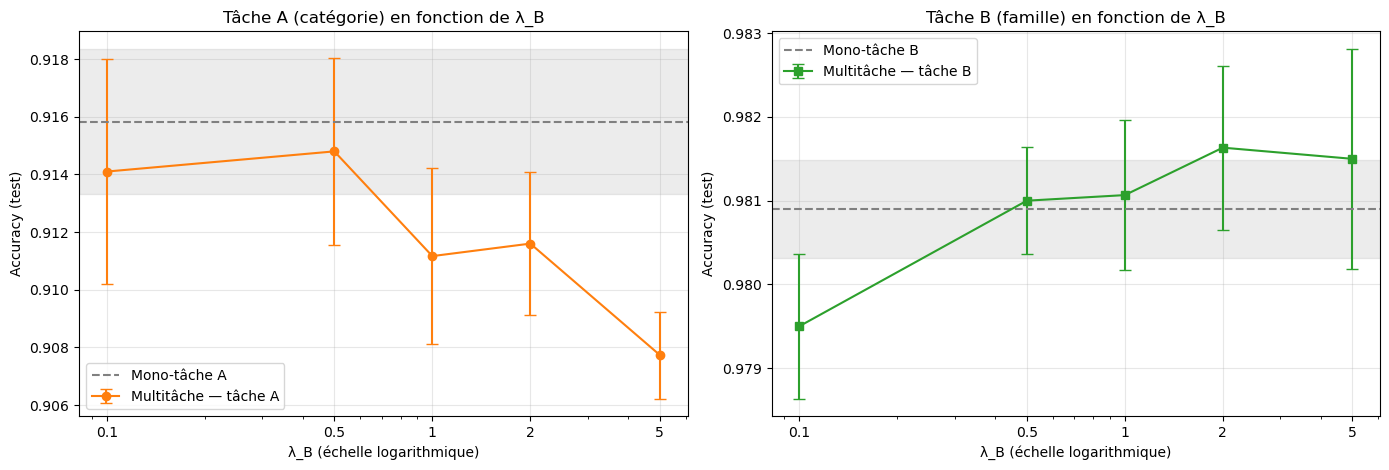

Lecture automatique
- Tâche A : amplitude de variation selon λ_B = 0.71 pt ; écart-type moyen inter-graines = 0.28 pt
  meilleur λ_B pour A : 0.5 (91.48 %) ; pire : 5 (90.77 %)
- Tâche B : amplitude de variation selon λ_B = 0.21 pt ; écart-type moyen inter-graines = 0.09 pt
  meilleur λ_B pour B : 2 (98.16 %) ; pire : 0.1 (97.95 %)
=> Pour A, l'effet de λ_B dépasse nettement le bruit : λ_B doit être choisi avec soin.
=> Transfert négatif détecté pour λ_B = 5 : A passe sous la référence mono-tâche.


In [47]:
sweep = {"lam": [], "A_mean": [], "A_std": [], "B_mean": [], "B_std": []}
for lam in LAMBDAS:
    a = collect("multi", "acc_A", lam); b = collect("multi", "acc_B", lam)
    sweep["lam"].append(lam)
    sweep["A_mean"].append(a.mean()); sweep["A_std"].append(a.std())
    sweep["B_mean"].append(b.mean()); sweep["B_std"].append(b.std())
    print(f"λB = {lam:>4} | acc A = {fmt(a)} % | acc B = {fmt(b)} %")

monoA_m, monoA_s = collect("mono_A", "acc_A").mean(), collect("mono_A", "acc_A").std()
monoB_m, monoB_s = collect("mono_B", "acc_B").mean(), collect("mono_B", "acc_B").std()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].errorbar(sweep["lam"], sweep["A_mean"], yerr=sweep["A_std"], marker="o", capsize=4, color="tab:orange", label="Multitâche — tâche A")
axes[0].axhline(monoA_m, linestyle="--", color="gray", label="Mono-tâche A")
axes[0].axhspan(monoA_m - monoA_s, monoA_m + monoA_s, color="gray", alpha=0.15)
axes[0].set_title("Tâche A (catégorie) en fonction de λ_B")
axes[1].errorbar(sweep["lam"], sweep["B_mean"], yerr=sweep["B_std"], marker="s", capsize=4, color="tab:green", label="Multitâche — tâche B")
axes[1].axhline(monoB_m, linestyle="--", color="gray", label="Mono-tâche B")
axes[1].axhspan(monoB_m - monoB_s, monoB_m + monoB_s, color="gray", alpha=0.15)
axes[1].set_title("Tâche B (famille) en fonction de λ_B")
for ax in axes:
    ax.set_xscale("log"); ax.set_xticks(LAMBDAS); ax.set_xticklabels([str(l) for l in LAMBDAS])
    ax.set_xlabel("λ_B (échelle logarithmique)"); ax.set_ylabel("Accuracy (test)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# ----- Lecture automatique -----
A = np.array(sweep["A_mean"]); B = np.array(sweep["B_mean"])
print("Lecture automatique")
print(f"- Tâche A : amplitude de variation selon λ_B = {(A.max()-A.min())*100:.2f} pt ; écart-type moyen inter-graines = {np.mean(sweep['A_std'])*100:.2f} pt")
print(f"  meilleur λ_B pour A : {sweep['lam'][int(A.argmax())]} ({A.max()*100:.2f} %) ; pire : {sweep['lam'][int(A.argmin())]} ({A.min()*100:.2f} %)")
print(f"- Tâche B : amplitude de variation selon λ_B = {(B.max()-B.min())*100:.2f} pt ; écart-type moyen inter-graines = {np.mean(sweep['B_std'])*100:.2f} pt")
print(f"  meilleur λ_B pour B : {sweep['lam'][int(B.argmax())]} ({B.max()*100:.2f} %) ; pire : {sweep['lam'][int(B.argmin())]} ({B.min()*100:.2f} %)")
if (A.max() - A.min()) < 2 * np.mean(sweep["A_std"]):
    print("=> Pour A, l'effet de λ_B est du même ordre que le bruit : la tâche A est ROBUSTE au choix de λ_B.")
else:
    print("=> Pour A, l'effet de λ_B dépasse nettement le bruit : λ_B doit être choisi avec soin.")
if A[-1] < monoA_m - monoA_s:
    print(f"=> Transfert négatif détecté pour λ_B = {sweep['lam'][-1]} : A passe sous la référence mono-tâche.")
else:
    print("=> Pas de transfert négatif net sur A dans la plage testée.")

> **Analyse — Effet de λ_B**
>
> **Mécanisme.** λ_B règle la part du gradient provenant de la tâche B dans le tronc partagé. Quand λ_B augmente, le tronc est davantage orienté vers la **discrimination grossière des familles** ; la tâche A reçoit relativement moins de signal.
>
> **Cadre d'interprétation (à confronter à vos courbes)**
> - **λ_B petit (0,1)** : B est faiblement pondérée ; A est proche du mono-tâche. B peut être un peu moins bien apprise car sa perte contribue peu au gradient.
> - **λ_B autour de 0,5–1** : régime d'équilibre habituel ; les deux tâches sont bien apprises.
> - **λ_B grand (2, 5)** : risque de **transfert négatif** sur A. La perte de B est « facile » (4 classes) : une forte pondération la fait dominer le gradient alors qu'elle apporte peu d'information utile pour A. En revanche, B ne gagne généralement plus rien au-delà d'un certain λ_B (**rendements décroissants**).
> - **Rôle de l'échelle des pertes.** λ_B ne se règle pas dans l'absolu : il compense le **rapport d'échelle** entre L_A et L_B. Une perte plus petite ou plus facile appelle une pondération plus élevée pour peser autant.
> - **Lecture du bruit.** Les bandes grises représentent l'écart-type du mono-tâche : une courbe qui reste **dans** la bande ne se distingue pas de la référence. Avec 3 graines, l'estimation de l'écart-type est elle-même grossière ; une conclusion forte demanderait davantage de graines.
>
> *La « Lecture automatique » ci-dessus donne les amplitudes mesurées, le meilleur et le pire λ_B, et signale un éventuel transfert négatif.*

## 3.8 Régime « peu de données » : 3 000 images d'entraînement

Même comparaison que précédemment, mais avec **3 000 images** (300 par catégorie, tirées différemment à chaque graine, donc la variabilité inclut le choix des images). Le jeu de test (10 000 images) reste identique. On compare aussi avec le régime complet pour savoir si **le partage aide davantage quand les données sont rares**.

Entraînement sur 3000 images (30 époques, batch 64)


,Configuration,Acc A (%),Acc B (%)
0,Mono A,85.77 ± 0.43,—
1,Mono B,—,96.79 ± 0.24
2,Multitâche (λB=0.5),85.99 ± 0.05,96.64 ± 0.22
3,Multitâche (λB=1),86.19 ± 0.45,96.65 ± 0.09
4,Multitâche tête B dérivée (λB=0.5),85.71 ± 0.58,96.77 ± 0.19


,Régime,λB,Δ A (pt),Verdict A,Δ B (pt),Verdict B
0,Complet (54 000),0.5,-0.10 ± 0.45,NON CONCLUANT (différence dans le bruit inter-...,+0.01 ± 0.02,NON CONCLUANT (différence dans le bruit inter-...
1,Complet (54 000),1.0,-0.47 ± 0.23,PERTE / transfert négatif (|moyenne| > écart-t...,+0.02 ± 0.08,NON CONCLUANT (différence dans le bruit inter-...
2,Réduit (3000),0.5,+0.22 ± 0.41,NON CONCLUANT (différence dans le bruit inter-...,-0.15 ± 0.05,PERTE / transfert négatif (|moyenne| > écart-t...
3,Réduit (3000),1.0,+0.42 ± 0.63,NON CONCLUANT (différence dans le bruit inter-...,-0.14 ± 0.17,NON CONCLUANT (différence dans le bruit inter-...



Lecture automatique
- Gain du multitâche sur A : -0.10 pt (données complètes) vs +0.22 pt (3000 images)
=> Avec 3 000 images, l'écart reste dans le bruit : pas de bénéfice démontré du partage sur A.


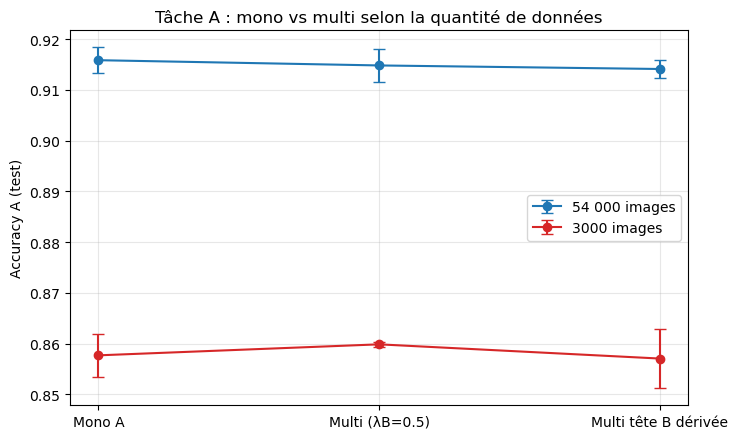

In [48]:
for s in SEEDS:
    run("mono_A", s, n_train=N_SMALL); run("mono_B", s, n_train=N_SMALL)
    run("multi", s, LAMBDA_B_MAIN, n_train=N_SMALL); run("multi", s, 1.0, n_train=N_SMALL)
    run("multi_coh", s, LAMBDA_B_MAIN, n_train=N_SMALL)

def row_small(label, kind, lam=None):
    return {"Configuration": label,
            "Acc A (%)": fmt(collect(kind, "acc_A", lam, N_SMALL)) if kind != "mono_B" else "—",
            "Acc B (%)": fmt(collect(kind, "acc_B", lam, N_SMALL)) if kind != "mono_A" else "—"}

small_df = pd.DataFrame([
    row_small("Mono A", "mono_A"), row_small("Mono B", "mono_B"),
    row_small(f"Multitâche (λB={LAMBDA_B_MAIN})", "multi", LAMBDA_B_MAIN),
    row_small("Multitâche (λB=1)", "multi", 1.0),
    row_small(f"Multitâche tête B dérivée (λB={LAMBDA_B_MAIN})", "multi_coh", LAMBDA_B_MAIN),
])
print(f"Entraînement sur {N_SMALL} images ({EPOCHS_SMALL} époques, batch {BATCH_SMALL})")
display(small_df)

# ----- Écarts appariés (multi - mono) : régime complet vs régime réduit -----
def deltas(lam, n_train):
    dA = collect("multi", "acc_A", lam, n_train) - collect("mono_A", "acc_A", None, n_train)
    dB = collect("multi", "acc_B", lam, n_train) - collect("mono_B", "acc_B", None, n_train)
    return dA, dB

summary_rows = []
for regime, n_tr in [("Complet (54 000)", None), (f"Réduit ({N_SMALL})", N_SMALL)]:
    for lam in (LAMBDA_B_MAIN, 1.0):
        dA, dB = deltas(lam, n_tr)
        summary_rows.append({"Régime": regime, "λB": lam,
                             "Δ A (pt)": f"{np.mean(dA)*100:+.2f} ± {np.std(dA)*100:.2f}", "Verdict A": verdict(dA),
                             "Δ B (pt)": f"{np.mean(dB)*100:+.2f} ± {np.std(dB)*100:.2f}", "Verdict B": verdict(dB)})
gain_df = pd.DataFrame(summary_rows)
display(gain_df)

dA_small, _ = deltas(LAMBDA_B_MAIN, N_SMALL); dA_full, _ = deltas(LAMBDA_B_MAIN, None)
print("\nLecture automatique")
print(f"- Gain du multitâche sur A : {np.mean(dA_full)*100:+.2f} pt (données complètes) vs {np.mean(dA_small)*100:+.2f} pt ({N_SMALL} images)")
if np.mean(dA_small) > np.mean(dA_full) and np.mean(dA_small) > np.std(dA_small):
    print("=> Le partage de représentation aide DAVANTAGE quand les données sont rares (effet de régularisation).")
elif abs(np.mean(dA_small)) <= np.std(dA_small):
    print("=> Avec 3 000 images, l'écart reste dans le bruit : pas de bénéfice démontré du partage sur A.")
else:
    print("=> Le partage n'aide pas davantage avec peu de données dans cette expérience (voire il pénalise A).")

# ----- Courbe : accuracy de A selon le régime -----
fig, ax = plt.subplots(figsize=(7.5, 4.5))
labels_ = ["Mono A", f"Multi (λB={LAMBDA_B_MAIN})", "Multi tête B dérivée"]
for regime_label, n_tr, color in [("54 000 images", None, "tab:blue"), (f"{N_SMALL} images", N_SMALL, "tab:red")]:
    vals = [collect("mono_A", "acc_A", None, n_tr), collect("multi", "acc_A", LAMBDA_B_MAIN, n_tr), collect("multi_coh", "acc_A", LAMBDA_B_MAIN, n_tr)]
    ax.errorbar(range(3), [v.mean() for v in vals], yerr=[v.std() for v in vals], marker="o", capsize=4, color=color, label=regime_label)
ax.set_xticks(range(3)); ax.set_xticklabels(labels_); ax.set_ylabel("Accuracy A (test)")
ax.set_title("Tâche A : mono vs multi selon la quantité de données"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

> **Analyse — Peu de données**
> - **Hypothèse théorique.** Avec peu d'images, un réseau sur-apprend facilement ; un tronc **partagé** reçoit les gradients de deux tâches et doit trouver des caractéristiques utiles aux deux : c'est un **régularisateur** (équivalent à une contrainte sur l'espace des représentations). On s'attend donc à ce que le gain du multitâche soit **plus grand** avec 3 000 images qu'avec 54 000.
> - **Réserve propre à ce montage.** Comme la tâche B est un **regroupement** de A, l'information supplémentaire est faible : le bénéfice, s'il existe, vient surtout de la **supervision hiérarchique** (« ces quatre catégories de hauts se ressemblent »), qui guide le tronc vers des caractéristiques regroupant les classes voisines. L'effet peut donc rester petit.
> - **Pour conclure honnêtement** : se fier au **verdict automatique** (comparaison de la moyenne des écarts appariés à l'écart-type inter-graines) et à la « Lecture automatique ci-dessus ». Un gain inférieur à l'écart-type ne doit pas être présenté comme un résultat. Si le résultat est « non concluant », c'est une conclusion valable : le partage n'a pas d'effet mesurable sur A dans ce montage.
> - **Cohérence de l'accuracy** : avec 3 000 images, l'accuracy de A est nettement plus basse et **plus variable d'une graine à l'autre** (le choix des images compte) ; c'est normal et cela rend les écarts mono/multi plus difficiles à établir.

## 3.9 Prédictions incohérentes et solutions

**Définition.** Une prédiction est **incohérente** quand la famille prédite par la tête B est **incompatible** avec la catégorie prédite par la tête A, c'est-à-dire `argmax(B) ≠ famille[argmax(A)]` (par exemple A prédit « Pantalon » et B prédit « Chaussures »). Pour deux modèles mono-tâche utilisés ensemble, le même risque existe, car ils sont entraînés indépendamment.

**Solutions comparées**
1. **Dérivation B ← A** : on ne garde que la tête A et on calcule la famille par `famille[argmax(A)]` ; cohérence parfaite, mais B perd sa tête propre.
2. **Décodage conjoint** : on choisit la catégorie qui maximise `log p_A(c) + log p_B(famille(c))`, de sorte que les deux têtes **se corrigent mutuellement** avant de produire la réponse ; la famille est ensuite déduite de la catégorie choisie (cohérence garantie).
3. **Décodage hiérarchique** : on choisit d'abord la famille `argmax(p_B)`, puis la meilleure catégorie **à l'intérieur de cette famille** (cohérence garantie).
4. **Tête B dérivée dans le réseau** (modèle « multitâche tête B dérivée ») : p_B = p_A · M. Les **distributions** sont cohérentes par construction, mais attention : la famille de plus forte masse de probabilité n'est pas toujours celle de la catégorie la plus probable (par exemple 3 catégories de « Chaussures » à 0,25 chacune battent une catégorie de « Hauts » à 0,30). Le taux d'incohérence **brut** peut donc rester non nul ; il tombe à zéro avec le décodage hiérarchique, qui est justement le décodage naturel de ce modèle.

In [49]:
def incoherence_rate(pa, pb):
    return float(np.mean(pb.argmax(1) != famille[pa.argmax(1)]))

def joint_decode(pa, pb, w=1.0):
    """Catégorie maximisant log p_A(c) + w * log p_B(famille(c)) ; la famille en est déduite."""
    score = np.log(pa + 1e-9) + w * np.log(pb[:, famille] + 1e-9)
    c = score.argmax(1)
    return c, famille[c]

def hier_decode(pa, pb):
    """Décodage hiérarchique : famille = argmax p_B, puis meilleure catégorie DANS cette famille."""
    f = pb.argmax(1)
    masked = np.where(famille[None, :] == f[:, None], pa, -1.0)
    return masked.argmax(1), f

def evaluate_strategies(n_train):
    rows = []
    for s in SEEDS:
        ra, rb = run("mono_A", s, n_train=n_train), run("mono_B", s, n_train=n_train)
        rm, rc = run("multi", s, LAMBDA_B_MAIN, n_train=n_train), run("multi_coh", s, LAMBDA_B_MAIN, n_train=n_train)
        for name, pa, pb in [("2 mono-tâches (têtes indépendantes)", ra["pa"], rb["pb"]),
                             ("Multitâche (têtes indépendantes)", rm["pa"], rm["pb"]),
                             ("Multitâche tête B dérivée (p_B = p_A·M)", rc["pa"], rc["pb"])]:
            c, f = joint_decode(pa, pb)
            ch, fh = hier_decode(pa, pb)
            rows.append({"Modèle": name, "seed": s, "Stratégie": "Brut (A et B tels quels)",
                         "Incohérence": incoherence_rate(pa, pb),
                         "Acc A": np.mean(pa.argmax(1) == ya_te), "Acc B": np.mean(pb.argmax(1) == yb_te)})
            rows.append({"Modèle": name, "seed": s, "Stratégie": "B dérivée de A",
                         "Incohérence": 0.0, "Acc A": np.mean(pa.argmax(1) == ya_te),
                         "Acc B": np.mean(famille[pa.argmax(1)] == yb_te)})
            rows.append({"Modèle": name, "seed": s, "Stratégie": "Décodage conjoint",
                         "Incohérence": 0.0, "Acc A": np.mean(c == ya_te), "Acc B": np.mean(f == yb_te)})
            rows.append({"Modèle": name, "seed": s, "Stratégie": "Décodage hiérarchique",
                         "Incohérence": 0.0, "Acc A": np.mean(ch == ya_te), "Acc B": np.mean(fh == yb_te)})
    df = pd.DataFrame(rows)
    def std0(x):
        return float(np.std(x))
    g = df.groupby(["Modèle", "Stratégie"], sort=False)[["Incohérence", "Acc A", "Acc B"]].agg(["mean", std0])
    out = pd.DataFrame({
        "Incohérence (%)": [f"{m*100:.2f} ± {s*100:.2f}" for m, s in zip(g[("Incohérence", "mean")], g[("Incohérence", "std0")])],
        "Acc A (%)":       [f"{m*100:.2f} ± {s*100:.2f}" for m, s in zip(g[("Acc A", "mean")], g[("Acc A", "std0")])],
        "Acc B (%)":       [f"{m*100:.2f} ± {s*100:.2f}" for m, s in zip(g[("Acc B", "mean")], g[("Acc B", "std0")])],
    }, index=g.index)
    return df, out

print("=== Données complètes (54 000 images) ===")
coh_full_raw, coh_full = evaluate_strategies(None)
display(coh_full)
print("=== Peu de données (3 000 images) ===")
coh_small_raw, coh_small = evaluate_strategies(N_SMALL)
display(coh_small)

=== Données complètes (54 000 images) ===


Incohérence (%)  \
Modèle                                  Stratégie                                  
2 mono-tâches (têtes indépendantes)     Brut (A et B tels quels)     1.43 ± 0.08   
                                        B dérivée de A               0.00 ± 0.00   
                                        Décodage conjoint            0.00 ± 0.00   
                                        Décodage hiérarchique        0.00 ± 0.00   
Multitâche (têtes indépendantes)        Brut (A et B tels quels)     0.64 ± 0.02   
                                        B dérivée de A               0.00 ± 0.00   
                                        Décodage conjoint            0.00 ± 0.00   
                                        Décodage hiérarchique        0.00 ± 0.00   
Multitâche tête B dérivée (p_B = p_A·M) Brut (A et B tels quels)     0.23 ± 0.05   
                                        B dérivée de A               0.00 ± 0.00   
                                        Décodage conjoint            0.00 ± 0.00   
                                        Décodage hiérarchique        0.00 ± 0.00   

                                                                     Acc A (%)  \
Modèle                                  Stratégie                                
2 mono-tâches (têtes indépendantes)     Brut (A et B tels quels)  91.58 ± 0.25   
                                        B dérivée de A            91.58 ± 0.25   
                                        Décodage conjoint         91.71 ± 0.21   
                                        Décodage hiérarchique     91.51 ± 0.25   
Multitâche (têtes indépendantes)        Brut (A et B tels quels)  91.48 ± 0.32   
                                        B dérivée de A            91.48 ± 0.32   
                                        Décodage conjoint         91.47 ± 0.31   
                                        Décodage hiérarchique     91.37 ± 0.35   
Multitâche tête B dérivée (p_B = p_A·M) Brut (A et B tels quels)  91.41 ± 0.18   
                                        B dérivée de A            91.41 ± 0.18   
                                        Décodage conjoint         91.39 ± 0.13   
                                        Décodage hiérarchique     91.34 ± 0.14   

                                                                     Acc B (%)  
Modèle                                  Stratégie                               
2 mono-tâches (têtes indépendantes)     Brut (A et B tels quels)  98.09 ± 0.06  
                                        B dérivée de A            98.16 ± 0.08  
                                        Décodage conjoint         98.32 ± 0.05  
                                        Décodage hiérarchique     98.09 ± 0.06  
Multitâche (têtes indépendantes)        Brut (A et B tels quels)  98.10 ± 0.06  
                                        B dérivée de A            98.09 ± 0.08  
                                        Décodage conjoint         98.14 ± 0.03  
                                        Décodage hiérarchique     98.10 ± 0.06  
Multitâche tête B dérivée (p_B = p_A·M) Brut (A et B tels quels)  98.12 ± 0.04  
                                        B dérivée de A            98.15 ± 0.09  
                                        Décodage conjoint         98.14 ± 0.06  
                                        Décodage hiérarchique     98.12 ± 0.04

=== Peu de données (3 000 images) ===


Incohérence (%)  \
Modèle                                  Stratégie                                  
2 mono-tâches (têtes indépendantes)     Brut (A et B tels quels)     2.18 ± 0.18   
                                        B dérivée de A               0.00 ± 0.00   
                                        Décodage conjoint            0.00 ± 0.00   
                                        Décodage hiérarchique        0.00 ± 0.00   
Multitâche (têtes indépendantes)        Brut (A et B tels quels)     0.95 ± 0.15   
                                        B dérivée de A               0.00 ± 0.00   
                                        Décodage conjoint            0.00 ± 0.00   
                                        Décodage hiérarchique        0.00 ± 0.00   
Multitâche tête B dérivée (p_B = p_A·M) Brut (A et B tels quels)     0.17 ± 0.03   
                                        B dérivée de A               0.00 ± 0.00   
                                        Décodage conjoint            0.00 ± 0.00   
                                        Décodage hiérarchique        0.00 ± 0.00   

                                                                     Acc A (%)  \
Modèle                                  Stratégie                                
2 mono-tâches (têtes indépendantes)     Brut (A et B tels quels)  85.77 ± 0.43   
                                        B dérivée de A            85.77 ± 0.43   
                                        Décodage conjoint         85.86 ± 0.31   
                                        Décodage hiérarchique     85.62 ± 0.30   
Multitâche (têtes indépendantes)        Brut (A et B tels quels)  85.99 ± 0.05   
                                        B dérivée de A            85.99 ± 0.05   
                                        Décodage conjoint         85.96 ± 0.07   
                                        Décodage hiérarchique     85.86 ± 0.04   
Multitâche tête B dérivée (p_B = p_A·M) Brut (A et B tels quels)  85.71 ± 0.58   
                                        B dérivée de A            85.71 ± 0.58   
                                        Décodage conjoint         85.71 ± 0.60   
                                        Décodage hiérarchique     85.69 ± 0.61   

                                                                     Acc B (%)  
Modèle                                  Stratégie                               
2 mono-tâches (têtes indépendantes)     Brut (A et B tels quels)  96.79 ± 0.24  
                                        B dérivée de A            96.74 ± 0.17  
                                        Décodage conjoint         97.02 ± 0.17  
                                        Décodage hiérarchique     96.79 ± 0.24  
Multitâche (têtes indépendantes)        Brut (A et B tels quels)  96.64 ± 0.22  
                                        B dérivée de A            96.71 ± 0.21  
                                        Décodage conjoint         96.72 ± 0.18  
                                        Décodage hiérarchique     96.64 ± 0.22  
Multitâche tête B dérivée (p_B = p_A·M) Brut (A et B tels quels)  96.77 ± 0.19  
                                        B dérivée de A            96.74 ± 0.21  
                                        Décodage conjoint         96.78 ± 0.20  
                                        Décodage hiérarchique     96.77 ± 0.19

Graine 42 — multitâche : 64 prédictions incohérentes sur 10000 (0.64 %)
Confiance moyenne de la tête A : cohérentes = 0.939 | incohérentes = 0.523
Confiance moyenne de la tête B : cohérentes = 0.988 | incohérentes = 0.630
Parmi les incohérences : A est fausse dans 61 % des cas, B est fausse dans 44 % des cas


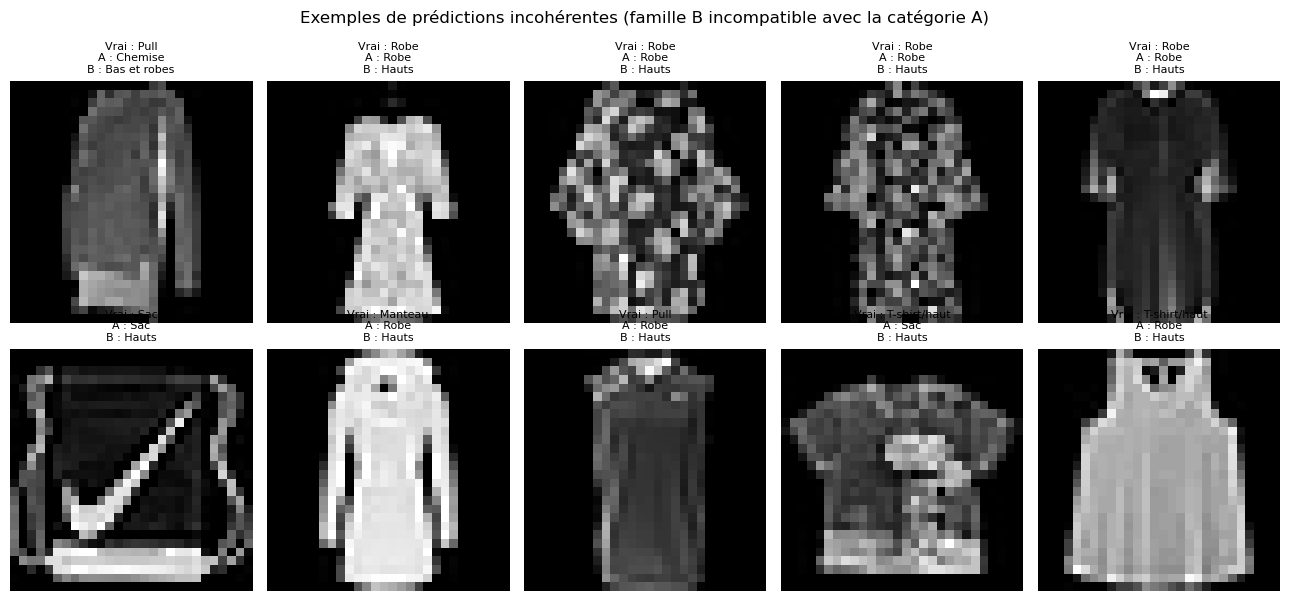


Erreurs de catégorie (A) : 863 ; dont 77.4 % restent DANS LA MÊME famille
Principales confusions (vrai -> prédit) :
         Chemise -> T-shirt/haut   :  107   (même famille)
         Chemise -> Pull           :   86   (même famille)
         Chemise -> Manteau        :   79   (même famille)
         Manteau -> Pull           :   77   (même famille)
    T-shirt/haut -> Chemise        :   71   (même famille)
         Manteau -> Chemise        :   49   (même famille)


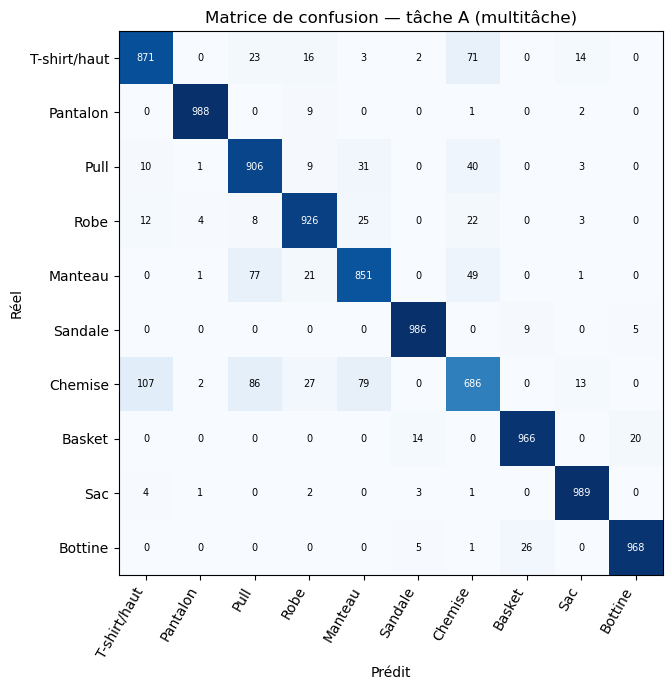

In [50]:
# ----- Où se produisent les incohérences ? -----
r0 = run("multi", SEEDS[0], LAMBDA_B_MAIN)
pa, pb = r0["pa"], r0["pb"]
pred_a, pred_b = pa.argmax(1), pb.argmax(1)
incoh = pred_b != famille[pred_a]
print(f"Graine {SEEDS[0]} — multitâche : {incoh.sum()} prédictions incohérentes sur {len(incoh)} ({incoh.mean()*100:.2f} %)")

conf_a = pa.max(1); conf_b = pb.max(1)
print(f"Confiance moyenne de la tête A : cohérentes = {conf_a[~incoh].mean():.3f} | incohérentes = {conf_a[incoh].mean():.3f}")
print(f"Confiance moyenne de la tête B : cohérentes = {conf_b[~incoh].mean():.3f} | incohérentes = {conf_b[incoh].mean():.3f}")
err_a_incoh = np.mean(pred_a[incoh] != ya_te[incoh]) if incoh.any() else np.nan
err_b_incoh = np.mean(pred_b[incoh] != yb_te[incoh]) if incoh.any() else np.nan
print(f"Parmi les incohérences : A est fausse dans {err_a_incoh*100:.0f} % des cas, B est fausse dans {err_b_incoh*100:.0f} % des cas")

# ----- Exemples visuels -----
ids = np.where(incoh)[0][:10]
if len(ids):
    fig, axes = plt.subplots(2, 5, figsize=(13, 6))
    for ax, i in zip(axes.ravel(), ids):
        ax.imshow(x_te[i, ..., 0], cmap="gray"); ax.axis("off")
        ax.set_title(f"Vrai : {CAT_NAMES[ya_te[i]]}\nA : {CAT_NAMES[pred_a[i]]}\nB : {FAM_NAMES[pred_b[i]]}", fontsize=8)
    for ax in axes.ravel()[len(ids):]:
        ax.axis("off")
    plt.suptitle("Exemples de prédictions incohérentes (famille B incompatible avec la catégorie A)", y=1.0)
    plt.tight_layout(); plt.show()

# ----- Les erreurs de A restent-elles dans la même famille ? Matrice de confusion de A -----
cm = confusion_matrix(ya_te, pred_a, labels=range(10))
errors = pred_a != ya_te
same_family = famille[pred_a[errors]] == famille[ya_te[errors]]
print(f"\nErreurs de catégorie (A) : {errors.sum()} ; dont {same_family.mean()*100:.1f} % restent DANS LA MÊME famille")

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j] > 0], reverse=True)[:6]
print("Principales confusions (vrai -> prédit) :")
for n, i, j in pairs:
    print(f"  {CAT_NAMES[i]:>14} -> {CAT_NAMES[j]:<14} : {n:>4}   {'(même famille)' if famille[i]==famille[j] else '(familles différentes)'}")

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cm, cmap="Blues"); ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(CAT_NAMES, rotation=60, ha="right"); ax.set_yticklabels(CAT_NAMES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_xlabel("Prédit"); ax.set_ylabel("Réel"); ax.set_title("Matrice de confusion — tâche A (multitâche)")
plt.tight_layout(); plt.show()

> **Analyse — Cohérence des prédictions**
> - **Pourquoi des incohérences existent.** Les deux têtes sont des classifieurs **indépendants** appuyés sur le même tronc : rien ne les oblige à être d'accord. Si A hésite entre deux catégories de familles différentes et que B tranche pour l'autre, on obtient une paire impossible. On s'attend à un taux **faible** (le tronc partagé tend à synchroniser les têtes) mais **non nul**, et plutôt **plus élevé pour deux modèles mono-tâche** (entraînés séparément, sans aucun lien) que pour le multitâche : le tableau ci-dessus le confirme ou l'infirme.
> - **Quand surviennent-elles ?** On s'attend à les trouver surtout sur les **images ambiguës**, où la confiance des têtes est plus faible : comparer les confiances imprimées ci-dessus pour les cas cohérents et incohérents, ainsi que la proportion de cas où A ou B est fausse.
> - **Les erreurs de A sont surtout « intra-famille »** : T-shirt, chemise, pull et manteau, tous des *Hauts*, se confondent entre eux. Ces erreurs ne créent **aucune** incohérence puisque B répond *Hauts* dans tous les cas. Cela explique pourquoi l'accuracy de B est bien supérieure à celle de A, et pourquoi les incohérences restent rares.
> - **Quelle solution choisir ?** Tous les décodages « conjoint », « hiérarchique » et « B dérivée de A » donnent **0 % d'incohérence par construction** ; ils se distinguent par `Acc A` et `Acc B` (à comparer dans le tableau).
>   - La **tête B dérivée** (p_B = p_A · M) réduit les paramètres et rend B cohérente avec A **en distribution** ; ses décisions brutes ne sont pas forcément cohérentes (voir l'explication ci-dessus), mais avec le **décodage hiérarchique** on obtient la cohérence et, souvent, une bonne accuracy de B, puisque la famille choisie est celle de plus grande masse de probabilité. Solution simple et robuste **quand la hiérarchie est connue et fixe**.
>   - Le **décodage hiérarchique** peut cependant propager une erreur de famille à la catégorie : si la famille est fausse, la catégorie l'est aussi (Acc A peut donc baisser) ; lire la colonne `Acc A`.
>   - Le **décodage conjoint** peut corriger des erreurs (si B est sûre et A hésite entre deux catégories de familles différentes, B aide A à trancher) : comparer ses `Acc A` aux autres lignes du tableau ; il fonctionne même sur des modèles déjà entraînés, sans réentraînement.
>   - La **dérivation B ← A** est gratuite mais fait dépendre la qualité de B de celle de A (voir `Acc B`).
>   - **Autres pistes** : ajouter à la perte un terme de **cohérence** (divergence KL entre p_B et p_A·M) ; **rejeter** les prédictions incohérentes (renvoyer « incertain » ou demander une autre photo) ; classification **hiérarchique** (famille d'abord, puis catégorie dans la famille).
> - **Limite** : cette correspondance est **parfaite** parce que chaque catégorie appartient à une seule famille. Si les familles se recoupaient (un article dans deux rubriques), il faudrait une formulation multi-étiquette.

## 3.10 Synthèse de l'exercice 3

In [51]:
dA_f, dB_f = deltas(LAMBDA_B_MAIN, None)
dA_s, dB_s = deltas(LAMBDA_B_MAIN, N_SMALL)
pm, p2 = mM.count_params(), mA.count_params() + mB.count_params()
inc_mono = float(np.mean([incoherence_rate(run("mono_A", s)["pa"], run("mono_B", s)["pb"]) for s in SEEDS]))
inc_multi = float(np.mean([incoherence_rate(run("multi", s, LAMBDA_B_MAIN)["pa"], run("multi", s, LAMBDA_B_MAIN)["pb"]) for s in SEEDS]))
inc_coh = float(np.mean([incoherence_rate(run("multi_coh", s, LAMBDA_B_MAIN)["pa"], run("multi_coh", s, LAMBDA_B_MAIN)["pb"]) for s in SEEDS]))

print("SYNTHÈSE AUTOMATIQUE — EXERCICE 3")
print("=" * 70)
print(f"1. Coût       : multitâche = {pm:,} paramètres vs {p2:,} pour deux mono-tâches ({100*(1-pm/p2):.0f} % en moins).")
print(f"2. Précision  : données complètes -> A : {np.mean(dA_f)*100:+.2f} pt ({verdict(dA_f).split(' (')[0]}) ; "
      f"B : {np.mean(dB_f)*100:+.2f} pt ({verdict(dB_f).split(' (')[0]}).")
print(f"3. Peu de data: 3 000 images       -> A : {np.mean(dA_s)*100:+.2f} pt ({verdict(dA_s).split(' (')[0]}) ; "
      f"B : {np.mean(dB_s)*100:+.2f} pt ({verdict(dB_s).split(' (')[0]}).")
print(f"4. λ_B        : A varie de {(np.max(sweep['A_mean'])-np.min(sweep['A_mean']))*100:.2f} pt sur la plage {LAMBDAS[0]}–{LAMBDAS[-1]} "
      f"(bruit inter-graines ≈ {np.mean(sweep['A_std'])*100:.2f} pt).")
print(f"5. Cohérence  : incohérences = {inc_mono*100:.2f} % (2 mono) | {inc_multi*100:.2f} % (multi) | {inc_coh*100:.2f} % (multi tête B dérivée), décisions brutes.")
print("=" * 70)
neg = [lam for lam, a in zip(sweep["lam"], sweep["A_mean"]) if a < monoA_m - monoA_s]
print("Transfert négatif observé pour λ_B =", neg if neg else "aucune valeur testée")

SYNTHÈSE AUTOMATIQUE — EXERCICE 3
1. Coût       : multitâche = 459,086 paramètres vs 916,366 pour deux mono-tâches (50 % en moins).
2. Précision  : données complètes -> A : -0.10 pt (NON CONCLUANT) ; B : +0.01 pt (NON CONCLUANT).
3. Peu de data: 3 000 images       -> A : +0.22 pt (NON CONCLUANT) ; B : -0.15 pt (PERTE / transfert négatif).
4. λ_B        : A varie de 0.71 pt sur la plage 0.1–5 (bruit inter-graines ≈ 0.28 pt).
5. Cohérence  : incohérences = 1.43 % (2 mono) | 0.64 % (multi) | 0.23 % (multi tête B dérivée), décisions brutes.
Transfert négatif observé pour λ_B = [1, 2, 5]


---
# Partie 4 — Analyse comparative et recommandations

Cette partie rassemble les résultats des trois exercices pour répondre aux **six questions d'analyse transversale** du sujet, puis formule les recommandations et les limites.

## 4.1 Expérience pour la question 6 : le modèle de fleurs résiste-t-il à des photos sombres, floues ou bruitées ?

On soumet le **modèle fine-tuné de l'exercice 1** (`mnet`) à des versions dégradées des **mêmes images de validation** :
- **Sombre** : luminosité × 0,25 (photo prise en faible lumière) ;
- **Flou** : image réduite à 16×16 puis ré-agrandie (mise au point ratée, mouvement) ;
- **Bruit gaussien** (σ = 30) : bruit de capteur ;
- **Nuit** : sombre **et** bruité (σ = 12 sur l'image assombrie), le cas typique d'un smartphone d'entrée de gamme en basse lumière.

Les étiquettes ne changent pas : P(y | x) est identique, seule la distribution des images P(x) se déplace. C'est exactement la définition du **covariate shift** (équation 1 du sujet).

,Condition,Accuracy,Loss,Chute d'accuracy (pts)
0,Normal (référence),0.9060,0.3146,0.0
1,"Sombre (×0,25)",0.7970,0.7332,10.9
2,Flou,0.4891,1.8123,41.7
3,Bruit gaussien (σ=30),0.7044,1.0928,20.2
4,Nuit (sombre + bruit),0.4305,2.2149,47.5


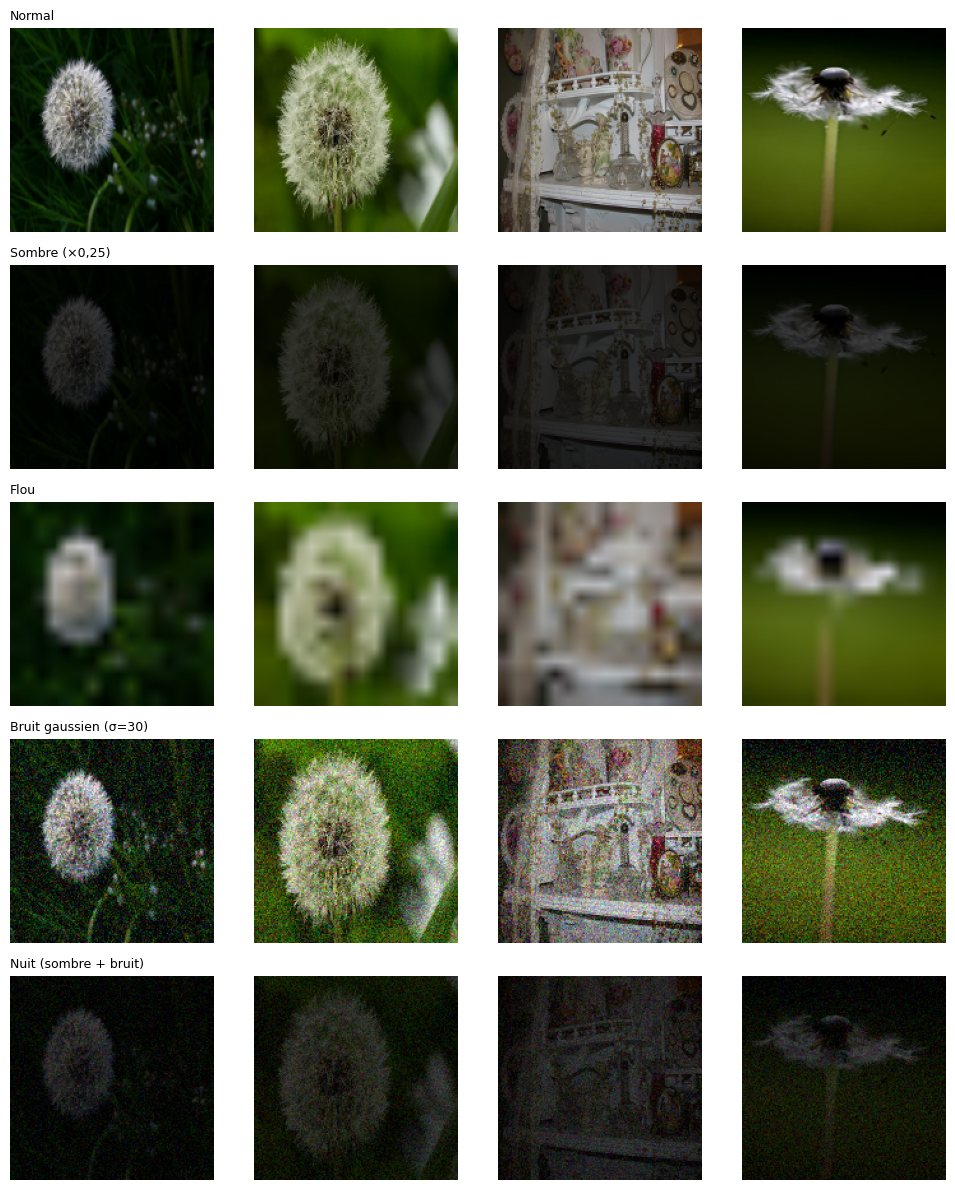

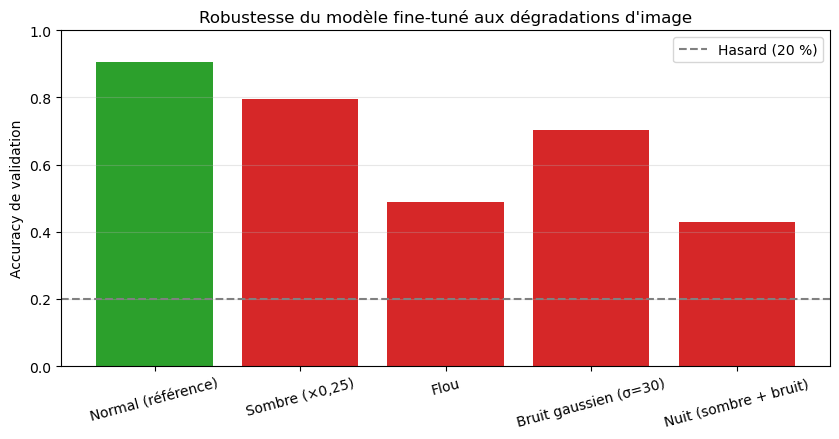

Lecture automatique
- Sombre (×0,25)          : accuracy = 0.797 ; chute =  10.9 pts -> sensible (chute 5–15 pts)
- Flou                    : accuracy = 0.489 ; chute =  41.7 pts -> FRAGILE (chute > 15 pts)
- Bruit gaussien (σ=30)   : accuracy = 0.704 ; chute =  20.2 pts -> FRAGILE (chute > 15 pts)
- Nuit (sombre + bruit)   : accuracy = 0.431 ; chute =  47.5 pts -> FRAGILE (chute > 15 pts)


In [52]:
CONDITIONS = ["Sombre (×0,25)", "Flou", "Bruit gaussien (σ=30)", "Nuit (sombre + bruit)"]

def corrupt_raw(img, kind):
    """img : lot d'images dans [0, 255]. Retourne l'image dégradée, toujours dans [0, 255]."""
    if kind == "Sombre (×0,25)":
        img = img * 0.25
    elif kind == "Flou":
        small = tf.image.resize(img, [16, 16], method="bilinear")
        img = tf.image.resize(small, [IMG_H, IMG_W], method="bilinear")
    elif kind == "Bruit gaussien (σ=30)":
        img = img + tf.random.normal(tf.shape(img), stddev=30.0)
    elif kind == "Nuit (sombre + bruit)":
        img = img * 0.25 + tf.random.normal(tf.shape(img), stddev=12.0)
    return tf.clip_by_value(img, 0.0, 255.0)

def corrupted_dataset(kind):
    def fn(image, label):
        return preprocess_input(corrupt_raw(image, kind)), label       # même prétraitement qu'à l'entraînement
    return val_ds.map(fn, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

tf.random.set_seed(SEED)
robust = {"Normal (référence)": (acc_correct, loss_correct)}
for cond in CONDITIONS:
    loss_c, acc_c = mnet.evaluate(corrupted_dataset(cond), verbose=0)
    robust[cond] = (acc_c, loss_c)

robust_df = pd.DataFrame([{"Condition": k, "Accuracy": v[0], "Loss": v[1], "Chute d'accuracy (pts)": (acc_correct - v[0]) * 100}
                          for k, v in robust.items()])
display(robust_df.style.format({"Accuracy": "{:.4f}", "Loss": "{:.4f}", "Chute d'accuracy (pts)": "{:.1f}"}))

# ----- Exemples visuels -----
for images, _ in val_ds.take(1):
    batch_imgs = images[:4]
fig, axes = plt.subplots(len(CONDITIONS) + 1, 4, figsize=(10, 2.4 * (len(CONDITIONS) + 1)))
for j in range(4):
    axes[0, j].imshow(batch_imgs[j].numpy().astype("uint8")); axes[0, j].axis("off")
    for r, cond in enumerate(CONDITIONS, start=1):
        axes[r, j].imshow(corrupt_raw(batch_imgs[j:j+1], cond)[0].numpy().astype("uint8")); axes[r, j].axis("off")
axes[0, 0].set_title("Normal", loc="left", fontsize=9)
for r, cond in enumerate(CONDITIONS, start=1):
    axes[r, 0].set_title(cond, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

# ----- Graphique -----
plt.figure(figsize=(8.5, 4.5))
plt.bar(robust_df["Condition"], robust_df["Accuracy"], color=["tab:green"] + ["tab:red"] * len(CONDITIONS))
plt.axhline(1/5, linestyle="--", color="gray", label="Hasard (20 %)")
plt.ylabel("Accuracy de validation"); plt.title("Robustesse du modèle fine-tuné aux dégradations d'image")
plt.xticks(rotation=15); plt.ylim(0, 1); plt.legend(); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

# ----- Lecture automatique -----
print("Lecture automatique")
for cond in CONDITIONS:
    drop = (acc_correct - robust[cond][0]) * 100
    level = "FRAGILE (chute > 15 pts)" if drop > 15 else ("sensible (chute 5–15 pts)" if drop > 5 else "robuste (chute < 5 pts)")
    print(f"- {cond:<24}: accuracy = {robust[cond][0]:.3f} ; chute = {drop:5.1f} pts -> {level}")

> **Analyse — Robustesse (question 6, partie expérimentale)** *(à lire avec le tableau et la « Lecture automatique »)*
> - **Ce que mesure le test.** Les dégradations modifient P(x) mais pas P(y | x) : une fleur reste une fleur dans le noir. Un modèle **parfaitement invariant** garderait son accuracy. Toute chute mesure donc la **dépendance du modèle à la distribution des images d'entraînement** (photos Flickr bien exposées).
> - **Pourquoi les dégradations ne se valent pas.** Une image **assombrie** garde sa structure ; le réseau peut être partiellement robuste. Le **bruit** et le **flou** détruisent les **hautes fréquences** (textures, contours des pétales) dont dépendent les premières couches convolutives et sur lesquelles repose la distinction rose/tulipe. Le cas « nuit » combine les deux et est en général le plus défavorable.
> - **Rappel du lien avec le prétraitement** (section 1.6) : une simple erreur d'échelle des pixels coûte 4,5 points ; il n'est donc pas surprenant que des dégradations plus profondes coûtent davantage.

## 4.2 Tableau récapitulatif : de zéro, extraction de caractéristiques, fine-tuning

In [53]:
rows = [
    {"Approche": "CNN blocs4 depuis zéro",              "Params entraînables": int(cnn.count_params()),
     "Accuracy validation": cnn_val_acc, "Accuracy avec 5 % des données": resultats_quantite["cnn_acc"][0],
     "Observation": "Sous-appris après 10 époques ; très dépendant des données"},
    {"Approche": "MobileNetV2 — extraction (gelé)",     "Params entraînables": trainable,
     "Accuracy validation": head_val_acc, "Accuracy avec 5 % des données": resultats_quantite["mnet_acc"][0],
     "Observation": "Meilleur rapport coût / précision ; converge dès l'époque 1"},
    {"Approche": "MobileNetV2 — fine-tuning (30 couches)", "Params entraînables": trainable_ft,
     "Accuracy validation": fine_val_acc, "Accuracy avec 5 % des données": np.nan,
     "Observation": "Gain non significatif (+0,4 pt) ; sur-apprentissage (train 99,6 %)"},
]
recap_df = pd.DataFrame(rows)
display(recap_df.style.format({"Params entraînables": "{:,}", "Accuracy validation": "{:.4f}", "Accuracy avec 5 % des données": "{:.4f}"}, na_rep="non mesuré"))

print("\nEffet de la quantité de données (accuracy de validation)")
display(pd.DataFrame({"% des données": resultats_quantite["fraction"], "Images": resultats_quantite["n_images"],
                      "CNN de zéro": resultats_quantite["cnn_acc"], "MobileNetV2 (extraction)": resultats_quantite["mnet_acc"]})
        .assign(**{"Avantage du transfert (pts)": lambda d: (d["MobileNetV2 (extraction)"] - d["CNN de zéro"]) * 100})
        .style.format({"CNN de zéro": "{:.4f}", "MobileNetV2 (extraction)": "{:.4f}", "Avantage du transfert (pts)": "{:.1f}"}))

print("\nComparaison des backbones (exercice 2)")
display(results_df[["Backbone", "Paramètres du tronc", "Accuracy validation", "Taille modèle Keras (Mo)"]]
        .style.format({"Paramètres du tronc": "{:,}", "Accuracy validation": "{:.4f}", "Taille modèle Keras (Mo)": "{:.1f}"}))

,Approche,Params entraînables,Accuracy validation,Accuracy avec 5 % des données,Observation
0,CNN blocs4 depuis zéro,"913,221",0.7234,0.4741,Sous-appris après 10 époques ; très dépendant des données
1,MobileNetV2 — extraction (gelé),"6,405",0.9019,0.7534,Meilleur rapport coût / précision ; converge dès l'époque 1
2,MobileNetV2 — fine-tuning (30 couches),"1,517,125",0.9060,non mesuré,"Gain non significatif (+0,4 pt) ; sur-apprentissage (train 99,6 %)"



Effet de la quantité de données (accuracy de validation)


,% des données,Images,CNN de zéro,MobileNetV2 (extraction),Avantage du transfert (pts)
0,5.000000,146,0.4741,0.7534,27.9
1,10.000000,293,0.4768,0.8229,34.6
2,25.000000,734,0.6199,0.8706,25.1
3,50.000000,1468,0.6458,0.8815,23.6
4,100.000000,2936,0.7371,0.9033,16.6



Comparaison des backbones (exercice 2)


,Backbone,Paramètres du tronc,Accuracy validation,Taille modèle Keras (Mo)
0,EfficientNetB0,"4,049,571",0.9387,16.3
1,ResNet50,"23,587,712",0.9183,90.6
2,MobileNetV2,"2,257,984",0.8951,9.2
3,VGG16,"14,714,688",0.8665,56.2


## 4.3 Réponses aux six questions d'analyse transversale

### Question 1 — Quantité de données : à partir de quelle taille l'avantage du transfer learning s'estompe-t-il ?
- **Dans nos expériences, il ne s'estompe pas** jusqu'à la taille maximale (2 936 images d'entraînement). L'avantage de MobileNetV2 sur le CNN de zéro passe de **+34,6 points** (10 % des données) à **+16,6 points** (100 %) : il **diminue de moitié mais reste très net**.
- **Preuve d'efficacité en données** : le transfert avec **146 images** (75,3 %) dépasse le CNN de zéro entraîné sur **2 936 images** (73,7 %), soit environ 20 fois moins de données.
- **Tendance** : la courbe du transfert sature (+3,3 points de 25 % à 100 %) alors que celle du CNN monte encore (+11,7 points). Les deux courbes **convergeraient** avec beaucoup plus de données ou d'époques (dizaines de milliers d'images), mais ce point n'a **pas été atteint** ici ; une extrapolation serait spéculative.
- **Précautions** : une seule exécution par point ; et le CNN, limité à 10 époques, est pénalisé par un budget d'optimisation réduit pour les petites fractions (50 pas de gradient à 5 %).

### Question 2 — Gel et dégel : combien de couches dégeler ? Pourquoi un learning rate faible ?
- **Nombre de couches.** Dégeler 30 couches (1,5 M de paramètres entraînables) n'a apporté que **+0,4 point**, non significatif, avec un net sur-apprentissage (99,6 % en entraînement contre 90,6 % en validation). Sur ~3 000 images d'un domaine proche d'ImageNet, **dégeler peu, voire pas du tout, suffit**. La règle générale : dégeler **de la fin vers le début**, d'autant plus profondément que les données sont nombreuses et le domaine éloigné. La section 1.4b teste 0, 10, 30 et 60 couches.
- **Learning rate faible (10⁻⁵ à 10⁻⁴).** Les poids pré-entraînés sont déjà dans une bonne région ; un grand pas les en éloigne et **détruit** les caractéristiques génériques (oubli catastrophique), surtout avec peu de données qui produisent des gradients bruités. On **entraîne d'abord la tête** (sinon ses gradients aléatoires abîment le tronc), puis on dégèle avec un petit pas. On garde aussi les couches **BatchNormalization gelées** pour que leurs statistiques ne soient pas perturbées par de petits lots. Le test avec lr = 10⁻³ de la section 1.4b vérifie ce point.

### Question 3 — Compromis : précision, latence et taille selon le backbone
- **Une meilleure précision n'implique pas plus de paramètres.** EfficientNetB0 (4,05 M) est le plus précis (93,9 %) ; ResNet50 (23,6 M) fait 2,0 points de moins avec 5,8 fois plus de paramètres ; VGG16 (14,7 M) est le dernier (86,7 %).
- **La taille suit les paramètres** (≈ 4 octets par paramètre) : 9 Mo pour MobileNetV2, 16 Mo pour EfficientNetB0, 56 Mo pour VGG16, 91 Mo pour ResNet50.
- **La latence suit le calcul** (opérations) plus que le nombre de paramètres : VGG16 est environ 4 fois plus lent qu'EfficientNetB0, alors qu'il a 3,6 fois plus de paramètres seulement ; les convolutions séparables de MobileNetV2 et EfficientNetB0 sont très économes en calcul.
- **Classement de Pareto** : EfficientNetB0 et MobileNetV2 sont sur le front ; ResNet50 et VGG16 sont dominés dans notre mesure.
- **Sur ImageNet** (table du sujet), Top-1 et paramètres ne sont pas corrélés non plus : EfficientNetB0 (5,3 M, 77,1 %) bat VGG16 (138 M, 71,3 %).

### Question 4 — Prétraitement : impact d'une incohérence entre entraînement et inférence
- **Mesuré** : −4,5 points d'accuracy (90,6 % → 86,1 %) et **+52 % de loss** (0,315 → 0,480) en envoyant des pixels dans [0, 1] au lieu de [−1, 1].
- **Nature du problème** : l'erreur est **silencieuse** (aucune exception, bonnes dimensions) et dégrade surtout la **calibration** des probabilités.
- **Chaque backbone a son prétraitement** : VGG16 et ResNet50 soustraient la moyenne ImageNet (BGR), MobileNetV2 normalise dans [−1, 1], EfficientNet de Keras normalise en interne. Mélanger ces fonctions donne les mêmes dégradations.
- **Remède** : intégrer le prétraitement **dans le modèle** (couche `Rescaling` / `Lambda`), versionner l'ensemble, et tester le modèle exporté sur quelques images de référence.

### Question 5 — Multitâche : dans quelles conditions a-t-il aidé ? Transfert négatif ?
- **Gain certain : le coût.** Le multitâche partage un seul tronc : environ **50 % de paramètres en moins** et une seule passe d'inférence au lieu de deux (chiffres exacts en section 3.6).
- **Précision : à lire dans la section 3.10** (synthèse automatique), qui compare mono et multi par des écarts appariés sur plusieurs graines, pour 54 000 et pour 3 000 images, et teste l'effet de λ_B.
- **Conditions favorables théoriques** : tâches **liées** (ici B est une fonction de A : cas très lié), **peu de données** (le tronc partagé agit en régularisateur), pondérations **équilibrées**, tronc de **capacité suffisante** pour servir les deux tâches.
- **Conditions défavorables** (**transfert négatif**) : tâches peu liées ou conflictuelles, λ trop grand pour une tâche facile (elle domine le gradient), tronc trop petit. La section 3.7 cherche explicitement ce phénomène en augmentant λ_B jusqu'à 5.
- **Limite de ce montage** : B n'apporte aucune information que A ne contienne déjà ; ne pas attendre de gain spectaculaire de précision, mais un gain net de coût et un bon contrôle de la cohérence (3.9).

### Question 6 — Décalage de distribution : le modèle de fleurs serait-il fiable de nuit ou sur des photos floues ?
- **Probablement moins, et l'expérience de la section 4.1 le quantifie.** Entraîné sur des photos de jour bien exposées et nettes, le modèle voit en production une distribution **P(x) différente**.
- **Lien avec le covariate shift** (équation 1) : P_source(y | x) = P_cible(y | x) (une rose reste une rose), mais P_source(x) ≠ P_cible(x). L'hypothèse de **même support** est **fragile** : des images très sombres et très bruitées peuvent sortir du support de l'entraînement, et le modèle extrapole alors sans garantie. Dans ce cas, l'hypothèse du covariate shift « bénin » ne tient plus entièrement.
- **Nature du transfert** : ImageNet → fleurs est un **transfert inductif** (tâche différente). Photos d'entraînement → photos de smartphone en basse lumière est un **décalage de domaine** (même tâche, domaine différent) qui s'ajoute au précédent.
- **Remèdes**
  1. **Augmentation de données** ciblée : variations de luminosité et de contraste, flou, bruit, compression JPEG, rotations.
  2. **Collecter des images du domaine cible** (photos de smartphone de nuit) et **fine-tuner** dessus, même avec peu d'exemples.
  3. **Adaptation de domaine** : alignement de statistiques (BatchNorm adaptatives), apprentissage adversarial de domaine.
  4. **Pré-traitement** à l'inférence : débruitage, égalisation d'histogramme.
  5. **Surveillance en production** : détecter le décalage (statistiques de luminosité, entropie des prédictions) et **rejeter** les entrées incertaines (« reprenez la photo ») via un seuil de confiance, sachant que le softmax est trop confiant hors domaine (voir les prédictions ImageNet de l'exercice 2).

## 4.4 Recommandation de backbone selon le scénario

| Scénario | Backbone | Justification principale | Précaution |
|---|---|---|---|
| **(a) Serveur cloud avec GPU** | **EfficientNetB0** | Meilleure accuracy (93,9 %), plus petit et plus rapide que ResNet50 / VGG16 ; sur GPU, la précision prime car les écarts de latence se compressent | ResNet50 en alternative mature ; essayer EfficientNet B3 à B4 et le fine-tuning |
| **(b) Smartphone d'entrée de gamme (hors ligne)** | **MobileNetV2** | Le plus compact (9,2 Mo, 2,26 M de paramètres), conçu pour le mobile, très adapté à la quantification int8 | −4,4 points vs EfficientNetB0 en extraction pure, atténuables par fine-tuning et par une entrée plus petite (160×160 : 90 %) ; conversion TFLite ; **valider sur l'appareil réel** |
| **À éviter** | VGG16 | Dominé : moins précis, 6 fois plus lourd que MobileNetV2, le plus lent | — |

**Option de déploiement unifié** : une seule base de code avec EfficientNetB0 côté serveur et MobileNetV2 côté mobile ; les têtes de classification sont interchangeables car elles ne dépendent que de la dimension du vecteur de caractéristiques (1 280 dans les deux cas).

## 4.5 Apports et limites de l'apprentissage multitâche

**Apports**
- **Coût d'inférence et de stockage divisés par ~2** (un seul tronc) : décisif pour un déploiement mobile ou à fort volume.
- **Effet de régularisation** : le tronc partagé doit servir deux tâches, ce qui limite la mémorisation, surtout avec peu de données (à vérifier : section 3.8).
- **Cohérence entre sorties** plus facile à garantir : une seule représentation, et possibilité d'architecture hiérarchique (tête dérivée, section 3.9).
- **Maintenance** : un seul modèle à entraîner, versionner, surveiller.

**Limites**
- **Le gain de précision n'est pas garanti** : ici, B se déduit de A, l'information nouvelle est quasi nulle ; un résultat « multi ≈ mono » est le cas normal.
- **Choix des pondérations λ** : sensible à l'échelle des pertes ; un λ mal réglé peut créer un **transfert négatif** (section 3.7).
- **Couplage des tâches** : toute modification d'une tâche oblige à réentraîner le tronc commun et peut dégrader l'autre ; on ne peut pas mettre à jour une tête indépendamment.
- **Incohérences** possibles entre têtes indépendantes (section 3.9).
- **Évaluation plus coûteuse** : plusieurs métriques, plusieurs graines nécessaires pour séparer un effet réel du bruit.

## 4.6 Limitations observées et pistes d'amélioration

| Limitation observée | Piste d'amélioration |
|---|---|
| Validation de 734 images : incertitude de ± 2,2 points, une seule exécution pour la plupart des points des exercices 1 et 2 | Validation croisée ou plusieurs graines ; intervalles de confiance ; test de McNemar pour comparer deux modèles |
| CNN de zéro sous-appris (10 époques) | Plus d'époques, scheduler de learning rate, early stopping ; comparer à budget d'optimisation égal |
| Fine-tuning : sur-apprentissage, gain non significatif | Augmentation de données sur MobileNetV2 aussi, régularisation plus forte, dégel progressif, label smoothing |
| Confusion systématique rose ↔ tulipe | Plus de données sur ces deux classes, résolution plus élevée, attention locale, modèle plus grand (EfficientNet B3+) |
| Latences d'origine bruitées et mesurées sur CPU de PC | Benchmark propre (section 2.12b) ; mesures sur appareil cible ; TFLite + quantification |
| Prédictions ImageNet « hors sujet » et sur-confiantes | Toujours remplacer la tête ; calibrer les probabilités (temperature scaling) ; seuil de rejet |
| Fragilité aux photos sombres / floues / bruitées (section 4.1) | Augmentation photométrique, données du domaine cible, adaptation de domaine, surveillance |
| Multitâche : mêmes limites de montage (B déduit de A) | Tester des tâches complémentaires (ex. couleur, motif, genre) ; perte de cohérence KL ; pondération automatique (incertitude, GradNorm) |
| Redimensionnement qui déforme les images non carrées | Redimensionnement avec marges (`pad`) ou recadrage central |

